In [1]:
import fitz  # PyMuPDF
import pandas as pd
import numpy as np
import re
import os
from PIL import Image
import io
import matplotlib.pyplot as plt

In [2]:
pdf_file = '/Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/CIRUGÍA CARDIOVASCULAR.pdf'

In [3]:
def extract_questions(pdf_path):
    doc = fitz.open(pdf_path)
    questions_data = []  # List to store questions

    # Updated regular expression: handle questions with or without a '?'
    #question_pattern = re.compile(r"(\d+)\.\s(.*?)(?:\?)?\s*(?=A\.)", re.DOTALL)
    question_pattern = re.compile(r"(\d+)\.\s(.*?\??)\s*(?=A\.)", re.DOTALL)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        
        # Find all questions in the text using findall()
        questions = question_pattern.findall(text)
        
        # Append all the questions to the questions_data list
        for _, question in questions:
            questions_data.append(question.strip())  # Store the cleaned question text

    # Convert extracted questions to DataFrame
    questions_df = pd.DataFrame(questions_data, columns=["question"])
    return questions_df

In [4]:
def extract_answers(pdf_path):
    doc = fitz.open(pdf_path)
    answers_data = []  # List to store answers for each question

    # Regular expression for extracting answers
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)

    for page in doc:
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines for structured parsing

        current_answers = []  # List to store answers for a given question
        for line in lines:
            answer_match = answer_pattern.match(line)
            if answer_match:
                opt, ans_text = answer_match.groups()
                current_answers.append(ans_text.strip())

            # After four options are found, store them as one row in answers_data
            if len(current_answers) == 5:
                answers_data.append(current_answers)
                current_answers = []  # Reset for next question

    # Convert extracted answers to DataFrame with four columns
    answers_df = pd.DataFrame(answers_data, columns = ["option_A", "option_B", "option_C", "option_D", "option_E"])
    return answers_df

In [5]:
def get_largest_rectangle(rects):
    """Return the largest rectangle from a list of rectangles."""
    if not rects:
        return None
    
    # Calculate area for each rectangle and store with index
    areas = [(abs((rect.br.x - rect.tl.x) * (rect.br.y - rect.tl.y)), idx) 
             for idx, rect in enumerate(rects)]
    
    # Sort by area (first element of tuple)
    areas.sort(key=lambda x: x[0], reverse=True)
    
    # Return the rectangle with largest area
    return rects[areas[0][1]]

def extract_correct_answers(pdf_path):
    doc = fitz.open(pdf_path)
    correct_answers = []
    missing_questions = []  # Track questions that were skipped
    
    # Flexible regex for answer choices (handles missing spaces like "A." and "A. ")
    answer_pattern = re.compile(r"^(A|B|C|D|E)\.\s(.+)", re.MULTILINE)
    
    for page_num, page in enumerate(doc, start=1):
        text = page.get_text("text")  # Extract full page text
        lines = text.split("\n")  # Split into lines
        
        # Extract valid answer positions using regex
        answer_positions = {key: [] for key in ["A", "B", "C", "D", "E"]}
        
        for line in lines:
            match = answer_pattern.match(line)
            if match:
                answer_letter, answer_text = match.groups()
                
                # Try different search variations to find the best match
                search_texts = [
                    match.group(0),  # Original matched text
                    match.group(0).strip(),  # Stripped version
                    answer_letter + '.' + answer_text,  # Without space after period
                    answer_letter.upper() + '. ' + answer_text,  # Different case
                ]
                
                rects = None
                used_search_text = ""
                
                # Find the first successful search
                for search_text in search_texts:
                    rects = page.search_for(search_text)
                    if rects:
                        used_search_text = search_text
                        break
                
                if rects:
                    # Select the largest rectangle
                    largest_rect = get_largest_rectangle(rects)
                    if largest_rect:
                        answer_positions[answer_letter].append(largest_rect)
        
        # Find the maximum number of questions on the page
        num_questions = max(len(answer_positions["A"]), len(answer_positions["B"]), len(answer_positions["C"]),
                          len(answer_positions["D"]), len(answer_positions["E"]))
        
        # Debugging: Show how many answers were found
        print(f"\nPage {page_num}: Found {num_questions} questions")
        
        for idx in range(num_questions):
            best_answer = None
            best_yellow_pixels = 0  # Track the highest number of yellow pixels
            has_all_options = True  # Flag to check if we have all 4 options
            
            for answer_letter in ["A", "B", "C", "D", "E"]:
                rects = answer_positions[answer_letter]
                if idx >= len(rects):
                    has_all_options = False  # Missing one or more options
                    continue
                
                rect = rects[idx]
                
                # Debugging: Print detected answer positions
                print(f"Page {page_num}, Q{idx+1} - {answer_letter}: Detected box: "
                      f"x0={rect.x0:.1f}, y0={rect.y0:.1f}, x1={rect.x1:.1f}, y1={rect.y1:.1f}")
                
                # Expand bounding box only to the right
                expanded_rect = fitz.Rect(rect.x0, rect.y0, rect.x1 + 50, rect.y1)
                
                # Extract pixels from the expanded region
                pixmap = page.get_pixmap(clip=expanded_rect)
                img = np.frombuffer(pixmap.samples, dtype=np.uint8).reshape(pixmap.h, pixmap.w, pixmap.n)
                
                # Count yellow pixels (pixels with high red and green, low blue)
                yellow_mask = (
                    (img[:, :, 0] > 200) &  # High red
                    (img[:, :, 1] > 200) &  # High green
                    (img[:, :, 2] < 150)    # Low blue
                )
                yellow_pixels = np.sum(yellow_mask)
                
                # Count total non-white pixels
                nonwhite_mask = ~np.all(img > 250, axis=2)
                total_pixels = np.sum(nonwhite_mask)
                
                # Debug information
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow pixels: {yellow_pixels}")
                print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Total non-white pixels: {total_pixels}")
                
                if total_pixels > 0:
                    yellow_percentage = (yellow_pixels / total_pixels) * 100
                    print(f"Page {page_num}, Q{idx+1}, {answer_letter}: Yellow percentage: {yellow_percentage:.1f}%")
                
                # Display the box in the notebook
                plt.figure(figsize=(8, 4))
                plt.imshow(img)
                plt.gca().add_patch(plt.Rectangle((0, 0), expanded_rect.width, expanded_rect.height,
                                                fill=False, color='red', linewidth=2))
                plt.title(f'Page {page_num}, Q{idx+1}, Answer {answer_letter}\nYellow pixels: {yellow_pixels}')
                plt.axis('off')
                plt.show()
                
                # Store the best answer based on the highest number of yellow pixels
                if yellow_pixels > best_yellow_pixels:
                    best_yellow_pixels = yellow_pixels
                    best_answer = answer_letter
            
            # If missing options, log missing questions
            if not has_all_options:
                missing_questions.append(f"Page {page_num}, Q{idx+1}")
            
            if best_answer:
                correct_answers.append(best_answer)
                print(f"\nPage {page_num}, Q{idx+1} - Selected Answer: {best_answer} (based on yellow pixel count)")
                print("====================================================================================================")
                print("\n")
                print("\n")
            else:
                correct_answers.append("DK")
    
    # Debugging: Print missing questions
    if missing_questions:
        print("\n⚠️ The following questions were skipped due to missing options:")
        for q in missing_questions:
            print(q)
    
    return pd.DataFrame(correct_answers, columns=["correct_answer"])


Page 1: Found 8 questions
Page 1, Q1 - A: Detected box: x0=85.0, y0=133.2, x1=220.0, y1=145.3
Page 1, Q1, A: Yellow pixels: 0
Page 1, Q1, A: Total non-white pixels: 640
Page 1, Q1, A: Yellow percentage: 0.0%


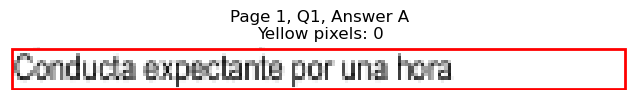

Page 1, Q1 - B: Detected box: x0=85.0, y0=145.3, x1=271.7, y1=157.4
Page 1, Q1, B: Yellow pixels: 0
Page 1, Q1, B: Total non-white pixels: 984
Page 1, Q1, B: Yellow percentage: 0.0%


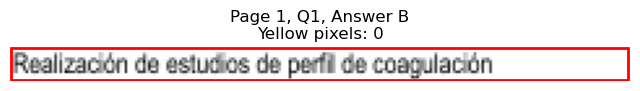

Page 1, Q1 - C: Detected box: x0=85.0, y0=157.3, x1=432.6, y1=169.4
Page 1, Q1, C: Yellow pixels: 0
Page 1, Q1, C: Total non-white pixels: 1762
Page 1, Q1, C: Yellow percentage: 0.0%


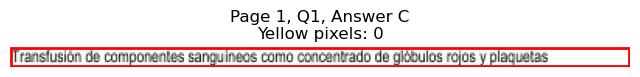

Page 1, Q1 - D: Detected box: x0=85.0, y0=169.4, x1=250.6, y1=181.5
Page 1, Q1, D: Yellow pixels: 217
Page 1, Q1, D: Total non-white pixels: 1039
Page 1, Q1, D: Yellow percentage: 20.9%


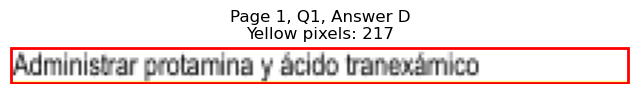

Page 1, Q1 - E: Detected box: x0=85.0, y0=181.4, x1=381.8, y1=193.5
Page 1, Q1, E: Yellow pixels: 3308
Page 1, Q1, E: Total non-white pixels: 4524
Page 1, Q1, E: Yellow percentage: 73.1%


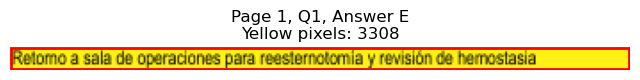


Page 1, Q1 - Selected Answer: E (based on yellow pixel count)




Page 1, Q2 - A: Detected box: x0=85.0, y0=217.5, x1=163.5, y1=229.7
Page 1, Q2, A: Yellow pixels: 0
Page 1, Q2, A: Total non-white pixels: 410
Page 1, Q2, A: Yellow percentage: 0.0%


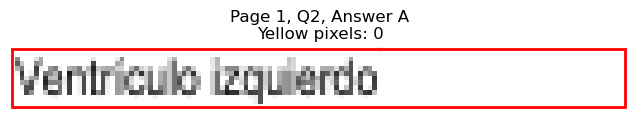

Page 1, Q2 - B: Detected box: x0=85.0, y0=229.7, x1=152.5, y1=241.8
Page 1, Q2, B: Yellow pixels: 0
Page 1, Q2, B: Total non-white pixels: 449
Page 1, Q2, B: Yellow percentage: 0.0%


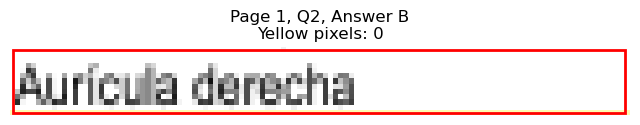

Page 1, Q2 - C: Detected box: x0=85.0, y0=241.7, x1=159.6, y1=253.8
Page 1, Q2, C: Yellow pixels: 1215
Page 1, Q2, C: Total non-white pixels: 1638
Page 1, Q2, C: Yellow percentage: 74.2%


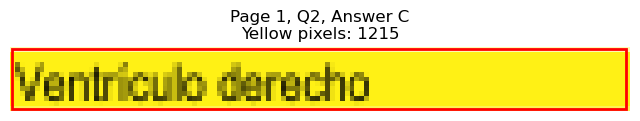

Page 1, Q2 - D: Detected box: x0=336.7, y0=217.5, x1=408.0, y1=229.7
Page 1, Q2, D: Yellow pixels: 0
Page 1, Q2, D: Total non-white pixels: 364
Page 1, Q2, D: Yellow percentage: 0.0%


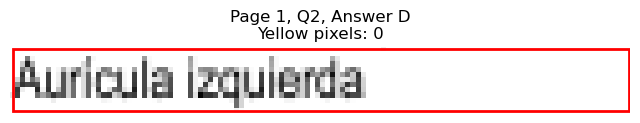

Page 1, Q2 - E: Detected box: x0=336.7, y0=229.7, x1=359.7, y1=241.8
Page 1, Q2, E: Yellow pixels: 0
Page 1, Q2, E: Total non-white pixels: 109
Page 1, Q2, E: Yellow percentage: 0.0%


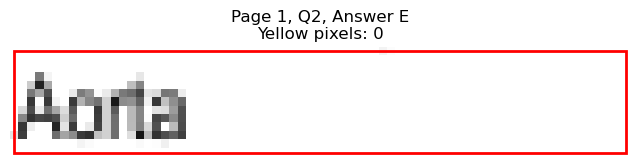


Page 1, Q2 - Selected Answer: C (based on yellow pixel count)




Page 1, Q3 - A: Detected box: x0=85.0, y0=313.9, x1=143.4, y1=326.0
Page 1, Q3, A: Yellow pixels: 0
Page 1, Q3, A: Total non-white pixels: 297
Page 1, Q3, A: Yellow percentage: 0.0%


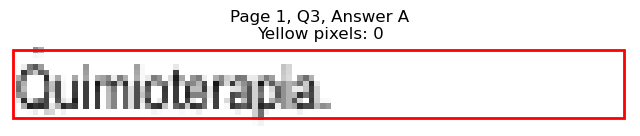

Page 1, Q3 - B: Detected box: x0=85.0, y0=326.1, x1=177.9, y1=338.2
Page 1, Q3, B: Yellow pixels: 0
Page 1, Q3, B: Total non-white pixels: 463
Page 1, Q3, B: Yellow percentage: 0.0%


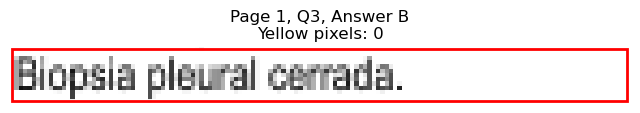

Page 1, Q3 - C: Detected box: x0=85.0, y0=338.1, x1=212.3, y1=350.2
Page 1, Q3, C: Yellow pixels: 0
Page 1, Q3, C: Total non-white pixels: 638
Page 1, Q3, C: Yellow percentage: 0.0%


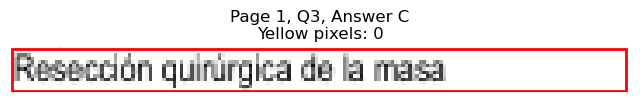

Page 1, Q3 - D: Detected box: x0=336.7, y0=313.9, x1=438.7, y1=326.0
Page 1, Q3, D: Yellow pixels: 1453
Page 1, Q3, D: Total non-white pixels: 2142
Page 1, Q3, D: Yellow percentage: 67.8%


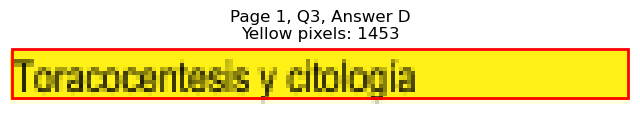

Page 1, Q3 - E: Detected box: x0=336.7, y0=326.1, x1=390.8, y1=338.2
Page 1, Q3, E: Yellow pixels: 0
Page 1, Q3, E: Total non-white pixels: 369
Page 1, Q3, E: Yellow percentage: 0.0%


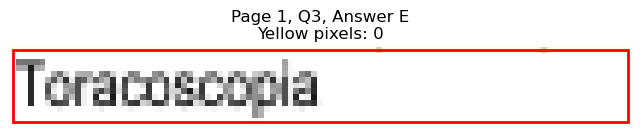


Page 1, Q3 - Selected Answer: D (based on yellow pixel count)




Page 1, Q4 - A: Detected box: x0=85.0, y0=386.3, x1=286.0, y1=398.4
Page 1, Q4, A: Yellow pixels: 0
Page 1, Q4, A: Total non-white pixels: 972
Page 1, Q4, A: Yellow percentage: 0.0%


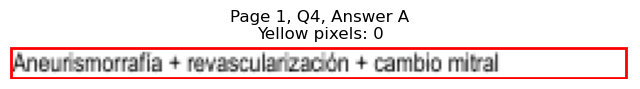

Page 1, Q4 - B: Detected box: x0=85.0, y0=398.3, x1=337.3, y1=410.4
Page 1, Q4, B: Yellow pixels: 0
Page 1, Q4, B: Total non-white pixels: 1225
Page 1, Q4, B: Yellow percentage: 0.0%


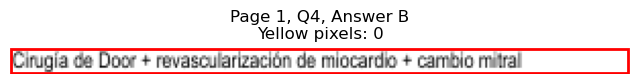

Page 1, Q4 - C: Detected box: x0=85.0, y0=410.4, x1=163.0, y1=422.5
Page 1, Q4, C: Yellow pixels: 0
Page 1, Q4, C: Total non-white pixels: 412
Page 1, Q4, C: Yellow percentage: 0.0%


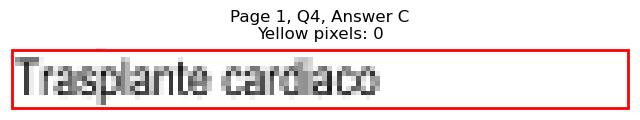

Page 1, Q4 - D: Detected box: x0=85.0, y0=422.4, x1=276.2, y1=434.5
Page 1, Q4, D: Yellow pixels: 243
Page 1, Q4, D: Total non-white pixels: 1176
Page 1, Q4, D: Yellow percentage: 20.7%


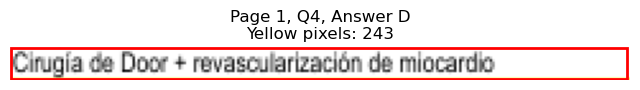

Page 1, Q4 - E: Detected box: x0=85.0, y0=434.4, x1=334.4, y1=446.5
Page 1, Q4, E: Yellow pixels: 2949
Page 1, Q4, E: Total non-white pixels: 3913
Page 1, Q4, E: Yellow percentage: 75.4%


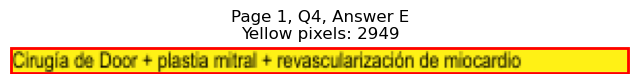


Page 1, Q4 - Selected Answer: E (based on yellow pixel count)




Page 1, Q5 - A: Detected box: x0=85.0, y0=482.7, x1=124.7, y1=494.8
Page 1, Q5, A: Yellow pixels: 0
Page 1, Q5, A: Total non-white pixels: 304
Page 1, Q5, A: Yellow percentage: 0.0%


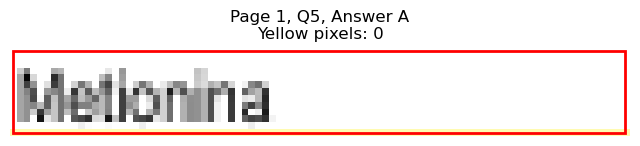

Page 1, Q5 - B: Detected box: x0=85.0, y0=494.7, x1=127.1, y1=506.8
Page 1, Q5, B: Yellow pixels: 965
Page 1, Q5, B: Total non-white pixels: 1222
Page 1, Q5, B: Yellow percentage: 79.0%


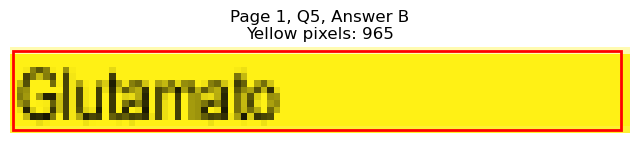

Page 1, Q5 - C: Detected box: x0=85.0, y0=506.8, x1=114.1, y1=518.9
Page 1, Q5, C: Yellow pixels: 81
Page 1, Q5, C: Total non-white pixels: 225
Page 1, Q5, C: Yellow percentage: 36.0%


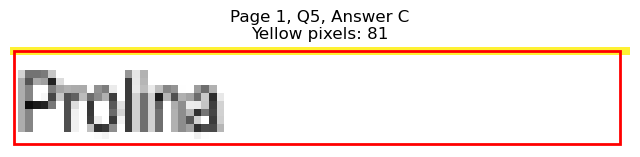

Page 1, Q5 - D: Detected box: x0=336.7, y0=482.7, x1=372.1, y1=494.8
Page 1, Q5, D: Yellow pixels: 0
Page 1, Q5, D: Total non-white pixels: 198
Page 1, Q5, D: Yellow percentage: 0.0%


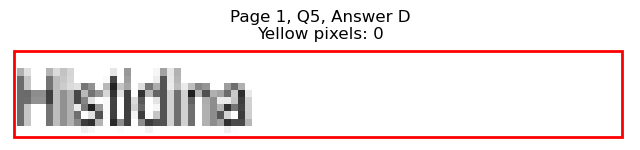

Page 1, Q5 - E: Detected box: x0=336.7, y0=494.7, x1=365.4, y1=506.8
Page 1, Q5, E: Yellow pixels: 0
Page 1, Q5, E: Total non-white pixels: 140
Page 1, Q5, E: Yellow percentage: 0.0%


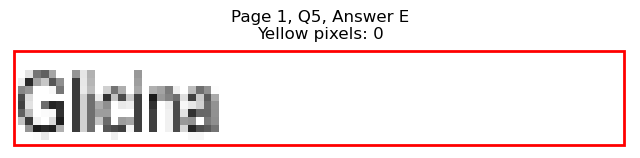


Page 1, Q5 - Selected Answer: B (based on yellow pixel count)




Page 1, Q6 - A: Detected box: x0=85.0, y0=567.1, x1=144.0, y1=579.2
Page 1, Q6, A: Yellow pixels: 0
Page 1, Q6, A: Total non-white pixels: 301
Page 1, Q6, A: Yellow percentage: 0.0%


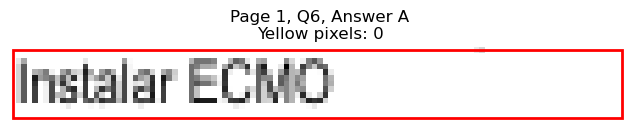

Page 1, Q6 - B: Detected box: x0=85.0, y0=579.1, x1=316.6, y1=591.2
Page 1, Q6, B: Yellow pixels: 0
Page 1, Q6, B: Total non-white pixels: 1166
Page 1, Q6, B: Yellow percentage: 0.0%


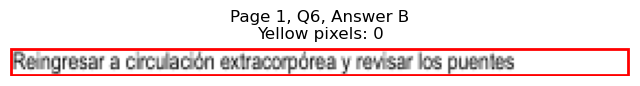

Page 1, Q6 - C: Detected box: x0=85.0, y0=591.2, x1=300.4, y1=603.3
Page 1, Q6, C: Yellow pixels: 267
Page 1, Q6, C: Total non-white pixels: 1346
Page 1, Q6, C: Yellow percentage: 19.8%


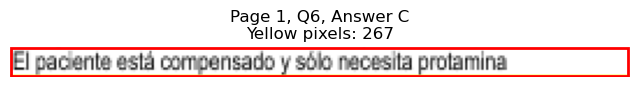

Page 1, Q6 - D: Detected box: x0=85.0, y0=603.2, x1=215.2, y1=615.3
Page 1, Q6, D: Yellow pixels: 1669
Page 1, Q6, D: Total non-white pixels: 2366
Page 1, Q6, D: Yellow percentage: 70.5%


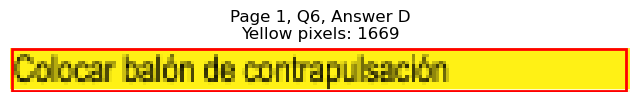

Page 1, Q6 - E: Detected box: x0=85.0, y0=615.2, x1=214.3, y1=627.3
Page 1, Q6, E: Yellow pixels: 0
Page 1, Q6, E: Total non-white pixels: 828
Page 1, Q6, E: Yellow percentage: 0.0%


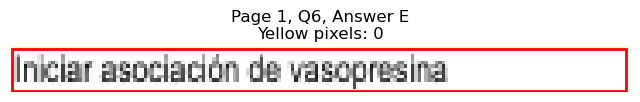


Page 1, Q6 - Selected Answer: D (based on yellow pixel count)




Page 1, Q7 - A: Detected box: x0=85.0, y0=651.4, x1=157.7, y1=663.5
Page 1, Q7, A: Yellow pixels: 0
Page 1, Q7, A: Total non-white pixels: 382
Page 1, Q7, A: Yellow percentage: 0.0%


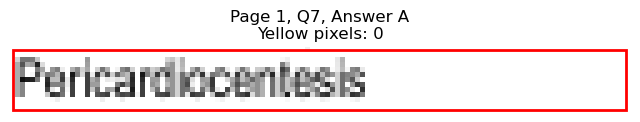

Page 1, Q7 - B: Detected box: x0=85.0, y0=663.4, x1=183.1, y1=675.5
Page 1, Q7, B: Yellow pixels: 150
Page 1, Q7, B: Total non-white pixels: 617
Page 1, Q7, B: Yellow percentage: 24.3%


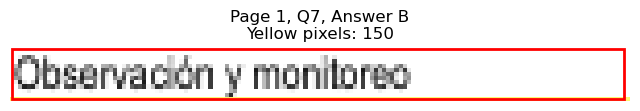

Page 1, Q7 - C: Detected box: x0=85.0, y0=675.4, x1=186.0, y1=687.5
Page 1, Q7, C: Yellow pixels: 1563
Page 1, Q7, C: Total non-white pixels: 1989
Page 1, Q7, C: Yellow percentage: 78.6%


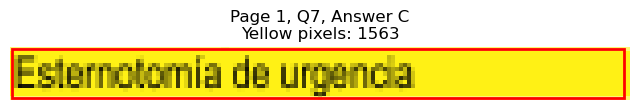

Page 1, Q7 - D: Detected box: x0=336.7, y0=651.4, x1=401.7, y1=663.5
Page 1, Q7, D: Yellow pixels: 0
Page 1, Q7, D: Total non-white pixels: 329
Page 1, Q7, D: Yellow percentage: 0.0%


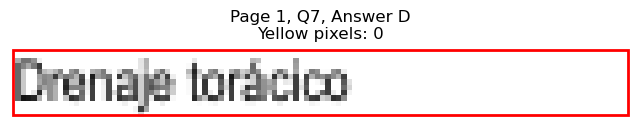

Page 1, Q7 - E: Detected box: x0=336.7, y0=663.4, x1=435.8, y1=675.5
Page 1, Q7, E: Yellow pixels: 0
Page 1, Q7, E: Total non-white pixels: 524
Page 1, Q7, E: Yellow percentage: 0.0%


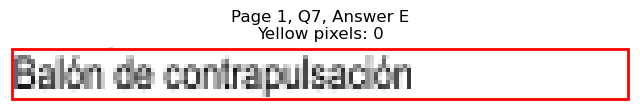


Page 1, Q7 - Selected Answer: C (based on yellow pixel count)




Page 1, Q8 - A: Detected box: x0=85.0, y0=735.8, x1=189.9, y1=747.9
Page 1, Q8, A: Yellow pixels: 0
Page 1, Q8, A: Total non-white pixels: 578
Page 1, Q8, A: Yellow percentage: 0.0%


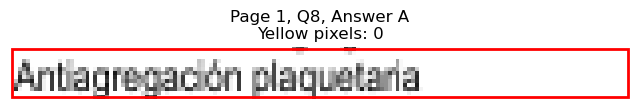

Page 1, Q8 - B: Detected box: x0=85.0, y0=747.8, x1=171.6, y1=759.9
Page 1, Q8, B: Yellow pixels: 0
Page 1, Q8, B: Total non-white pixels: 449
Page 1, Q8, B: Yellow percentage: 0.0%


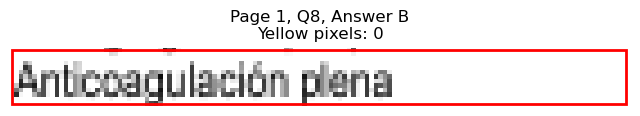

Page 1, Q8 - C: Detected box: x0=85.0, y0=759.8, x1=193.3, y1=771.9
Page 1, Q8, C: Yellow pixels: 0
Page 1, Q8, C: Total non-white pixels: 558
Page 1, Q8, C: Yellow percentage: 0.0%


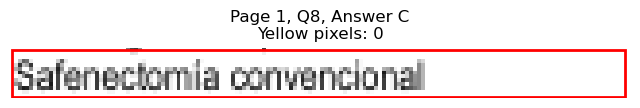

Page 1, Q8 - D: Detected box: x0=336.7, y0=735.8, x1=521.0, y1=747.9
Page 1, Q8, D: Yellow pixels: 1496
Page 1, Q8, D: Total non-white pixels: 2470
Page 1, Q8, D: Yellow percentage: 60.6%


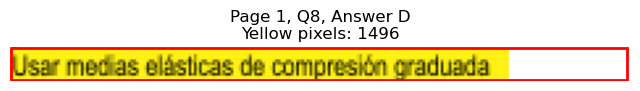

Page 1, Q8 - E: Detected box: x0=336.7, y0=747.8, x1=392.2, y1=759.9
Page 1, Q8, E: Yellow pixels: 107
Page 1, Q8, E: Total non-white pixels: 520
Page 1, Q8, E: Yellow percentage: 20.6%


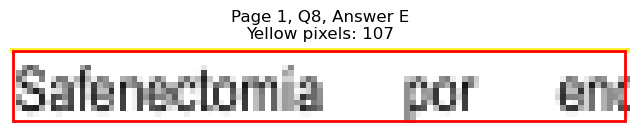


Page 1, Q8 - Selected Answer: D (based on yellow pixel count)





Page 2: Found 8 questions
Page 2, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=108.4, y1=109.2
Page 2, Q1, A: Yellow pixels: 0
Page 2, Q1, A: Total non-white pixels: 135
Page 2, Q1, A: Yellow percentage: 0.0%


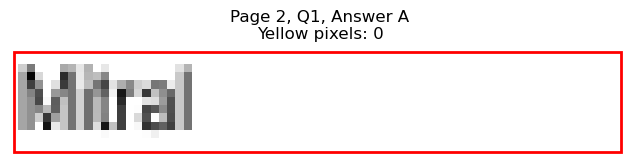

Page 2, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=114.1, y1=121.3
Page 2, Q1, B: Yellow pixels: 860
Page 2, Q1, B: Total non-white pixels: 1053
Page 2, Q1, B: Yellow percentage: 81.7%


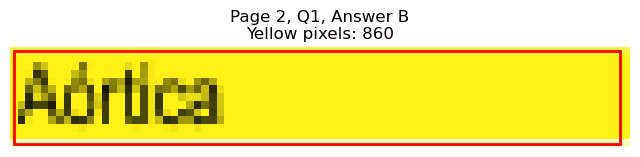

Page 2, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=127.1, y1=133.3
Page 2, Q1, C: Yellow pixels: 0
Page 2, Q1, C: Total non-white pixels: 320
Page 2, Q1, C: Yellow percentage: 0.0%


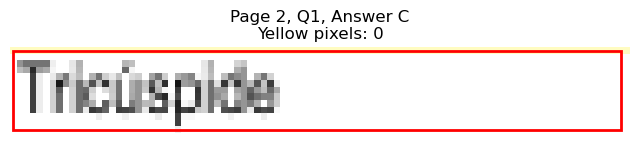

Page 2, Q1 - D: Detected box: x0=336.7, y0=97.1, x1=375.9, y1=109.2
Page 2, Q1, D: Yellow pixels: 0
Page 2, Q1, D: Total non-white pixels: 192
Page 2, Q1, D: Yellow percentage: 0.0%


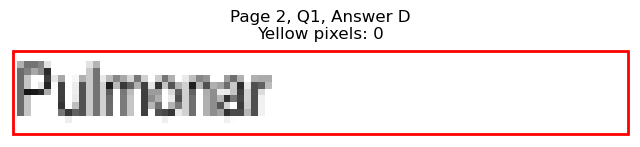

Page 2, Q1 - E: Detected box: x0=336.7, y0=109.2, x1=383.1, y1=121.3
Page 2, Q1, E: Yellow pixels: 0
Page 2, Q1, E: Total non-white pixels: 238
Page 2, Q1, E: Yellow percentage: 0.0%


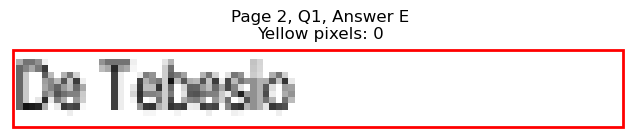


Page 2, Q1 - Selected Answer: B (based on yellow pixel count)




Page 2, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=200.8, y1=181.5
Page 2, Q2, A: Yellow pixels: 0
Page 2, Q2, A: Total non-white pixels: 614
Page 2, Q2, A: Yellow percentage: 0.0%


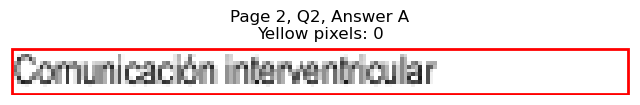

Page 2, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=163.0, y1=193.5
Page 2, Q2, B: Yellow pixels: 0
Page 2, Q2, B: Total non-white pixels: 395
Page 2, Q2, B: Yellow percentage: 0.0%


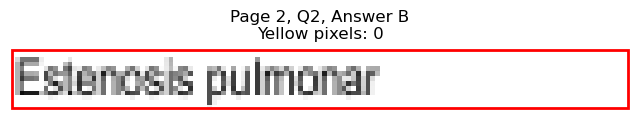

Page 2, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=158.7, y1=205.5
Page 2, Q2, C: Yellow pixels: 0
Page 2, Q2, C: Total non-white pixels: 394
Page 2, Q2, C: Yellow percentage: 0.0%


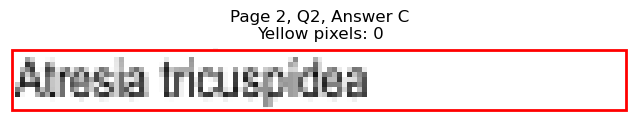

Page 2, Q2 - D: Detected box: x0=336.7, y0=169.4, x1=445.8, y1=181.5
Page 2, Q2, D: Yellow pixels: 1663
Page 2, Q2, D: Total non-white pixels: 2080
Page 2, Q2, D: Yellow percentage: 80.0%


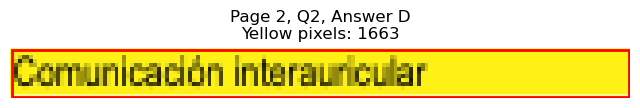

Page 2, Q2 - E: Detected box: x0=336.7, y0=181.4, x1=440.1, y1=193.5
Page 2, Q2, E: Yellow pixels: 155
Page 2, Q2, E: Total non-white pixels: 694
Page 2, Q2, E: Yellow percentage: 22.3%


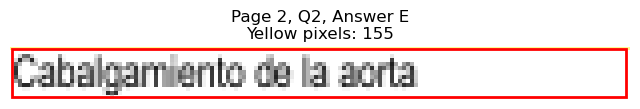


Page 2, Q2 - Selected Answer: D (based on yellow pixel count)




Page 2, Q3 - A: Detected box: x0=85.0, y0=229.7, x1=168.7, y1=241.8
Page 2, Q3, A: Yellow pixels: 1260
Page 2, Q3, A: Total non-white pixels: 1755
Page 2, Q3, A: Yellow percentage: 71.8%


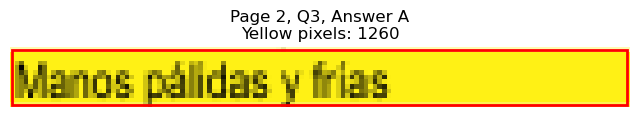

Page 2, Q3 - B: Detected box: x0=85.0, y0=241.7, x1=204.2, y1=253.8
Page 2, Q3, B: Yellow pixels: 167
Page 2, Q3, B: Total non-white pixels: 776
Page 2, Q3, B: Yellow percentage: 21.5%


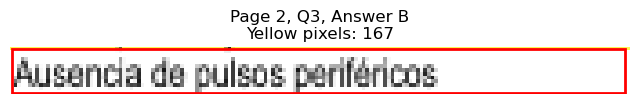

Page 2, Q3 - C: Detected box: x0=85.0, y0=253.7, x1=218.1, y1=265.8
Page 2, Q3, C: Yellow pixels: 0
Page 2, Q3, C: Total non-white pixels: 672
Page 2, Q3, C: Yellow percentage: 0.0%


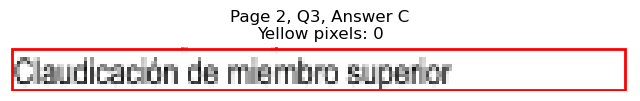

Page 2, Q3 - D: Detected box: x0=336.7, y0=229.7, x1=440.6, y1=241.8
Page 2, Q3, D: Yellow pixels: 0
Page 2, Q3, D: Total non-white pixels: 479
Page 2, Q3, D: Yellow percentage: 0.0%


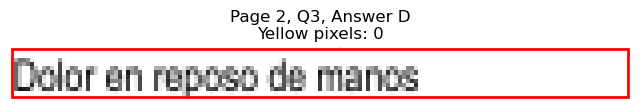

Page 2, Q3 - E: Detected box: x0=336.7, y0=241.7, x1=419.5, y1=253.8
Page 2, Q3, E: Yellow pixels: 0
Page 2, Q3, E: Total non-white pixels: 419
Page 2, Q3, E: Yellow percentage: 0.0%


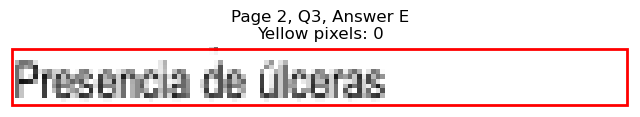


Page 2, Q3 - Selected Answer: A (based on yellow pixel count)




Page 2, Q4 - A: Detected box: x0=85.0, y0=326.1, x1=209.9, y1=338.2
Page 2, Q4, A: Yellow pixels: 0
Page 2, Q4, A: Total non-white pixels: 641
Page 2, Q4, A: Yellow percentage: 0.0%


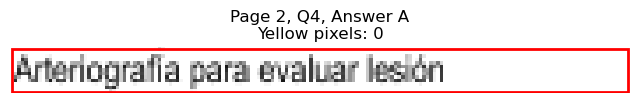

Page 2, Q4 - B: Detected box: x0=85.0, y0=338.1, x1=457.9, y1=350.2
Page 2, Q4, B: Yellow pixels: 0
Page 2, Q4, B: Total non-white pixels: 1877
Page 2, Q4, B: Yellow percentage: 0.0%


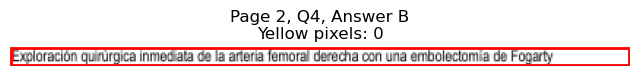

Page 2, Q4 - C: Detected box: x0=85.0, y0=350.2, x1=199.9, y1=362.3
Page 2, Q4, C: Yellow pixels: 1514
Page 2, Q4, C: Total non-white pixels: 2158
Page 2, Q4, C: Yellow percentage: 70.2%


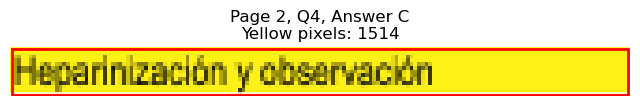

Page 2, Q4 - D: Detected box: x0=85.0, y0=362.2, x1=502.9, y1=374.3
Page 2, Q4, D: Yellow pixels: 0
Page 2, Q4, D: Total non-white pixels: 2524
Page 2, Q4, D: Yellow percentage: 0.0%


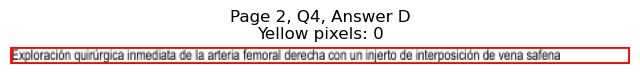

Page 2, Q4 - E: Detected box: x0=85.0, y0=374.2, x1=522.5, y1=386.3
Page 2, Q4, E: Yellow pixels: 0
Page 2, Q4, E: Total non-white pixels: 2243
Page 2, Q4, E: Yellow percentage: 0.0%


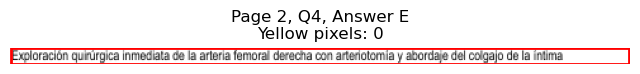


Page 2, Q4 - Selected Answer: C (based on yellow pixel count)




Page 2, Q5 - A: Detected box: x0=85.0, y0=410.4, x1=108.9, y1=422.5
Page 2, Q5, A: Yellow pixels: 75
Page 2, Q5, A: Total non-white pixels: 197
Page 2, Q5, A: Yellow percentage: 38.1%


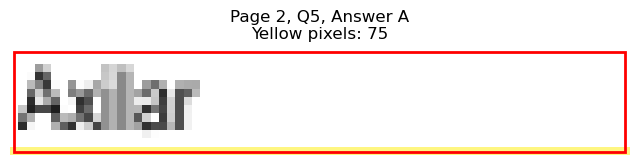

Page 2, Q5 - B: Detected box: x0=85.0, y0=422.4, x1=118.9, y1=434.5
Page 2, Q5, B: Yellow pixels: 953
Page 2, Q5, B: Total non-white pixels: 1105
Page 2, Q5, B: Yellow percentage: 86.2%


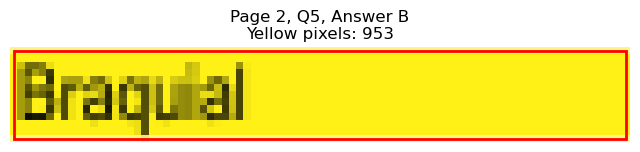

Page 2, Q5 - C: Detected box: x0=85.0, y0=434.4, x1=117.5, y1=446.5
Page 2, Q5, C: Yellow pixels: 84
Page 2, Q5, C: Total non-white pixels: 266
Page 2, Q5, C: Yellow percentage: 31.6%


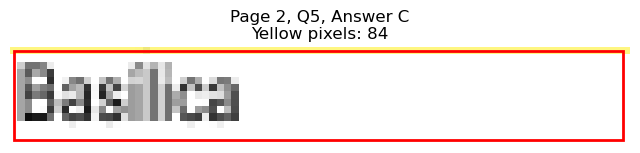

Page 2, Q5 - D: Detected box: x0=336.7, y0=410.4, x1=370.2, y1=422.5
Page 2, Q5, D: Yellow pixels: 0
Page 2, Q5, D: Total non-white pixels: 190
Page 2, Q5, D: Yellow percentage: 0.0%


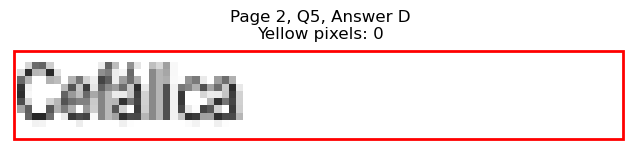

Page 2, Q5 - E: Detected box: x0=336.7, y0=422.4, x1=372.1, y1=434.5
Page 2, Q5, E: Yellow pixels: 0
Page 2, Q5, E: Total non-white pixels: 185
Page 2, Q5, E: Yellow percentage: 0.0%


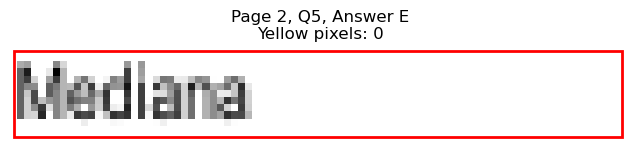


Page 2, Q5 - Selected Answer: B (based on yellow pixel count)




Page 2, Q6 - A: Detected box: x0=85.0, y0=470.7, x1=143.9, y1=482.8
Page 2, Q6, A: Yellow pixels: 0
Page 2, Q6, A: Total non-white pixels: 269
Page 2, Q6, A: Yellow percentage: 0.0%


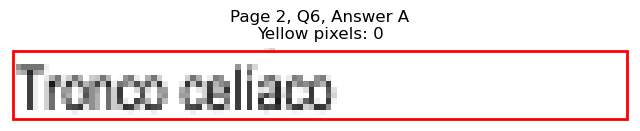

Page 2, Q6 - B: Detected box: x0=85.0, y0=482.7, x1=158.2, y1=494.8
Page 2, Q6, B: Yellow pixels: 0
Page 2, Q6, B: Total non-white pixels: 369
Page 2, Q6, B: Yellow percentage: 0.0%


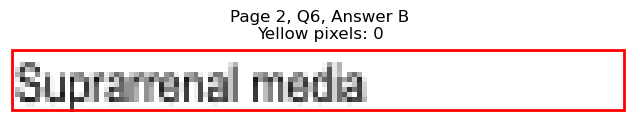

Page 2, Q6 - C: Detected box: x0=85.0, y0=494.7, x1=124.7, y1=506.8
Page 2, Q6, C: Yellow pixels: 0
Page 2, Q6, C: Total non-white pixels: 202
Page 2, Q6, C: Yellow percentage: 0.0%


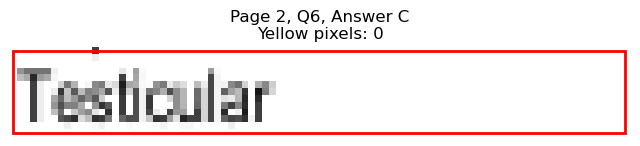

Page 2, Q6 - D: Detected box: x0=336.7, y0=470.7, x1=368.7, y1=482.8
Page 2, Q6, D: Yellow pixels: 0
Page 2, Q6, D: Total non-white pixels: 232
Page 2, Q6, D: Yellow percentage: 0.0%


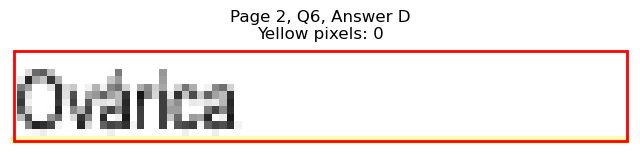

Page 2, Q6 - E: Detected box: x0=336.7, y0=482.7, x1=396.6, y1=494.8
Page 2, Q6, E: Yellow pixels: 1098
Page 2, Q6, E: Total non-white pixels: 1443
Page 2, Q6, E: Yellow percentage: 76.1%


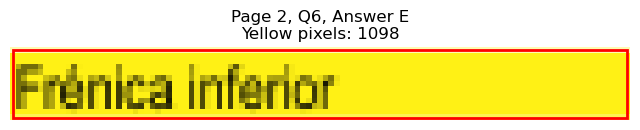


Page 2, Q6 - Selected Answer: E (based on yellow pixel count)




Page 2, Q7 - A: Detected box: x0=85.0, y0=567.1, x1=209.5, y1=579.2
Page 2, Q7, A: Yellow pixels: 0
Page 2, Q7, A: Total non-white pixels: 617
Page 2, Q7, A: Yellow percentage: 0.0%


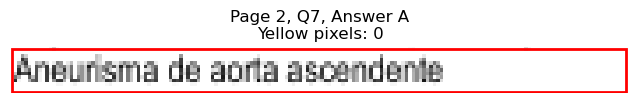

Page 2, Q7 - B: Detected box: x0=85.0, y0=579.1, x1=142.9, y1=591.2
Page 2, Q7, B: Yellow pixels: 0
Page 2, Q7, B: Total non-white pixels: 309
Page 2, Q7, B: Yellow percentage: 0.0%


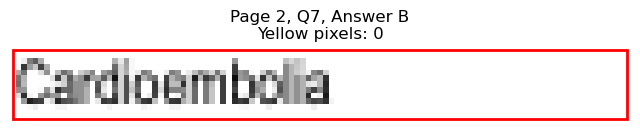

Page 2, Q7 - C: Detected box: x0=85.0, y0=591.2, x1=163.0, y1=603.3
Page 2, Q7, C: Yellow pixels: 0
Page 2, Q7, C: Total non-white pixels: 397
Page 2, Q7, C: Yellow percentage: 0.0%


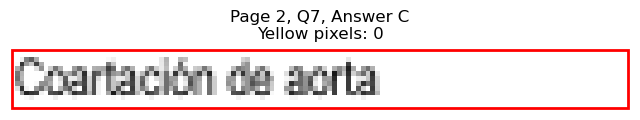

Page 2, Q7 - D: Detected box: x0=336.7, y0=567.1, x1=420.0, y1=579.2
Page 2, Q7, D: Yellow pixels: 1295
Page 2, Q7, D: Total non-white pixels: 1742
Page 2, Q7, D: Yellow percentage: 74.3%


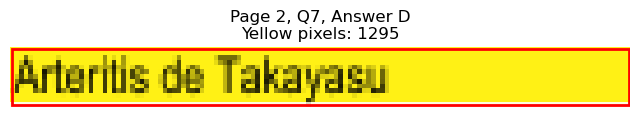

Page 2, Q7 - E: Detected box: x0=336.7, y0=579.1, x1=431.5, y1=591.2
Page 2, Q7, E: Yellow pixels: 0
Page 2, Q7, E: Total non-white pixels: 648
Page 2, Q7, E: Yellow percentage: 0.0%


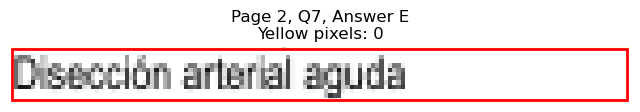


Page 2, Q7 - Selected Answer: D (based on yellow pixel count)




Page 2, Q8 - A: Detected box: x0=85.0, y0=675.4, x1=203.2, y1=687.5
Page 2, Q8, A: Yellow pixels: 0
Page 2, Q8, A: Total non-white pixels: 579
Page 2, Q8, A: Yellow percentage: 0.0%


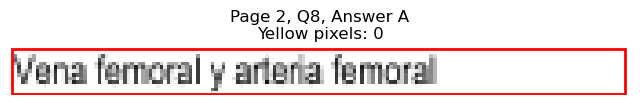

Page 2, Q8 - B: Detected box: x0=85.0, y0=687.5, x1=203.2, y1=699.7
Page 2, Q8, B: Yellow pixels: 170
Page 2, Q8, B: Total non-white pixels: 759
Page 2, Q8, B: Yellow percentage: 22.4%


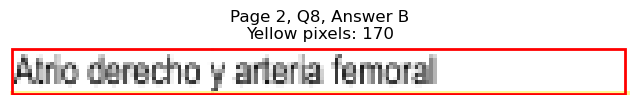

Page 2, Q8 - C: Detected box: x0=85.0, y0=699.5, x1=214.3, y1=711.7
Page 2, Q8, C: Yellow pixels: 1829
Page 2, Q8, C: Total non-white pixels: 2353
Page 2, Q8, C: Yellow percentage: 77.7%


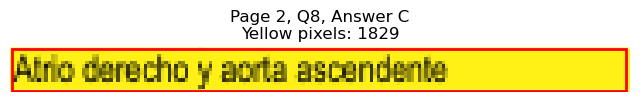

Page 2, Q8 - D: Detected box: x0=336.7, y0=675.4, x1=454.4, y1=687.5
Page 2, Q8, D: Yellow pixels: 0
Page 2, Q8, D: Total non-white pixels: 554
Page 2, Q8, D: Yellow percentage: 0.0%


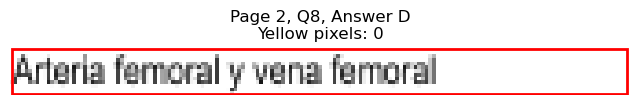

Page 2, Q8 - E: Detected box: x0=336.7, y0=687.5, x1=459.7, y1=699.7
Page 2, Q8, E: Yellow pixels: 0
Page 2, Q8, E: Total non-white pixels: 601
Page 2, Q8, E: Yellow percentage: 0.0%


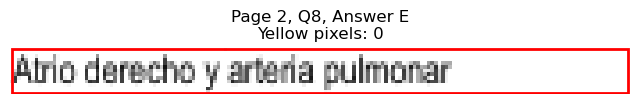


Page 2, Q8 - Selected Answer: C (based on yellow pixel count)





Page 3: Found 8 questions
Page 3, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=526.7, y1=109.2
Page 3, Q1, A: Yellow pixels: 3632
Page 3, Q1, A: Total non-white pixels: 5746
Page 3, Q1, A: Yellow percentage: 63.2%


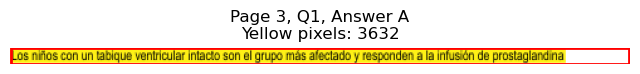

Page 3, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=287.0, y1=133.3
Page 3, Q1, B: Yellow pixels: 0
Page 3, Q1, B: Total non-white pixels: 1283
Page 3, Q1, B: Yellow percentage: 0.0%


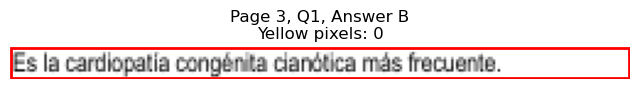

Page 3, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=271.7, y1=145.3
Page 3, Q1, C: Yellow pixels: 0
Page 3, Q1, C: Total non-white pixels: 930
Page 3, Q1, C: Yellow percentage: 0.0%


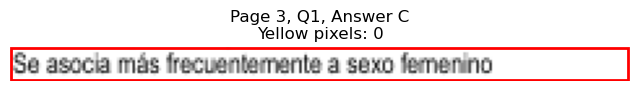

Page 3, Q1 - D: Detected box: x0=85.0, y0=145.3, x1=373.2, y1=157.4
Page 3, Q1, D: Yellow pixels: 0
Page 3, Q1, D: Total non-white pixels: 1393
Page 3, Q1, D: Yellow percentage: 0.0%


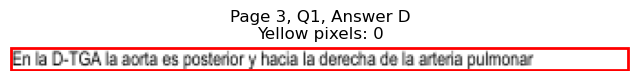

Page 3, Q1 - E: Detected box: x0=85.0, y0=157.3, x1=304.3, y1=169.4
Page 3, Q1, E: Yellow pixels: 0
Page 3, Q1, E: Total non-white pixels: 1051
Page 3, Q1, E: Yellow percentage: 0.0%


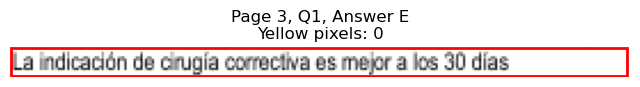


Page 3, Q1 - Selected Answer: A (based on yellow pixel count)




Page 3, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=117.5, y1=205.5
Page 3, Q2, A: Yellow pixels: 0
Page 3, Q2, A: Total non-white pixels: 188
Page 3, Q2, A: Yellow percentage: 0.0%


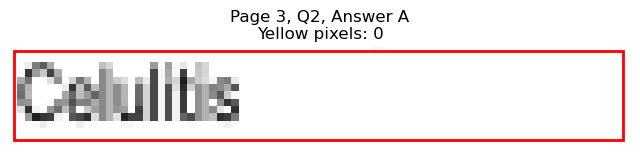

Page 3, Q2 - B: Detected box: x0=85.0, y0=205.5, x1=136.7, y1=217.7
Page 3, Q2, B: Yellow pixels: 0
Page 3, Q2, B: Total non-white pixels: 268
Page 3, Q2, B: Yellow percentage: 0.0%


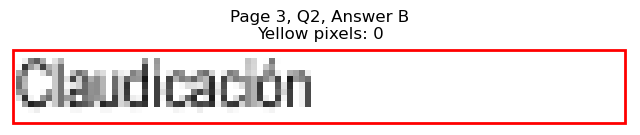

Page 3, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=185.5, y1=229.7
Page 3, Q2, C: Yellow pixels: 0
Page 3, Q2, C: Total non-white pixels: 512
Page 3, Q2, C: Yellow percentage: 0.0%


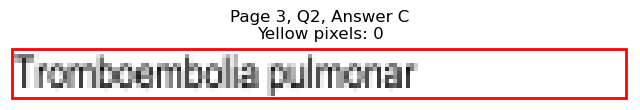

Page 3, Q2 - D: Detected box: x0=336.7, y0=193.4, x1=400.8, y1=205.5
Page 3, Q2, D: Yellow pixels: 1233
Page 3, Q2, D: Total non-white pixels: 1495
Page 3, Q2, D: Yellow percentage: 82.5%


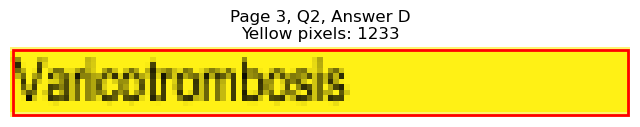

Page 3, Q2 - E: Detected box: x0=336.7, y0=205.5, x1=445.9, y1=217.7
Page 3, Q2, E: Yellow pixels: 160
Page 3, Q2, E: Total non-white pixels: 686
Page 3, Q2, E: Yellow percentage: 23.3%


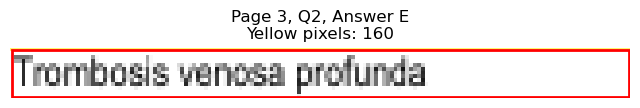


Page 3, Q2 - Selected Answer: D (based on yellow pixel count)




Page 3, Q3 - A: Detected box: x0=85.0, y0=301.9, x1=444.5, y1=314.0
Page 3, Q3, A: Yellow pixels: 0
Page 3, Q3, A: Total non-white pixels: 1816
Page 3, Q3, A: Yellow percentage: 0.0%


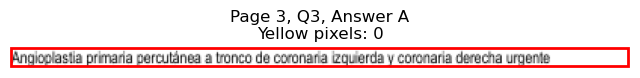

Page 3, Q3 - B: Detected box: x0=85.0, y0=313.9, x1=449.7, y1=326.0
Page 3, Q3, B: Yellow pixels: 0
Page 3, Q3, B: Total non-white pixels: 1875
Page 3, Q3, B: Yellow percentage: 0.0%


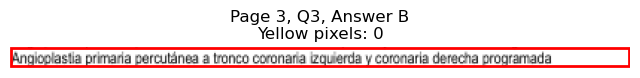

Page 3, Q3 - C: Detected box: x0=85.0, y0=326.1, x1=271.7, y1=338.2
Page 3, Q3, C: Yellow pixels: 0
Page 3, Q3, C: Total non-white pixels: 1000
Page 3, Q3, C: Yellow percentage: 0.0%


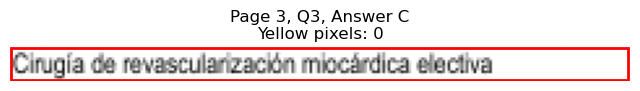

Page 3, Q3 - D: Detected box: x0=85.0, y0=338.1, x1=251.1, y1=350.2
Page 3, Q3, D: Yellow pixels: 0
Page 3, Q3, D: Total non-white pixels: 817
Page 3, Q3, D: Yellow percentage: 0.0%


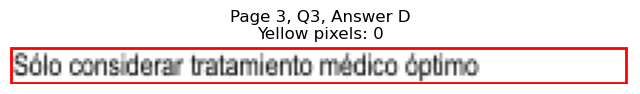

Page 3, Q3 - E: Detected box: x0=85.0, y0=350.2, x1=271.7, y1=362.3
Page 3, Q3, E: Yellow pixels: 2053
Page 3, Q3, E: Total non-white pixels: 3094
Page 3, Q3, E: Yellow percentage: 66.4%


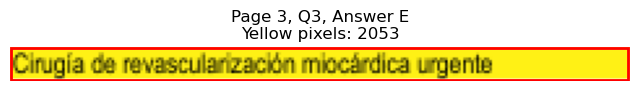


Page 3, Q3 - Selected Answer: E (based on yellow pixel count)




Page 3, Q4 - A: Detected box: x0=85.0, y0=398.3, x1=139.1, y1=410.4
Page 3, Q4, A: Yellow pixels: 0
Page 3, Q4, A: Total non-white pixels: 280
Page 3, Q4, A: Yellow percentage: 0.0%


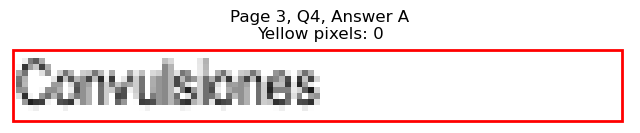

Page 3, Q4 - B: Detected box: x0=85.0, y0=410.4, x1=140.5, y1=422.5
Page 3, Q4, B: Yellow pixels: 1161
Page 3, Q4, B: Total non-white pixels: 1391
Page 3, Q4, B: Yellow percentage: 83.5%


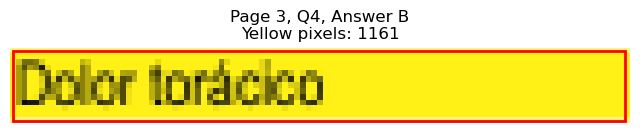

Page 3, Q4 - C: Detected box: x0=85.0, y0=422.4, x1=114.1, y1=434.5
Page 3, Q4, C: Yellow pixels: 81
Page 3, Q4, C: Total non-white pixels: 233
Page 3, Q4, C: Yellow percentage: 34.8%


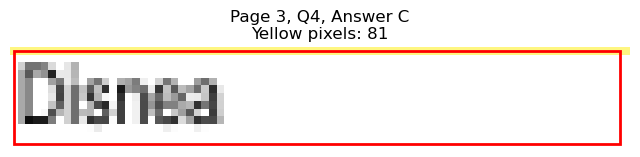

Page 3, Q4 - D: Detected box: x0=336.7, y0=398.3, x1=390.3, y1=410.4
Page 3, Q4, D: Yellow pixels: 0
Page 3, Q4, D: Total non-white pixels: 298
Page 3, Q4, D: Yellow percentage: 0.0%


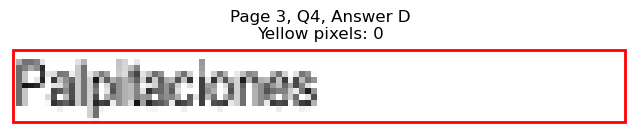

Page 3, Q4 - E: Detected box: x0=336.7, y0=410.4, x1=370.6, y1=422.5
Page 3, Q4, E: Yellow pixels: 0
Page 3, Q4, E: Total non-white pixels: 172
Page 3, Q4, E: Yellow percentage: 0.0%


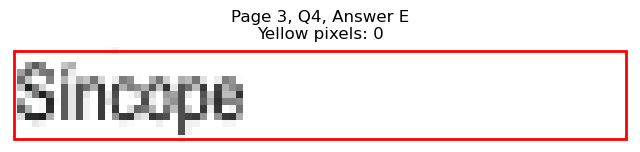


Page 3, Q4 - Selected Answer: B (based on yellow pixel count)




Page 3, Q5 - A: Detected box: x0=85.0, y0=470.7, x1=222.9, y1=482.8
Page 3, Q5, A: Yellow pixels: 0
Page 3, Q5, A: Total non-white pixels: 670
Page 3, Q5, A: Yellow percentage: 0.0%


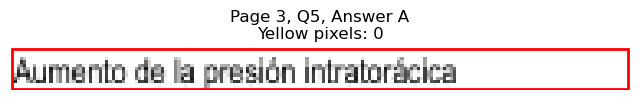

Page 3, Q5 - B: Detected box: x0=85.0, y0=482.7, x1=246.8, y1=494.8
Page 3, Q5, B: Yellow pixels: 0
Page 3, Q5, B: Total non-white pixels: 989
Page 3, Q5, B: Yellow percentage: 0.0%


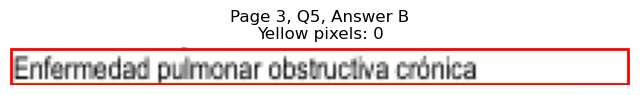

Page 3, Q5 - C: Detected box: x0=85.0, y0=494.7, x1=270.3, y1=506.8
Page 3, Q5, C: Yellow pixels: 1541
Page 3, Q5, C: Total non-white pixels: 2483
Page 3, Q5, C: Yellow percentage: 62.1%


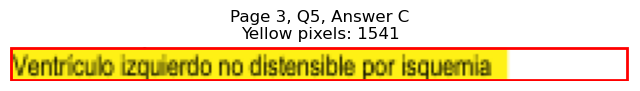

Page 3, Q5 - D: Detected box: x0=336.7, y0=470.7, x1=510.9, y1=482.8
Page 3, Q5, D: Yellow pixels: 0
Page 3, Q5, D: Total non-white pixels: 844
Page 3, Q5, D: Yellow percentage: 0.0%


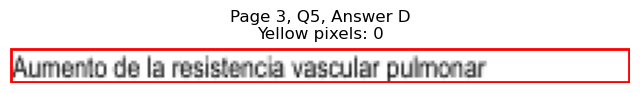

Page 3, Q5 - E: Detected box: x0=336.7, y0=482.7, x1=441.9, y1=494.8
Page 3, Q5, E: Yellow pixels: 0
Page 3, Q5, E: Total non-white pixels: 541
Page 3, Q5, E: Yellow percentage: 0.0%


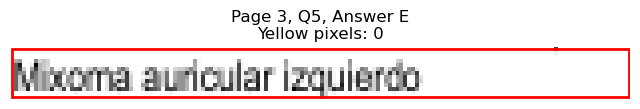


Page 3, Q5 - Selected Answer: C (based on yellow pixel count)




Page 3, Q6 - A: Detected box: x0=85.0, y0=542.9, x1=371.2, y1=555.0
Page 3, Q6, A: Yellow pixels: 2872
Page 3, Q6, A: Total non-white pixels: 4403
Page 3, Q6, A: Yellow percentage: 65.2%


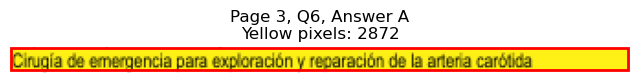

Page 3, Q6 - B: Detected box: x0=85.0, y0=554.9, x1=180.7, y1=567.0
Page 3, Q6, B: Yellow pixels: 136
Page 3, Q6, B: Total non-white pixels: 680
Page 3, Q6, B: Yellow percentage: 20.0%


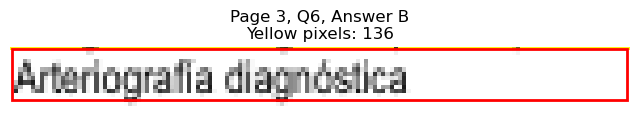

Page 3, Q6 - C: Detected box: x0=85.0, y0=567.1, x1=361.2, y1=579.2
Page 3, Q6, C: Yellow pixels: 0
Page 3, Q6, C: Total non-white pixels: 1430
Page 3, Q6, C: Yellow percentage: 0.0%


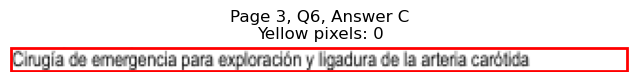

Page 3, Q6 - D: Detected box: x0=85.0, y0=579.1, x1=169.2, y1=591.2
Page 3, Q6, D: Yellow pixels: 0
Page 3, Q6, D: Total non-white pixels: 441
Page 3, Q6, D: Yellow percentage: 0.0%


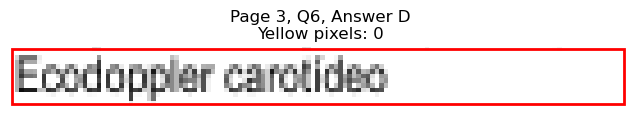

Page 3, Q6 - E: Detected box: x0=85.0, y0=591.2, x1=169.2, y1=603.3
Page 3, Q6, E: Yellow pixels: 0
Page 3, Q6, E: Total non-white pixels: 434
Page 3, Q6, E: Yellow percentage: 0.0%


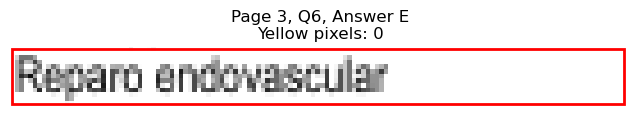


Page 3, Q6 - Selected Answer: A (based on yellow pixel count)




Page 3, Q7 - A: Detected box: x0=85.0, y0=627.3, x1=187.0, y1=639.4
Page 3, Q7, A: Yellow pixels: 0
Page 3, Q7, A: Total non-white pixels: 529
Page 3, Q7, A: Yellow percentage: 0.0%


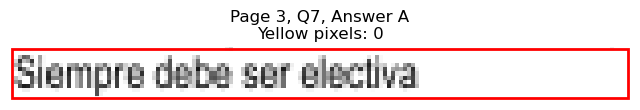

Page 3, Q7 - B: Detected box: x0=85.0, y0=639.3, x1=322.4, y1=651.4
Page 3, Q7, B: Yellow pixels: 0
Page 3, Q7, B: Total non-white pixels: 1198
Page 3, Q7, B: Yellow percentage: 0.0%


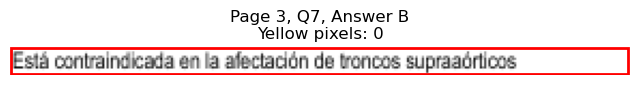

Page 3, Q7 - C: Detected box: x0=85.0, y0=651.4, x1=334.9, y1=663.5
Page 3, Q7, C: Yellow pixels: 2901
Page 3, Q7, C: Total non-white pixels: 3913
Page 3, Q7, C: Yellow percentage: 74.1%


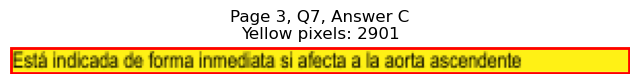

Page 3, Q7 - D: Detected box: x0=85.0, y0=663.4, x1=288.4, y1=675.5
Page 3, Q7, D: Yellow pixels: 255
Page 3, Q7, D: Total non-white pixels: 1299
Page 3, Q7, D: Yellow percentage: 19.6%


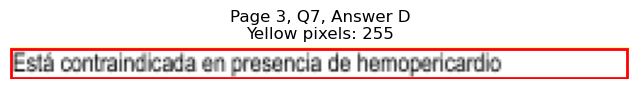

Page 3, Q7 - E: Detected box: x0=85.0, y0=675.4, x1=344.0, y1=687.5
Page 3, Q7, E: Yellow pixels: 0
Page 3, Q7, E: Total non-white pixels: 1312
Page 3, Q7, E: Yellow percentage: 0.0%


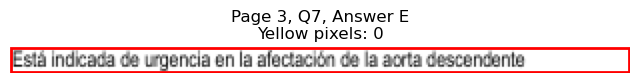


Page 3, Q7 - Selected Answer: C (based on yellow pixel count)




Page 3, Q8 - A: Detected box: x0=85.0, y0=747.8, x1=200.8, y1=759.9
Page 3, Q8, A: Yellow pixels: 0
Page 3, Q8, A: Total non-white pixels: 625
Page 3, Q8, A: Yellow percentage: 0.0%


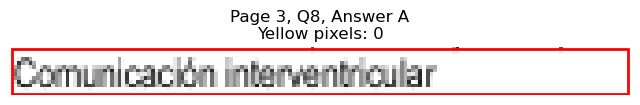

Page 3, Q8 - B: Detected box: x0=85.0, y0=759.8, x1=194.1, y1=771.9
Page 3, Q8, B: Yellow pixels: 0
Page 3, Q8, B: Total non-white pixels: 564
Page 3, Q8, B: Yellow percentage: 0.0%


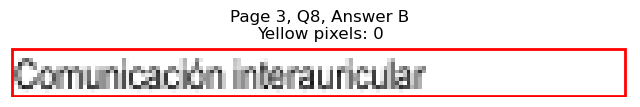

Page 3, Q8 - C: Detected box: x0=85.0, y0=771.9, x1=192.8, y1=784.0
Page 3, Q8, C: Yellow pixels: 0
Page 3, Q8, C: Total non-white pixels: 565
Page 3, Q8, C: Yellow percentage: 0.0%


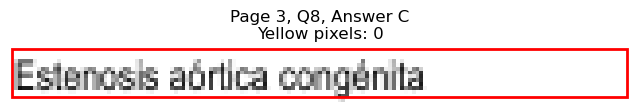

Page 3, Q8 - D: Detected box: x0=336.7, y0=747.8, x1=425.7, y1=759.9
Page 3, Q8, D: Yellow pixels: 0
Page 3, Q8, D: Total non-white pixels: 591
Page 3, Q8, D: Yellow percentage: 0.0%


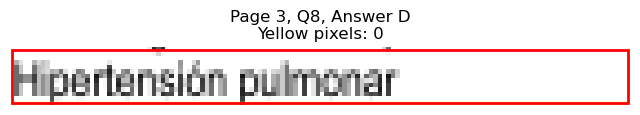

Page 3, Q8 - E: Detected box: x0=336.7, y0=759.8, x1=444.4, y1=771.9
Page 3, Q8, E: Yellow pixels: 1445
Page 3, Q8, E: Total non-white pixels: 2067
Page 3, Q8, E: Yellow percentage: 69.9%


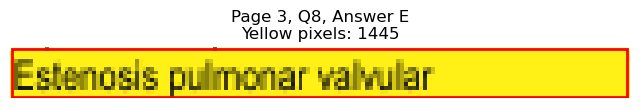


Page 3, Q8 - Selected Answer: E (based on yellow pixel count)





Page 4: Found 9 questions
Page 4, Q1 - A: Detected box: x0=85.0, y0=121.2, x1=134.8, y1=133.3
Page 4, Q1, A: Yellow pixels: 101
Page 4, Q1, A: Total non-white pixels: 342
Page 4, Q1, A: Yellow percentage: 29.5%


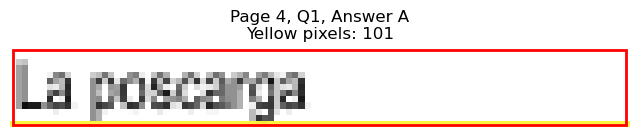

Page 4, Q1 - B: Detected box: x0=85.0, y0=133.2, x1=151.5, y1=145.3
Page 4, Q1, B: Yellow pixels: 1152
Page 4, Q1, B: Total non-white pixels: 1534
Page 4, Q1, B: Yellow percentage: 75.1%


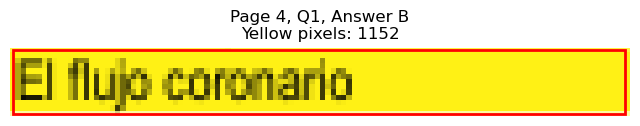

Page 4, Q1 - C: Detected box: x0=85.0, y0=145.3, x1=150.1, y1=157.4
Page 4, Q1, C: Yellow pixels: 1
Page 4, Q1, C: Total non-white pixels: 449
Page 4, Q1, C: Yellow percentage: 0.2%


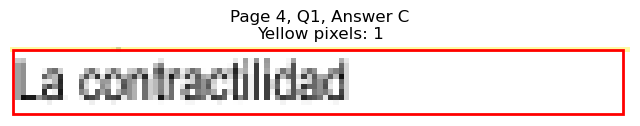

Page 4, Q1 - D: Detected box: x0=336.7, y0=121.2, x1=430.0, y1=133.3
Page 4, Q1, D: Yellow pixels: 0
Page 4, Q1, D: Total non-white pixels: 498
Page 4, Q1, D: Yellow percentage: 0.0%


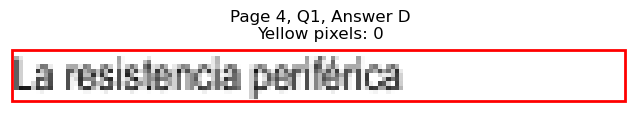

Page 4, Q1 - E: Detected box: x0=336.7, y0=133.2, x1=385.0, y1=145.3
Page 4, Q1, E: Yellow pixels: 0
Page 4, Q1, E: Total non-white pixels: 237
Page 4, Q1, E: Yellow percentage: 0.0%


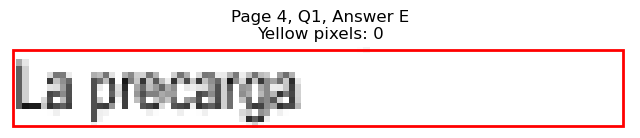


Page 4, Q1 - Selected Answer: B (based on yellow pixel count)




Page 4, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=281.3, y1=193.5
Page 4, Q2, A: Yellow pixels: 248
Page 4, Q2, A: Total non-white pixels: 1175
Page 4, Q2, A: Yellow percentage: 21.1%


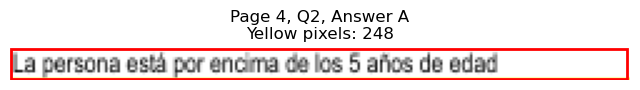

Page 4, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=378.0, y1=205.5
Page 4, Q2, B: Yellow pixels: 3266
Page 4, Q2, B: Total non-white pixels: 4472
Page 4, Q2, B: Yellow percentage: 73.0%


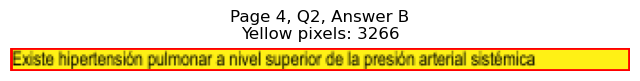

Page 4, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=290.3, y1=217.7
Page 4, Q2, C: Yellow pixels: 257
Page 4, Q2, C: Total non-white pixels: 1272
Page 4, Q2, C: Yellow percentage: 20.2%


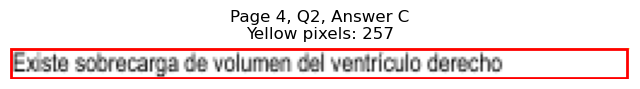

Page 4, Q2 - D: Detected box: x0=85.0, y0=217.5, x1=236.2, y1=229.7
Page 4, Q2, D: Yellow pixels: 0
Page 4, Q2, D: Total non-white pixels: 795
Page 4, Q2, D: Yellow percentage: 0.0%


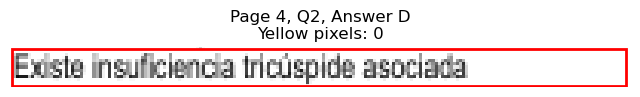

Page 4, Q2 - E: Detected box: x0=85.0, y0=229.7, x1=295.1, y1=241.8
Page 4, Q2, E: Yellow pixels: 0
Page 4, Q2, E: Total non-white pixels: 1025
Page 4, Q2, E: Yellow percentage: 0.0%


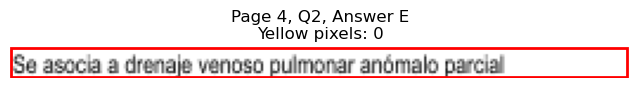


Page 4, Q2 - Selected Answer: B (based on yellow pixel count)




Page 4, Q3 - A: Detected box: x0=85.0, y0=277.8, x1=188.9, y1=289.9
Page 4, Q3, A: Yellow pixels: 0
Page 4, Q3, A: Total non-white pixels: 544
Page 4, Q3, A: Yellow percentage: 0.0%


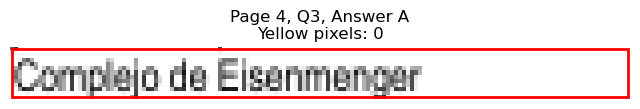

Page 4, Q3 - B: Detected box: x0=85.0, y0=289.9, x1=200.8, y1=302.0
Page 4, Q3, B: Yellow pixels: 0
Page 4, Q3, B: Total non-white pixels: 629
Page 4, Q3, B: Yellow percentage: 0.0%


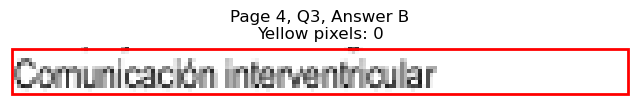

Page 4, Q3 - C: Detected box: x0=85.0, y0=301.9, x1=194.1, y1=314.0
Page 4, Q3, C: Yellow pixels: 0
Page 4, Q3, C: Total non-white pixels: 564
Page 4, Q3, C: Yellow percentage: 0.0%


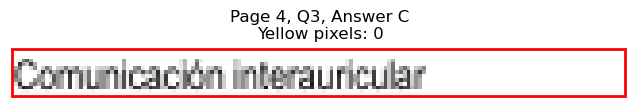

Page 4, Q3 - D: Detected box: x0=336.7, y0=277.8, x1=413.2, y1=289.9
Page 4, Q3, D: Yellow pixels: 0
Page 4, Q3, D: Total non-white pixels: 388
Page 4, Q3, D: Yellow percentage: 0.0%


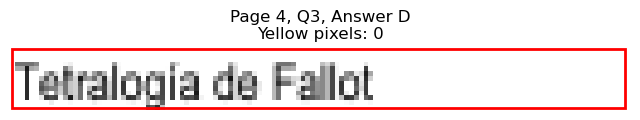

Page 4, Q3 - E: Detected box: x0=336.7, y0=289.9, x1=414.7, y1=302.0
Page 4, Q3, E: Yellow pixels: 1265
Page 4, Q3, E: Total non-white pixels: 1677
Page 4, Q3, E: Yellow percentage: 75.4%


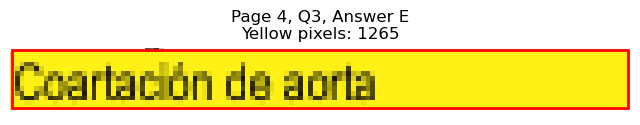


Page 4, Q3 - Selected Answer: E (based on yellow pixel count)




Page 4, Q4 - A: Detected box: x0=85.0, y0=338.1, x1=135.3, y1=350.2
Page 4, Q4, A: Yellow pixels: 0
Page 4, Q4, A: Total non-white pixels: 287
Page 4, Q4, A: Yellow percentage: 0.0%


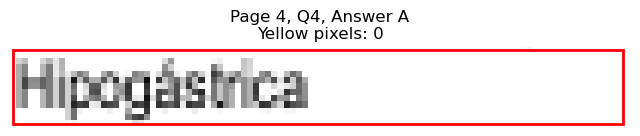

Page 4, Q4 - B: Detected box: x0=85.0, y0=350.2, x1=107.5, y1=362.3
Page 4, Q4, B: Yellow pixels: 0
Page 4, Q4, B: Total non-white pixels: 121
Page 4, Q4, B: Yellow percentage: 0.0%


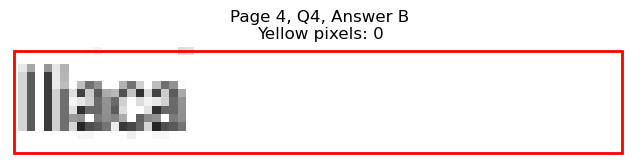

Page 4, Q4 - C: Detected box: x0=85.0, y0=362.2, x1=163.0, y1=374.3
Page 4, Q4, C: Yellow pixels: 0
Page 4, Q4, C: Total non-white pixels: 426
Page 4, Q4, C: Yellow percentage: 0.0%


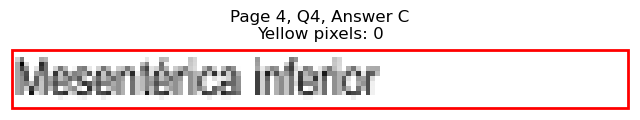

Page 4, Q4 - D: Detected box: x0=336.7, y0=338.1, x1=395.1, y1=350.2
Page 4, Q4, D: Yellow pixels: 1099
Page 4, Q4, D: Total non-white pixels: 1430
Page 4, Q4, D: Yellow percentage: 76.9%


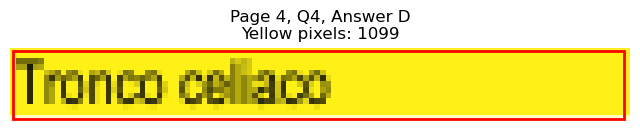

Page 4, Q4 - E: Detected box: x0=336.7, y0=350.2, x1=361.5, y1=362.3
Page 4, Q4, E: Yellow pixels: 0
Page 4, Q4, E: Total non-white pixels: 205
Page 4, Q4, E: Yellow percentage: 0.0%


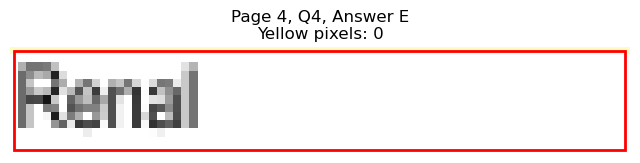


Page 4, Q4 - Selected Answer: D (based on yellow pixel count)




Page 4, Q5 - A: Detected box: x0=85.0, y0=398.3, x1=122.3, y1=410.4
Page 4, Q5, A: Yellow pixels: 1012
Page 4, Q5, A: Total non-white pixels: 1157
Page 4, Q5, A: Yellow percentage: 87.5%


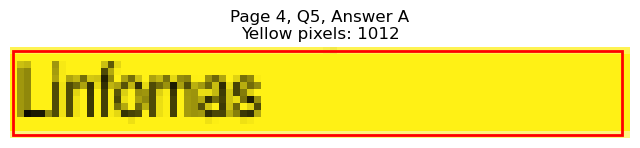

Page 4, Q5 - B: Detected box: x0=85.0, y0=410.4, x1=129.0, y1=422.5
Page 4, Q5, B: Yellow pixels: 96
Page 4, Q5, B: Total non-white pixels: 320
Page 4, Q5, B: Yellow percentage: 30.0%


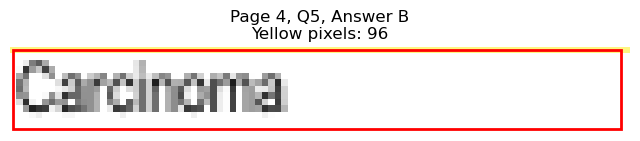

Page 4, Q5 - C: Detected box: x0=85.0, y0=422.4, x1=165.9, y1=434.5
Page 4, Q5, C: Yellow pixels: 0
Page 4, Q5, C: Total non-white pixels: 415
Page 4, Q5, C: Yellow percentage: 0.0%


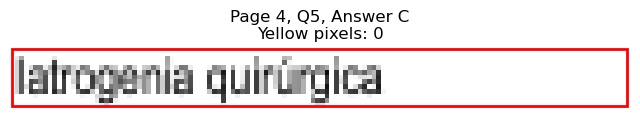

Page 4, Q5 - D: Detected box: x0=336.7, y0=398.3, x1=421.9, y1=410.4
Page 4, Q5, D: Yellow pixels: 0
Page 4, Q5, D: Total non-white pixels: 398
Page 4, Q5, D: Yellow percentage: 0.0%


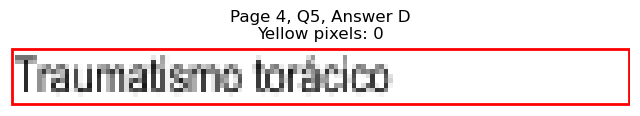

Page 4, Q5 - E: Detected box: x0=336.7, y0=410.4, x1=378.3, y1=422.5
Page 4, Q5, E: Yellow pixels: 0
Page 4, Q5, E: Total non-white pixels: 229
Page 4, Q5, E: Yellow percentage: 0.0%


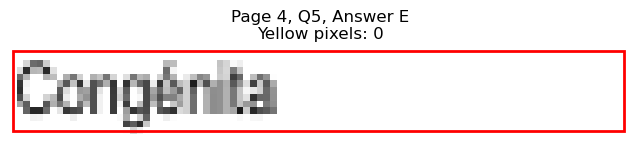


Page 4, Q5 - Selected Answer: A (based on yellow pixel count)




Page 4, Q6 - A: Detected box: x0=85.0, y0=470.7, x1=186.0, y1=482.8
Page 4, Q6, A: Yellow pixels: 1428
Page 4, Q6, A: Total non-white pixels: 1989
Page 4, Q6, A: Yellow percentage: 71.8%


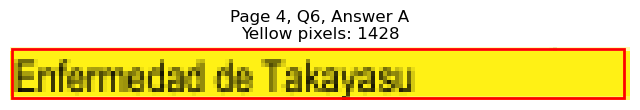

Page 4, Q6 - B: Detected box: x0=85.0, y0=482.7, x1=174.0, y1=494.8
Page 4, Q6, B: Yellow pixels: 139
Page 4, Q6, B: Total non-white pixels: 606
Page 4, Q6, B: Yellow percentage: 22.9%


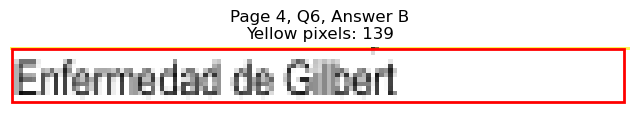

Page 4, Q6 - C: Detected box: x0=85.0, y0=494.7, x1=165.9, y1=506.8
Page 4, Q6, C: Yellow pixels: 0
Page 4, Q6, C: Total non-white pixels: 407
Page 4, Q6, C: Yellow percentage: 0.0%


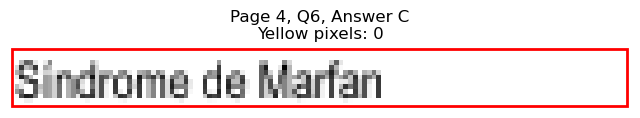

Page 4, Q6 - D: Detected box: x0=336.7, y0=470.7, x1=444.5, y1=482.8
Page 4, Q6, D: Yellow pixels: 0
Page 4, Q6, D: Total non-white pixels: 534
Page 4, Q6, D: Yellow percentage: 0.0%


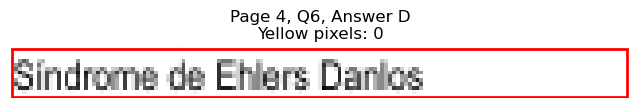

Page 4, Q6 - E: Detected box: x0=336.7, y0=482.7, x1=420.4, y1=494.8
Page 4, Q6, E: Yellow pixels: 0
Page 4, Q6, E: Total non-white pixels: 404
Page 4, Q6, E: Yellow percentage: 0.0%


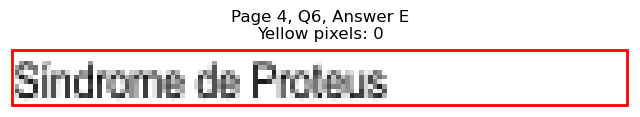


Page 4, Q6 - Selected Answer: A (based on yellow pixel count)




Page 4, Q7 - A: Detected box: x0=85.0, y0=530.9, x1=130.0, y1=543.0
Page 4, Q7, A: Yellow pixels: 960
Page 4, Q7, A: Total non-white pixels: 1248
Page 4, Q7, A: Yellow percentage: 76.9%


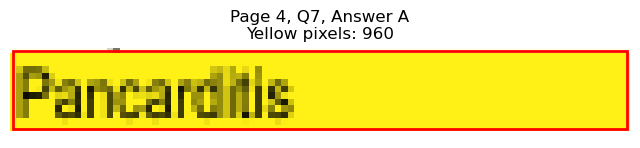

Page 4, Q7 - B: Detected box: x0=85.0, y0=542.9, x1=134.8, y1=555.0
Page 4, Q7, B: Yellow pixels: 101
Page 4, Q7, B: Total non-white pixels: 374
Page 4, Q7, B: Yellow percentage: 27.0%


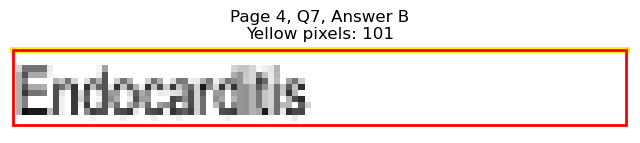

Page 4, Q7 - C: Detected box: x0=85.0, y0=554.9, x1=128.5, y1=567.0
Page 4, Q7, C: Yellow pixels: 0
Page 4, Q7, C: Total non-white pixels: 250
Page 4, Q7, C: Yellow percentage: 0.0%


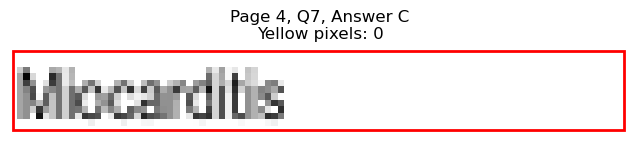

Page 4, Q7 - D: Detected box: x0=336.7, y0=530.9, x1=381.7, y1=543.0
Page 4, Q7, D: Yellow pixels: 0
Page 4, Q7, D: Total non-white pixels: 254
Page 4, Q7, D: Yellow percentage: 0.0%


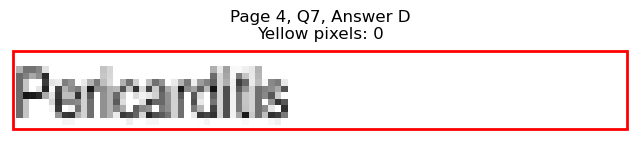

Page 4, Q7 - E: Detected box: x0=336.7, y0=542.9, x1=373.2, y1=555.0
Page 4, Q7, E: Yellow pixels: 0
Page 4, Q7, E: Total non-white pixels: 203
Page 4, Q7, E: Yellow percentage: 0.0%


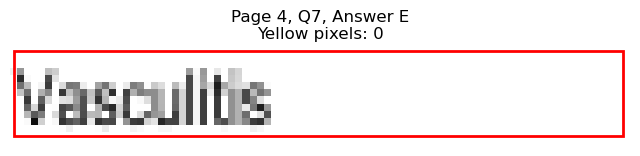


Page 4, Q7 - Selected Answer: A (based on yellow pixel count)




Page 4, Q8 - A: Detected box: x0=85.0, y0=603.2, x1=98.4, y1=615.3
Page 4, Q8, A: Yellow pixels: 720
Page 4, Q8, A: Total non-white pixels: 845
Page 4, Q8, A: Yellow percentage: 85.2%


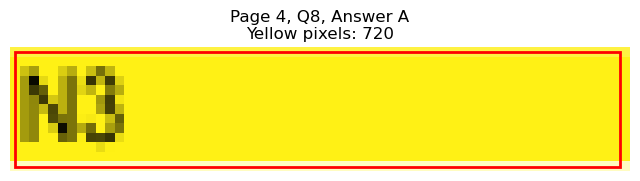

Page 4, Q8 - B: Detected box: x0=85.0, y0=615.2, x1=98.4, y1=627.3
Page 4, Q8, B: Yellow pixels: 0
Page 4, Q8, B: Total non-white pixels: 132
Page 4, Q8, B: Yellow percentage: 0.0%


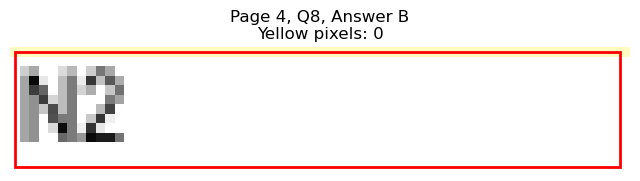

Page 4, Q8 - C: Detected box: x0=85.0, y0=627.3, x1=99.4, y1=639.4
Page 4, Q8, C: Yellow pixels: 0
Page 4, Q8, C: Total non-white pixels: 67
Page 4, Q8, C: Yellow percentage: 0.0%


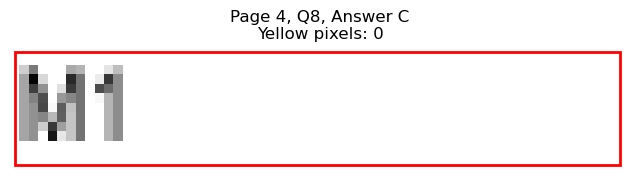

Page 4, Q8 - D: Detected box: x0=336.7, y0=603.2, x1=354.0, y1=615.3
Page 4, Q8, D: Yellow pixels: 0
Page 4, Q8, D: Total non-white pixels: 63
Page 4, Q8, D: Yellow percentage: 0.0%


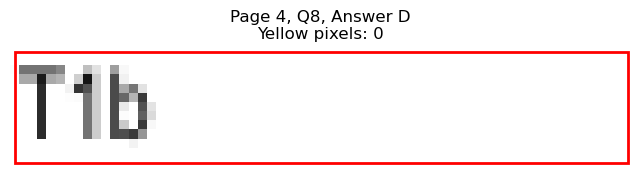

Page 4, Q8 - E: Detected box: x0=336.7, y0=615.2, x1=349.6, y1=627.3
Page 4, Q8, E: Yellow pixels: 0
Page 4, Q8, E: Total non-white pixels: 61
Page 4, Q8, E: Yellow percentage: 0.0%


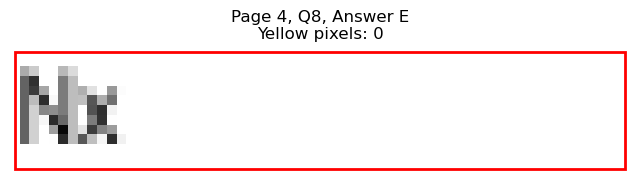


Page 4, Q8 - Selected Answer: A (based on yellow pixel count)




Page 4, Q9 - A: Detected box: x0=85.0, y0=663.4, x1=397.5, y1=675.5
Page 4, Q9, A: Yellow pixels: 364
Page 4, Q9, A: Total non-white pixels: 1925
Page 4, Q9, A: Yellow percentage: 18.9%


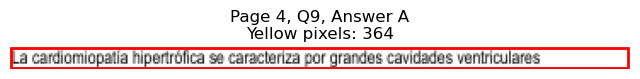

Page 4, Q9 - B: Detected box: x0=85.0, y0=675.4, x1=320.1, y1=687.5
Page 4, Q9, B: Yellow pixels: 2787
Page 4, Q9, B: Total non-white pixels: 3731
Page 4, Q9, B: Yellow percentage: 74.7%


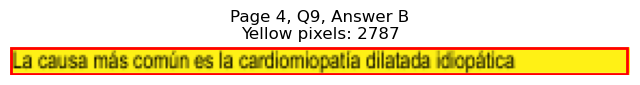

Page 4, Q9 - C: Detected box: x0=85.0, y0=687.5, x1=345.9, y1=699.7
Page 4, Q9, C: Yellow pixels: 312
Page 4, Q9, C: Total non-white pixels: 1589
Page 4, Q9, C: Yellow percentage: 19.6%


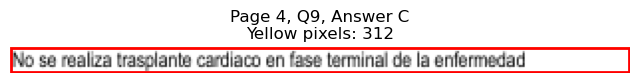

Page 4, Q9 - D: Detected box: x0=85.0, y0=699.5, x1=423.0, y1=711.7
Page 4, Q9, D: Yellow pixels: 0
Page 4, Q9, D: Total non-white pixels: 1710
Page 4, Q9, D: Yellow percentage: 0.0%


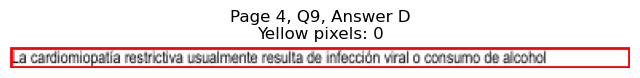

Page 4, Q9 - E: Detected box: x0=85.0, y0=711.7, x1=400.9, y1=723.8
Page 4, Q9, E: Yellow pixels: 0
Page 4, Q9, E: Total non-white pixels: 1523
Page 4, Q9, E: Yellow percentage: 0.0%


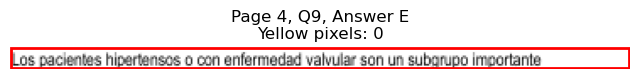


Page 4, Q9 - Selected Answer: B (based on yellow pixel count)





Page 5: Found 8 questions
Page 5, Q1 - A: Detected box: x0=85.0, y0=109.2, x1=266.9, y1=121.3
Page 5, Q1, A: Yellow pixels: 190
Page 5, Q1, A: Total non-white pixels: 1118
Page 5, Q1, A: Yellow percentage: 17.0%


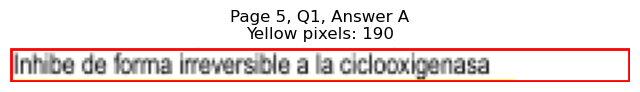

Page 5, Q1 - B: Detected box: x0=85.0, y0=121.2, x1=236.7, y1=133.3
Page 5, Q1, B: Yellow pixels: 1640
Page 5, Q1, B: Total non-white pixels: 2483
Page 5, Q1, B: Yellow percentage: 66.0%


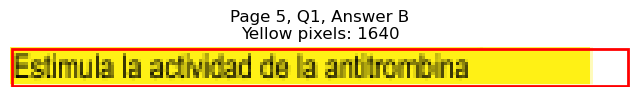

Page 5, Q1 - C: Detected box: x0=85.0, y0=133.2, x1=208.0, y1=145.3
Page 5, Q1, C: Yellow pixels: 0
Page 5, Q1, C: Total non-white pixels: 804
Page 5, Q1, C: Yellow percentage: 0.0%


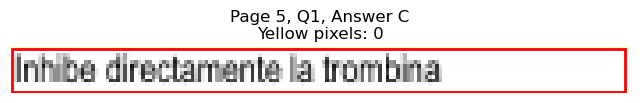

Page 5, Q1 - D: Detected box: x0=478.3, y0=109.2, x1=526.8, y1=121.3
Page 5, Q1, D: Yellow pixels: 0
Page 5, Q1, D: Total non-white pixels: 259
Page 5, Q1, D: Yellow percentage: 0.0%


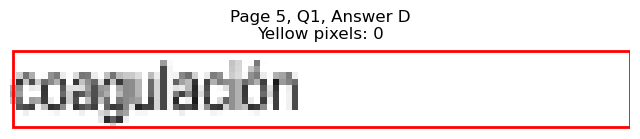

Page 5, Q1 - E: Detected box: x0=336.7, y0=133.2, x1=468.3, y1=145.3
Page 5, Q1, E: Yellow pixels: 0
Page 5, Q1, E: Total non-white pixels: 689
Page 5, Q1, E: Yellow percentage: 0.0%


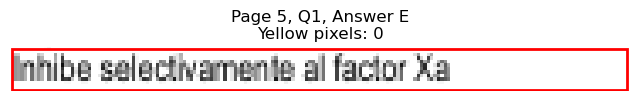


Page 5, Q1 - Selected Answer: B (based on yellow pixel count)




Page 5, Q2 - A: Detected box: x0=85.0, y0=169.4, x1=254.9, y1=181.5
Page 5, Q2, A: Yellow pixels: 0
Page 5, Q2, A: Total non-white pixels: 838
Page 5, Q2, A: Yellow percentage: 0.0%


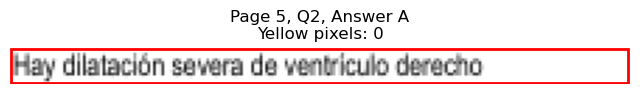

Page 5, Q2 - B: Detected box: x0=85.0, y0=181.4, x1=288.4, y1=193.5
Page 5, Q2, B: Yellow pixels: 0
Page 5, Q2, B: Total non-white pixels: 1015
Page 5, Q2, B: Yellow percentage: 0.0%


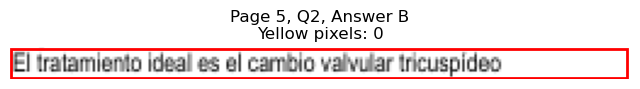

Page 5, Q2 - C: Detected box: x0=85.0, y0=193.4, x1=223.4, y1=205.5
Page 5, Q2, C: Yellow pixels: 0
Page 5, Q2, C: Total non-white pixels: 692
Page 5, Q2, C: Yellow percentage: 0.0%


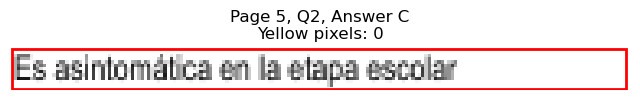

Page 5, Q2 - D: Detected box: x0=85.0, y0=205.5, x1=312.4, y1=217.7
Page 5, Q2, D: Yellow pixels: 279
Page 5, Q2, D: Total non-white pixels: 1392
Page 5, Q2, D: Yellow percentage: 20.0%


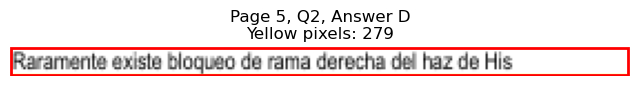

Page 5, Q2 - E: Detected box: x0=85.0, y0=217.5, x1=526.7, y1=229.7
Page 5, Q2, E: Yellow pixels: 3978
Page 5, Q2, E: Total non-white pixels: 5746
Page 5, Q2, E: Yellow percentage: 69.2%


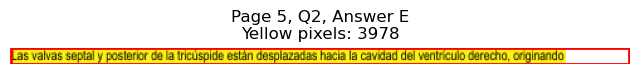


Page 5, Q2 - Selected Answer: E (based on yellow pixel count)




Page 5, Q3 - A: Detected box: x0=85.0, y0=265.8, x1=228.1, y1=277.9
Page 5, Q3, A: Yellow pixels: 0
Page 5, Q3, A: Total non-white pixels: 933
Page 5, Q3, A: Yellow percentage: 0.0%


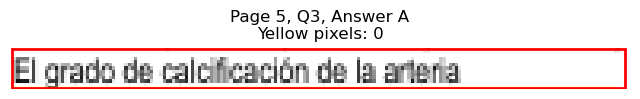

Page 5, Q3 - B: Detected box: x0=85.0, y0=277.8, x1=190.9, y1=289.9
Page 5, Q3, B: Yellow pixels: 1449
Page 5, Q3, B: Total non-white pixels: 2041
Page 5, Q3, B: Yellow percentage: 71.0%


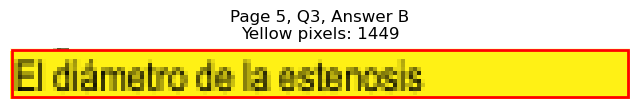

Page 5, Q3 - C: Detected box: x0=85.0, y0=289.9, x1=189.4, y1=302.0
Page 5, Q3, C: Yellow pixels: 156
Page 5, Q3, C: Total non-white pixels: 671
Page 5, Q3, C: Yellow percentage: 23.2%


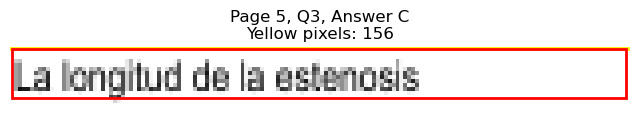

Page 5, Q3 - D: Detected box: x0=336.7, y0=265.8, x1=421.9, y1=277.9
Page 5, Q3, D: Yellow pixels: 0
Page 5, Q3, D: Total non-white pixels: 414
Page 5, Q3, D: Yellow percentage: 0.0%


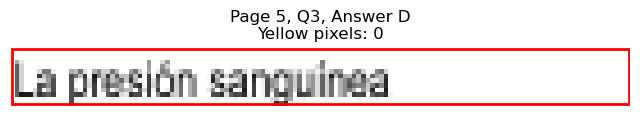

Page 5, Q3 - E: Detected box: x0=336.7, y0=277.8, x1=433.9, y1=289.9
Page 5, Q3, E: Yellow pixels: 0
Page 5, Q3, E: Total non-white pixels: 502
Page 5, Q3, E: Yellow percentage: 0.0%


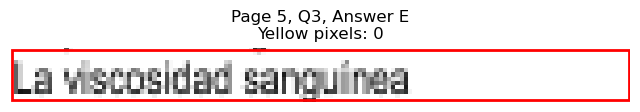


Page 5, Q3 - Selected Answer: B (based on yellow pixel count)




Page 5, Q4 - A: Detected box: x0=85.0, y0=338.1, x1=129.0, y1=350.2
Page 5, Q4, A: Yellow pixels: 0
Page 5, Q4, A: Total non-white pixels: 248
Page 5, Q4, A: Yellow percentage: 0.0%


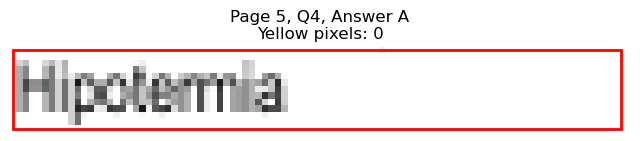

Page 5, Q4 - B: Detected box: x0=85.0, y0=350.2, x1=185.1, y1=362.3
Page 5, Q4, B: Yellow pixels: 152
Page 5, Q4, B: Total non-white pixels: 628
Page 5, Q4, B: Yellow percentage: 24.2%


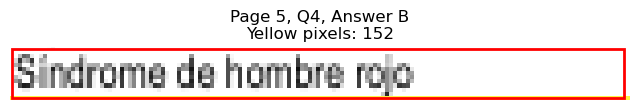

Page 5, Q4 - C: Detected box: x0=85.0, y0=362.2, x1=181.8, y1=374.3
Page 5, Q4, C: Yellow pixels: 1373
Page 5, Q4, C: Total non-white pixels: 1924
Page 5, Q4, C: Yellow percentage: 71.4%


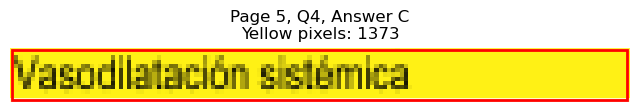

Page 5, Q4 - D: Detected box: x0=85.0, y0=374.2, x1=135.7, y1=386.3
Page 5, Q4, D: Yellow pixels: 0
Page 5, Q4, D: Total non-white pixels: 374
Page 5, Q4, D: Yellow percentage: 0.0%


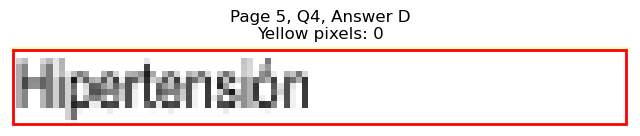

Page 5, Q4 - E: Detected box: x0=85.0, y0=386.3, x1=119.4, y1=398.4
Page 5, Q4, E: Yellow pixels: 0
Page 5, Q4, E: Total non-white pixels: 175
Page 5, Q4, E: Yellow percentage: 0.0%


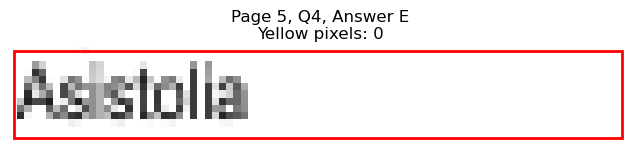


Page 5, Q4 - Selected Answer: C (based on yellow pixel count)




Page 5, Q5 - A: Detected box: x0=85.0, y0=446.6, x1=197.0, y1=458.7
Page 5, Q5, A: Yellow pixels: 0
Page 5, Q5, A: Total non-white pixels: 548
Page 5, Q5, A: Yellow percentage: 0.0%


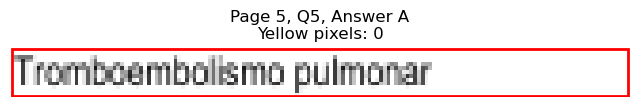

Page 5, Q5 - B: Detected box: x0=85.0, y0=458.6, x1=285.5, y1=470.7
Page 5, Q5, B: Yellow pixels: 0
Page 5, Q5, B: Total non-white pixels: 1031
Page 5, Q5, B: Yellow percentage: 0.0%


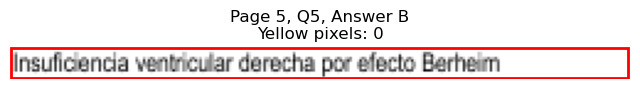

Page 5, Q5 - C: Detected box: x0=85.0, y0=470.7, x1=148.1, y1=482.8
Page 5, Q5, C: Yellow pixels: 0
Page 5, Q5, C: Total non-white pixels: 442
Page 5, Q5, C: Yellow percentage: 0.0%


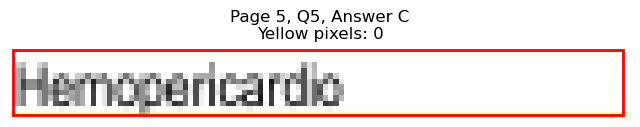

Page 5, Q5 - D: Detected box: x0=85.0, y0=482.7, x1=197.1, y1=494.8
Page 5, Q5, D: Yellow pixels: 1530
Page 5, Q5, D: Total non-white pixels: 2132
Page 5, Q5, D: Yellow percentage: 71.8%


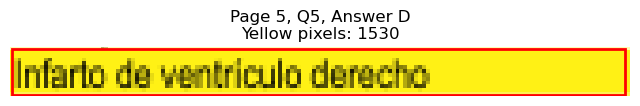

Page 5, Q5 - E: Detected box: x0=85.0, y0=494.7, x1=197.5, y1=506.8
Page 5, Q5, E: Yellow pixels: 164
Page 5, Q5, E: Total non-white pixels: 755
Page 5, Q5, E: Yellow percentage: 21.7%


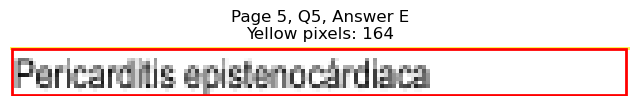


Page 5, Q5 - Selected Answer: D (based on yellow pixel count)




Page 5, Q6 - A: Detected box: x0=85.0, y0=530.9, x1=197.5, y1=543.0
Page 5, Q6, A: Yellow pixels: 1493
Page 5, Q6, A: Total non-white pixels: 2132
Page 5, Q6, A: Yellow percentage: 70.0%


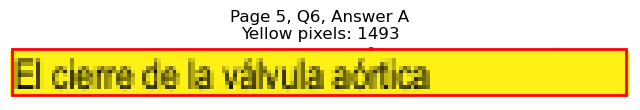

Page 5, Q6 - B: Detected box: x0=85.0, y0=542.9, x1=205.1, y1=555.0
Page 5, Q6, B: Yellow pixels: 172
Page 5, Q6, B: Total non-white pixels: 749
Page 5, Q6, B: Yellow percentage: 23.0%


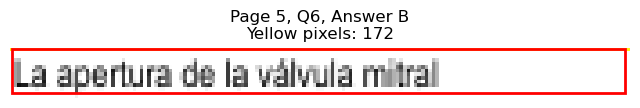

Page 5, Q6 - C: Detected box: x0=85.0, y0=554.9, x1=192.7, y1=567.0
Page 5, Q6, C: Yellow pixels: 0
Page 5, Q6, C: Total non-white pixels: 523
Page 5, Q6, C: Yellow percentage: 0.0%


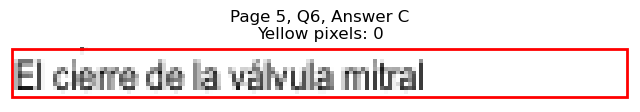

Page 5, Q6 - D: Detected box: x0=336.7, y0=530.9, x1=461.6, y1=543.0
Page 5, Q6, D: Yellow pixels: 0
Page 5, Q6, D: Total non-white pixels: 604
Page 5, Q6, D: Yellow percentage: 0.0%


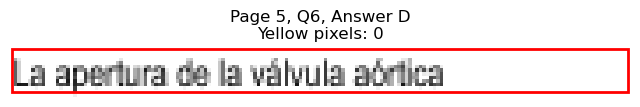

Page 5, Q6 - E: Detected box: x0=336.7, y0=542.9, x1=460.2, y1=555.0
Page 5, Q6, E: Yellow pixels: 0
Page 5, Q6, E: Total non-white pixels: 627
Page 5, Q6, E: Yellow percentage: 0.0%


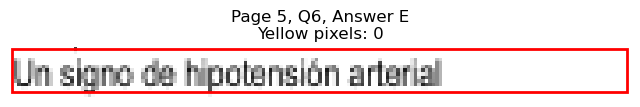


Page 5, Q6 - Selected Answer: A (based on yellow pixel count)




Page 5, Q7 - A: Detected box: x0=85.0, y0=591.2, x1=352.5, y1=603.3
Page 5, Q7, A: Yellow pixels: 0
Page 5, Q7, A: Total non-white pixels: 1387
Page 5, Q7, A: Yellow percentage: 0.0%


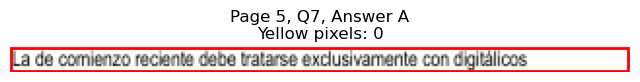

Page 5, Q7 - B: Detected box: x0=85.0, y0=603.2, x1=526.8, y1=615.3
Page 5, Q7, B: Yellow pixels: 0
Page 5, Q7, B: Total non-white pixels: 2193
Page 5, Q7, B: Yellow percentage: 0.0%


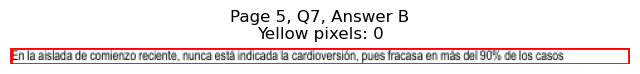

Page 5, Q7 - C: Detected box: x0=85.0, y0=615.2, x1=357.8, y1=627.3
Page 5, Q7, C: Yellow pixels: 0
Page 5, Q7, C: Total non-white pixels: 1383
Page 5, Q7, C: Yellow percentage: 0.0%


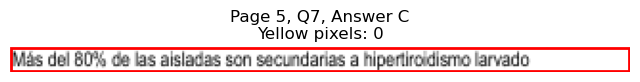

Page 5, Q7 - D: Detected box: x0=85.0, y0=627.3, x1=286.1, y1=639.4
Page 5, Q7, D: Yellow pixels: 253
Page 5, Q7, D: Total non-white pixels: 1220
Page 5, Q7, D: Yellow percentage: 20.7%


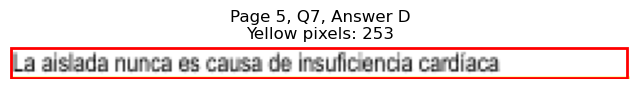

Page 5, Q7 - E: Detected box: x0=85.0, y0=639.3, x1=432.1, y1=651.4
Page 5, Q7, E: Yellow pixels: 3785
Page 5, Q7, E: Total non-white pixels: 5187
Page 5, Q7, E: Yellow percentage: 73.0%


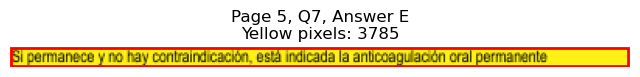


Page 5, Q7 - Selected Answer: E (based on yellow pixel count)




Page 5, Q8 - A: Detected box: x0=85.0, y0=687.5, x1=191.8, y1=699.7
Page 5, Q8, A: Yellow pixels: 1636
Page 5, Q8, A: Total non-white pixels: 2054
Page 5, Q8, A: Yellow percentage: 79.6%


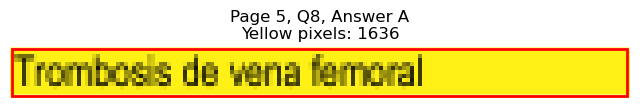

Page 5, Q8 - B: Detected box: x0=85.0, y0=699.5, x1=226.3, y1=711.7
Page 5, Q8, B: Yellow pixels: 190
Page 5, Q8, B: Total non-white pixels: 804
Page 5, Q8, B: Yellow percentage: 23.6%


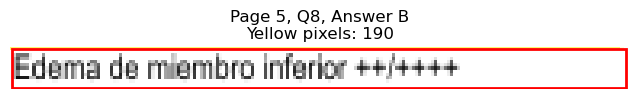

Page 5, Q8 - C: Detected box: x0=85.0, y0=711.7, x1=197.1, y1=723.8
Page 5, Q8, C: Yellow pixels: 0
Page 5, Q8, C: Total non-white pixels: 555
Page 5, Q8, C: Yellow percentage: 0.0%


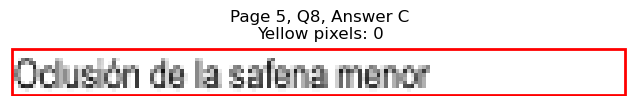

Page 5, Q8 - D: Detected box: x0=336.7, y0=687.5, x1=435.3, y1=699.7
Page 5, Q8, D: Yellow pixels: 0
Page 5, Q8, D: Total non-white pixels: 488
Page 5, Q8, D: Yellow percentage: 0.0%


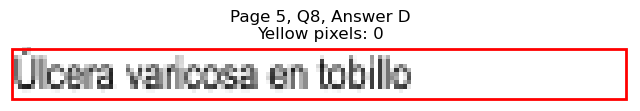

Page 5, Q8 - E: Detected box: x0=336.7, y0=699.5, x1=387.9, y1=711.7
Page 5, Q8, E: Yellow pixels: 0
Page 5, Q8, E: Total non-white pixels: 276
Page 5, Q8, E: Yellow percentage: 0.0%


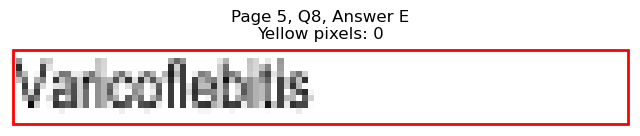


Page 5, Q8 - Selected Answer: A (based on yellow pixel count)





Page 6: Found 8 questions
Page 6, Q1 - A: Detected box: x0=85.0, y0=85.1, x1=185.1, y1=97.2
Page 6, Q1, A: Yellow pixels: 0
Page 6, Q1, A: Total non-white pixels: 549
Page 6, Q1, A: Yellow percentage: 0.0%


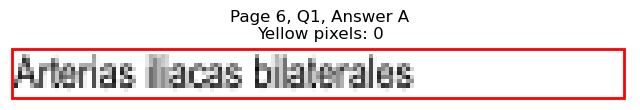

Page 6, Q1 - B: Detected box: x0=85.0, y0=97.1, x1=217.1, y1=109.2
Page 6, Q1, B: Yellow pixels: 0
Page 6, Q1, B: Total non-white pixels: 659
Page 6, Q1, B: Yellow percentage: 0.0%


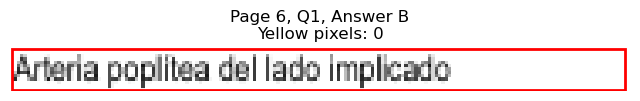

Page 6, Q1 - C: Detected box: x0=85.0, y0=109.2, x1=243.4, y1=121.3
Page 6, Q1, C: Yellow pixels: 0
Page 6, Q1, C: Total non-white pixels: 804
Page 6, Q1, C: Yellow percentage: 0.0%


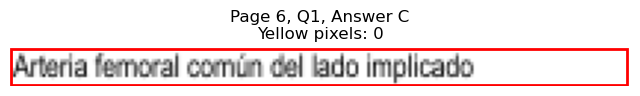

Page 6, Q1 - D: Detected box: x0=336.7, y0=85.1, x1=508.1, y1=97.2
Page 6, Q1, D: Yellow pixels: 1588
Page 6, Q1, D: Total non-white pixels: 2470
Page 6, Q1, D: Yellow percentage: 64.3%


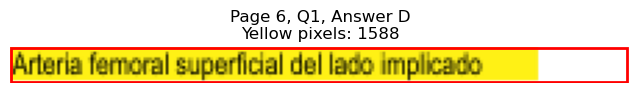

Page 6, Q1 - E: Detected box: x0=336.7, y0=97.1, x1=491.7, y1=109.2
Page 6, Q1, E: Yellow pixels: 0
Page 6, Q1, E: Total non-white pixels: 972
Page 6, Q1, E: Yellow percentage: 0.0%


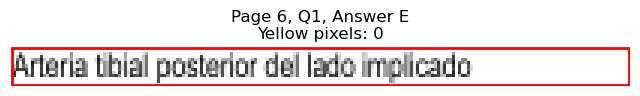


Page 6, Q1 - Selected Answer: D (based on yellow pixel count)




Page 6, Q2 - A: Detected box: x0=85.0, y0=145.3, x1=157.3, y1=157.4
Page 6, Q2, A: Yellow pixels: 1169
Page 6, Q2, A: Total non-white pixels: 1612
Page 6, Q2, A: Yellow percentage: 72.5%


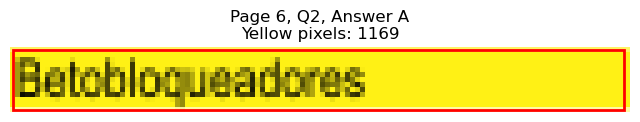

Page 6, Q2 - B: Detected box: x0=85.0, y0=157.3, x1=126.6, y1=169.4
Page 6, Q2, B: Yellow pixels: 0
Page 6, Q2, B: Total non-white pixels: 349
Page 6, Q2, B: Yellow percentage: 0.0%


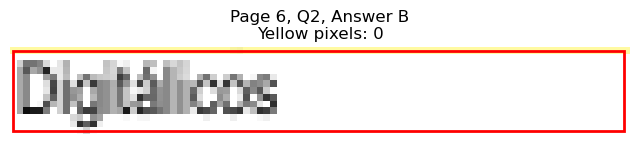

Page 6, Q2 - C: Detected box: x0=85.0, y0=169.4, x1=126.6, y1=181.5
Page 6, Q2, C: Yellow pixels: 0
Page 6, Q2, C: Total non-white pixels: 218
Page 6, Q2, C: Yellow percentage: 0.0%


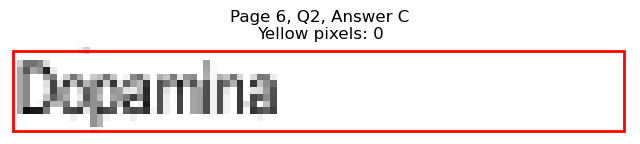

Page 6, Q2 - D: Detected box: x0=336.7, y0=145.3, x1=389.4, y1=157.4
Page 6, Q2, D: Yellow pixels: 0
Page 6, Q2, D: Total non-white pixels: 295
Page 6, Q2, D: Yellow percentage: 0.0%


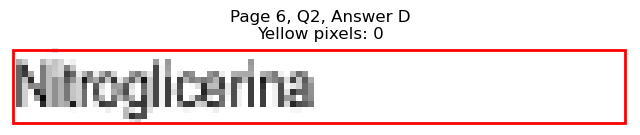

Page 6, Q2 - E: Detected box: x0=336.7, y0=157.3, x1=387.9, y1=169.4
Page 6, Q2, E: Yellow pixels: 0
Page 6, Q2, E: Total non-white pixels: 281
Page 6, Q2, E: Yellow percentage: 0.0%


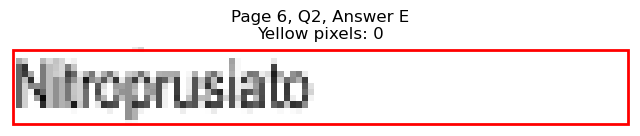


Page 6, Q2 - Selected Answer: A (based on yellow pixel count)




Page 6, Q3 - A: Detected box: x0=85.0, y0=229.7, x1=400.4, y1=241.8
Page 6, Q3, A: Yellow pixels: 0
Page 6, Q3, A: Total non-white pixels: 1634
Page 6, Q3, A: Yellow percentage: 0.0%


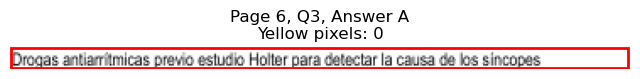

Page 6, Q3 - B: Detected box: x0=85.0, y0=241.7, x1=353.0, y1=253.8
Page 6, Q3, B: Yellow pixels: 0
Page 6, Q3, B: Total non-white pixels: 1374
Page 6, Q3, B: Yellow percentage: 0.0%


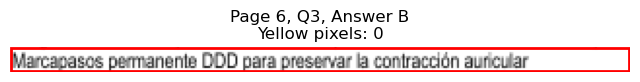

Page 6, Q3 - C: Detected box: x0=85.0, y0=253.7, x1=355.5, y1=265.8
Page 6, Q3, C: Yellow pixels: 0
Page 6, Q3, C: Total non-white pixels: 1379
Page 6, Q3, C: Yellow percentage: 0.0%


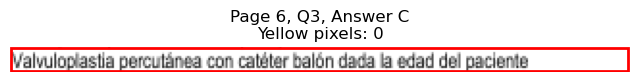

Page 6, Q3 - D: Detected box: x0=85.0, y0=265.8, x1=248.7, y1=277.9
Page 6, Q3, D: Yellow pixels: 1878
Page 6, Q3, D: Total non-white pixels: 2795
Page 6, Q3, D: Yellow percentage: 67.2%


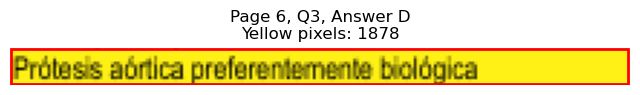

Page 6, Q3 - E: Detected box: x0=85.0, y0=277.8, x1=253.5, y1=289.9
Page 6, Q3, E: Yellow pixels: 215
Page 6, Q3, E: Total non-white pixels: 1075
Page 6, Q3, E: Yellow percentage: 20.0%


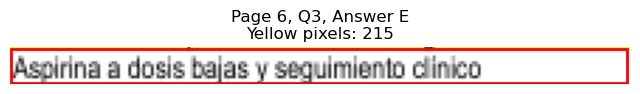


Page 6, Q3 - Selected Answer: D (based on yellow pixel count)




Page 6, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=234.3, y1=326.0
Page 6, Q4, A: Yellow pixels: 0
Page 6, Q4, A: Total non-white pixels: 779
Page 6, Q4, A: Yellow percentage: 0.0%


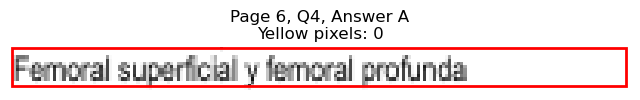

Page 6, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=180.3, y1=338.2
Page 6, Q4, B: Yellow pixels: 0
Page 6, Q4, B: Total non-white pixels: 479
Page 6, Q4, B: Yellow percentage: 0.0%


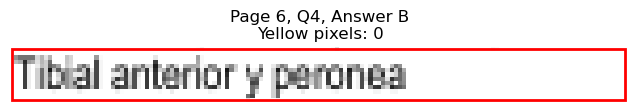

Page 6, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=179.3, y1=350.2
Page 6, Q4, C: Yellow pixels: 0
Page 6, Q4, C: Total non-white pixels: 501
Page 6, Q4, C: Yellow percentage: 0.0%


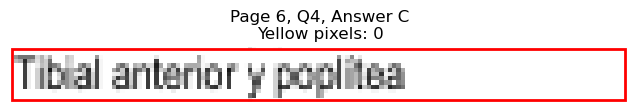

Page 6, Q4 - D: Detected box: x0=336.7, y0=313.9, x1=436.3, y1=326.0
Page 6, Q4, D: Yellow pixels: 1432
Page 6, Q4, D: Total non-white pixels: 2114
Page 6, Q4, D: Yellow percentage: 67.7%


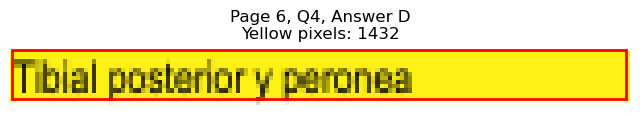

Page 6, Q4 - E: Detected box: x0=336.7, y0=326.1, x1=453.9, y1=338.2
Page 6, Q4, E: Yellow pixels: 0
Page 6, Q4, E: Total non-white pixels: 767
Page 6, Q4, E: Yellow percentage: 0.0%


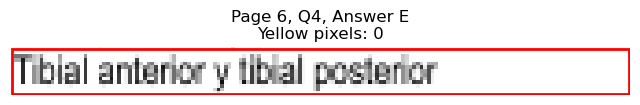


Page 6, Q4 - Selected Answer: D (based on yellow pixel count)




Page 6, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=335.8, y1=386.3
Page 6, Q5, A: Yellow pixels: 2570
Page 6, Q5, A: Total non-white pixels: 3926
Page 6, Q5, A: Yellow percentage: 65.5%


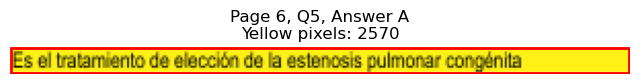

Page 6, Q5 - B: Detected box: x0=85.0, y0=386.3, x1=477.9, y1=398.4
Page 6, Q5, B: Yellow pixels: 1
Page 6, Q5, B: Total non-white pixels: 2374
Page 6, Q5, B: Yellow percentage: 0.0%


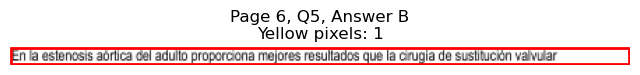

Page 6, Q5 - C: Detected box: x0=85.0, y0=398.3, x1=299.5, y1=410.4
Page 6, Q5, C: Yellow pixels: 0
Page 6, Q5, C: Total non-white pixels: 1073
Page 6, Q5, C: Yellow percentage: 0.0%


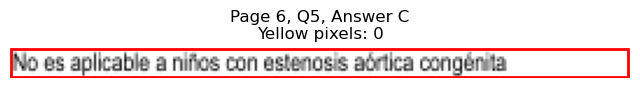

Page 6, Q5 - D: Detected box: x0=85.0, y0=410.4, x1=526.8, y1=422.5
Page 6, Q5, D: Yellow pixels: 0
Page 6, Q5, D: Total non-white pixels: 2122
Page 6, Q5, D: Yellow percentage: 0.0%


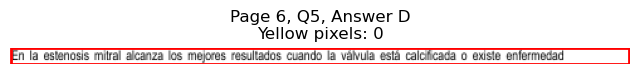

Page 6, Q5 - E: Detected box: x0=85.0, y0=434.4, x1=481.3, y1=446.5
Page 6, Q5, E: Yellow pixels: 0
Page 6, Q5, E: Total non-white pixels: 1969
Page 6, Q5, E: Yellow percentage: 0.0%


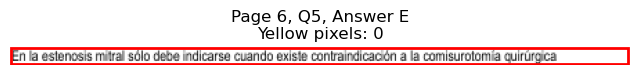


Page 6, Q5 - Selected Answer: A (based on yellow pixel count)




Page 6, Q6 - A: Detected box: x0=85.0, y0=470.7, x1=201.3, y1=482.8
Page 6, Q6, A: Yellow pixels: 0
Page 6, Q6, A: Total non-white pixels: 762
Page 6, Q6, A: Yellow percentage: 0.0%


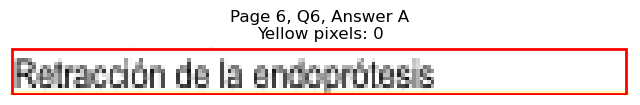

Page 6, Q6 - B: Detected box: x0=85.0, y0=482.7, x1=188.9, y1=494.8
Page 6, Q6, B: Yellow pixels: 1459
Page 6, Q6, B: Total non-white pixels: 2015
Page 6, Q6, B: Yellow percentage: 72.4%


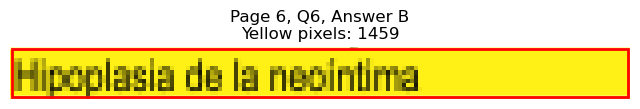

Page 6, Q6 - C: Detected box: x0=85.0, y0=494.7, x1=206.6, y1=506.8
Page 6, Q6, C: Yellow pixels: 170
Page 6, Q6, C: Total non-white pixels: 807
Page 6, Q6, C: Yellow percentage: 21.1%


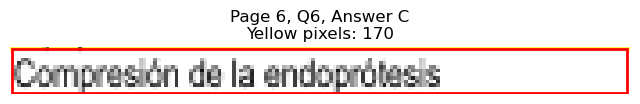

Page 6, Q6 - D: Detected box: x0=336.7, y0=470.7, x1=396.1, y1=482.8
Page 6, Q6, D: Yellow pixels: 0
Page 6, Q6, D: Total non-white pixels: 289
Page 6, Q6, D: Yellow percentage: 0.0%


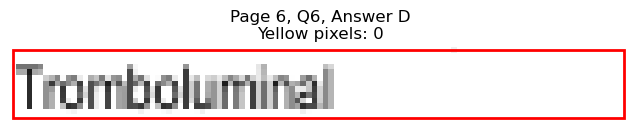

Page 6, Q6 - E: Detected box: x0=336.7, y0=482.7, x1=421.4, y1=494.8
Page 6, Q6, E: Yellow pixels: 0
Page 6, Q6, E: Total non-white pixels: 409
Page 6, Q6, E: Yellow percentage: 0.0%


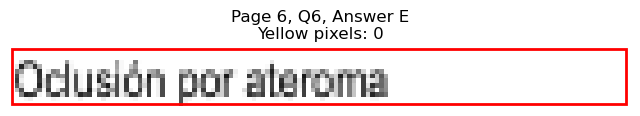


Page 6, Q6 - Selected Answer: B (based on yellow pixel count)




Page 6, Q7 - A: Detected box: x0=85.0, y0=542.9, x1=163.5, y1=555.0
Page 6, Q7, A: Yellow pixels: 0
Page 6, Q7, A: Total non-white pixels: 379
Page 6, Q7, A: Yellow percentage: 0.0%


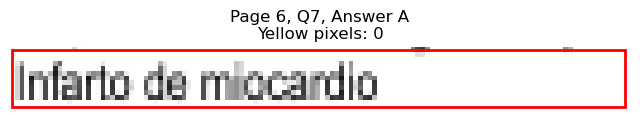

Page 6, Q7 - B: Detected box: x0=85.0, y0=554.9, x1=177.9, y1=567.0
Page 6, Q7, B: Yellow pixels: 0
Page 6, Q7, B: Total non-white pixels: 457
Page 6, Q7, B: Yellow percentage: 0.0%


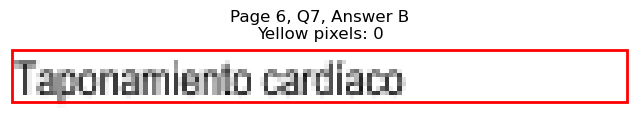

Page 6, Q7 - C: Detected box: x0=85.0, y0=567.1, x1=188.9, y1=579.2
Page 6, Q7, C: Yellow pixels: 1413
Page 6, Q7, C: Total non-white pixels: 2015
Page 6, Q7, C: Yellow percentage: 70.1%


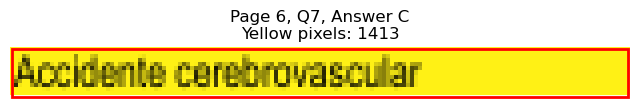

Page 6, Q7 - D: Detected box: x0=336.7, y0=542.9, x1=386.5, y1=555.0
Page 6, Q7, D: Yellow pixels: 0
Page 6, Q7, D: Total non-white pixels: 273
Page 6, Q7, D: Yellow percentage: 0.0%


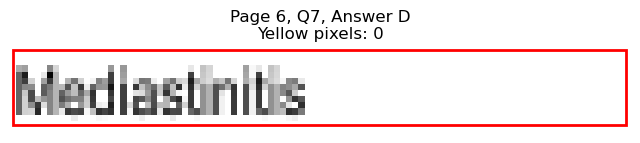

Page 6, Q7 - E: Detected box: x0=336.7, y0=554.9, x1=403.8, y1=567.0
Page 6, Q7, E: Yellow pixels: 0
Page 6, Q7, E: Total non-white pixels: 323
Page 6, Q7, E: Yellow percentage: 0.0%


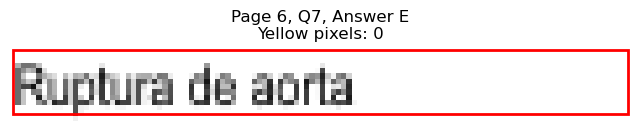


Page 6, Q7 - Selected Answer: C (based on yellow pixel count)




Page 6, Q8 - A: Detected box: x0=85.0, y0=687.5, x1=414.8, y1=699.7
Page 6, Q8, A: Yellow pixels: 0
Page 6, Q8, A: Total non-white pixels: 1649
Page 6, Q8, A: Yellow percentage: 0.0%


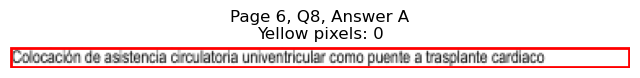

Page 6, Q8 - B: Detected box: x0=85.0, y0=699.5, x1=331.0, y1=711.7
Page 6, Q8, B: Yellow pixels: 0
Page 6, Q8, B: Total non-white pixels: 1233
Page 6, Q8, B: Yellow percentage: 0.0%


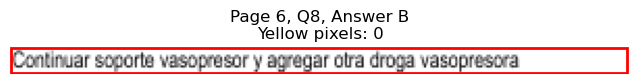

Page 6, Q8 - C: Detected box: x0=85.0, y0=711.7, x1=210.9, y1=723.8
Page 6, Q8, C: Yellow pixels: 0
Page 6, Q8, C: Total non-white pixels: 657
Page 6, Q8, C: Yellow percentage: 0.0%


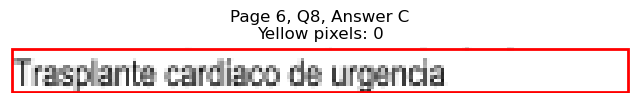

Page 6, Q8 - D: Detected box: x0=85.0, y0=723.7, x1=255.9, y1=735.8
Page 6, Q8, D: Yellow pixels: 0
Page 6, Q8, D: Total non-white pixels: 872
Page 6, Q8, D: Yellow percentage: 0.0%


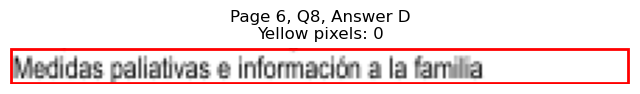

Page 6, Q8 - E: Detected box: x0=85.0, y0=735.8, x1=526.6, y1=747.9
Page 6, Q8, E: Yellow pixels: 3673
Page 6, Q8, E: Total non-white pixels: 5746
Page 6, Q8, E: Yellow percentage: 63.9%


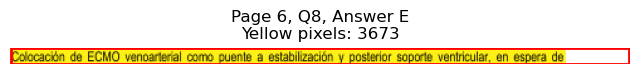


Page 6, Q8 - Selected Answer: E (based on yellow pixel count)





Page 7: Found 8 questions
Page 7, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=185.5, y1=109.2
Page 7, Q1, A: Yellow pixels: 0
Page 7, Q1, A: Total non-white pixels: 466
Page 7, Q1, A: Yellow percentage: 0.0%


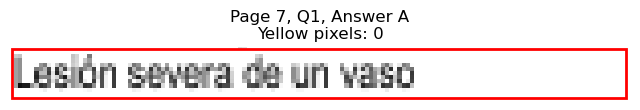

Page 7, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=416.4, y1=121.3
Page 7, Q1, B: Yellow pixels: 0
Page 7, Q1, B: Total non-white pixels: 1633
Page 7, Q1, B: Yellow percentage: 0.0%


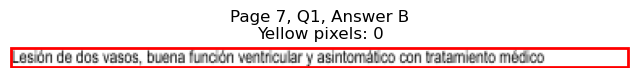

Page 7, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=258.3, y1=133.3
Page 7, Q1, C: Yellow pixels: 0
Page 7, Q1, C: Total non-white pixels: 862
Page 7, Q1, C: Yellow percentage: 0.0%


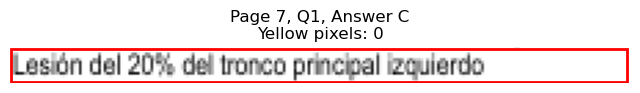

Page 7, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=375.1, y1=145.3
Page 7, Q1, D: Yellow pixels: 0
Page 7, Q1, D: Total non-white pixels: 1470
Page 7, Q1, D: Yellow percentage: 0.0%


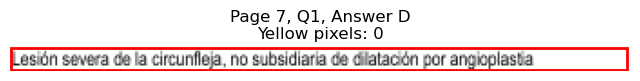

Page 7, Q1 - E: Detected box: x0=70.8, y0=145.3, x1=489.7, y1=157.4
Page 7, Q1, E: Yellow pixels: 3892
Page 7, Q1, E: Total non-white pixels: 5928
Page 7, Q1, E: Yellow percentage: 65.7%


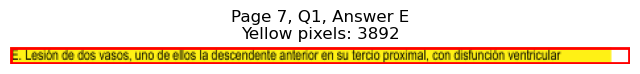


Page 7, Q1 - Selected Answer: E (based on yellow pixel count)




Page 7, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=185.1, y1=193.5
Page 7, Q2, A: Yellow pixels: 152
Page 7, Q2, A: Total non-white pixels: 639
Page 7, Q2, A: Yellow percentage: 23.8%


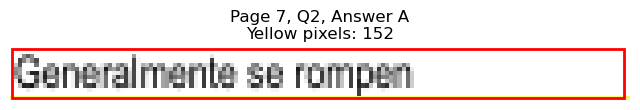

Page 7, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=359.2, y1=205.5
Page 7, Q2, B: Yellow pixels: 3119
Page 7, Q2, B: Total non-white pixels: 4238
Page 7, Q2, B: Yellow percentage: 73.6%


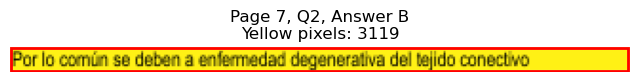

Page 7, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=303.8, y1=217.7
Page 7, Q2, C: Yellow pixels: 270
Page 7, Q2, C: Total non-white pixels: 1328
Page 7, Q2, C: Yellow percentage: 20.3%


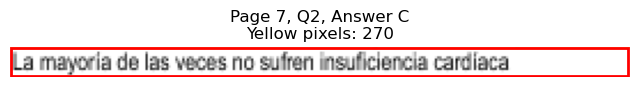

Page 7, Q2 - D: Detected box: x0=85.0, y0=217.5, x1=222.4, y1=229.7
Page 7, Q2, D: Yellow pixels: 0
Page 7, Q2, D: Total non-white pixels: 675
Page 7, Q2, D: Yellow percentage: 0.0%


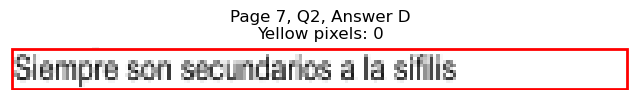

Page 7, Q2 - E: Detected box: x0=85.0, y0=229.7, x1=247.3, y1=241.8
Page 7, Q2, E: Yellow pixels: 0
Page 7, Q2, E: Total non-white pixels: 828
Page 7, Q2, E: Yellow percentage: 0.0%


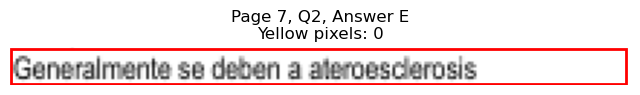


Page 7, Q2 - Selected Answer: B (based on yellow pixel count)




Page 7, Q3 - A: Detected box: x0=85.0, y0=277.8, x1=116.1, y1=289.9
Page 7, Q3, A: Yellow pixels: 0
Page 7, Q3, A: Total non-white pixels: 111
Page 7, Q3, A: Yellow percentage: 0.0%


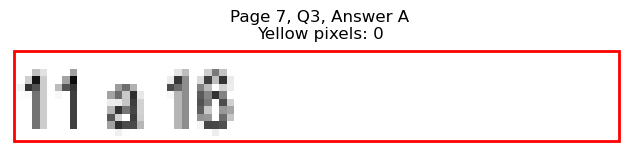

Page 7, Q3 - B: Detected box: x0=85.0, y0=289.9, x1=111.4, y1=302.0
Page 7, Q3, B: Yellow pixels: 846
Page 7, Q3, B: Total non-white pixels: 1014
Page 7, Q3, B: Yellow percentage: 83.4%


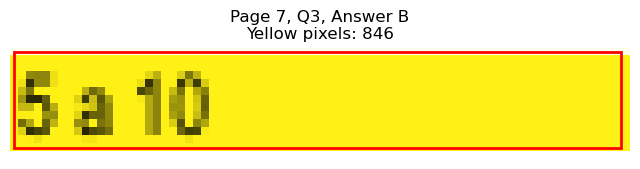

Page 7, Q3 - C: Detected box: x0=85.0, y0=301.9, x1=116.1, y1=314.0
Page 7, Q3, C: Yellow pixels: 83
Page 7, Q3, C: Total non-white pixels: 195
Page 7, Q3, C: Yellow percentage: 42.6%


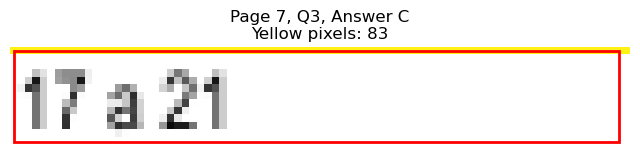

Page 7, Q3 - D: Detected box: x0=85.0, y0=313.9, x1=116.1, y1=326.0
Page 7, Q3, D: Yellow pixels: 0
Page 7, Q3, D: Total non-white pixels: 140
Page 7, Q3, D: Yellow percentage: 0.0%


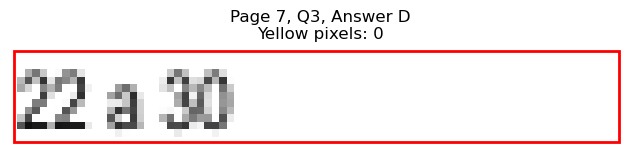

Page 7, Q3 - E: Detected box: x0=85.0, y0=326.1, x1=116.1, y1=338.2
Page 7, Q3, E: Yellow pixels: 0
Page 7, Q3, E: Total non-white pixels: 133
Page 7, Q3, E: Yellow percentage: 0.0%


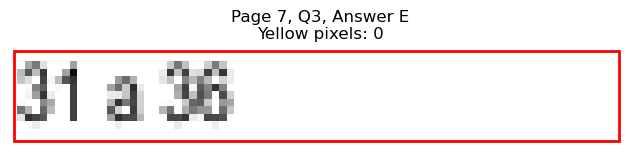


Page 7, Q3 - Selected Answer: B (based on yellow pixel count)




Page 7, Q4 - A: Detected box: x0=85.0, y0=362.2, x1=474.1, y1=374.3
Page 7, Q4, A: Yellow pixels: 0
Page 7, Q4, A: Total non-white pixels: 1898
Page 7, Q4, A: Yellow percentage: 0.0%


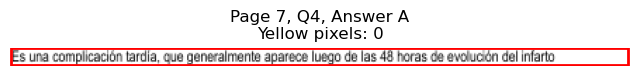

Page 7, Q4 - B: Detected box: x0=85.0, y0=374.2, x1=422.5, y1=386.3
Page 7, Q4, B: Yellow pixels: 0
Page 7, Q4, B: Total non-white pixels: 1639
Page 7, Q4, B: Yellow percentage: 0.0%


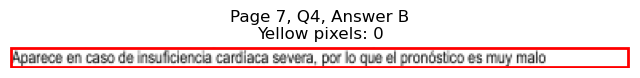

Page 7, Q4 - C: Detected box: x0=85.0, y0=386.3, x1=353.0, y1=398.4
Page 7, Q4, C: Yellow pixels: 0
Page 7, Q4, C: Total non-white pixels: 1348
Page 7, Q4, C: Yellow percentage: 0.0%


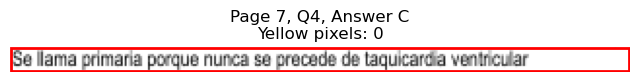

Page 7, Q4 - D: Detected box: x0=85.0, y0=398.3, x1=392.0, y1=410.4
Page 7, Q4, D: Yellow pixels: 0
Page 7, Q4, D: Total non-white pixels: 1515
Page 7, Q4, D: Yellow percentage: 0.0%


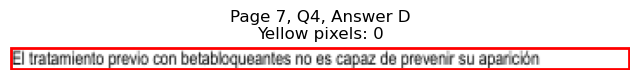

Page 7, Q4 - E: Detected box: x0=85.0, y0=410.4, x1=526.7, y1=422.5
Page 7, Q4, E: Yellow pixels: 4088
Page 7, Q4, E: Total non-white pixels: 5746
Page 7, Q4, E: Yellow percentage: 71.1%


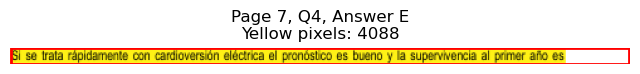


Page 7, Q4 - Selected Answer: E (based on yellow pixel count)




Page 7, Q5 - A: Detected box: x0=85.0, y0=482.7, x1=275.3, y1=494.8
Page 7, Q5, A: Yellow pixels: 0
Page 7, Q5, A: Total non-white pixels: 937
Page 7, Q5, A: Yellow percentage: 0.0%


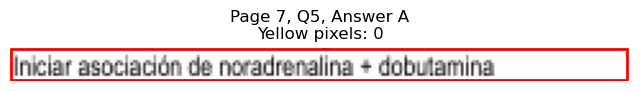

Page 7, Q5 - B: Detected box: x0=85.0, y0=494.7, x1=260.2, y1=506.8
Page 7, Q5, B: Yellow pixels: 0
Page 7, Q5, B: Total non-white pixels: 884
Page 7, Q5, B: Yellow percentage: 0.0%


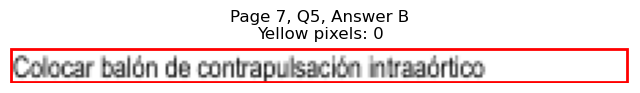

Page 7, Q5 - C: Detected box: x0=85.0, y0=506.8, x1=316.6, y1=518.9
Page 7, Q5, C: Yellow pixels: 0
Page 7, Q5, C: Total non-white pixels: 1162
Page 7, Q5, C: Yellow percentage: 0.0%


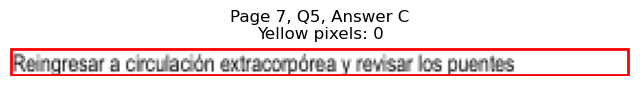

Page 7, Q5 - D: Detected box: x0=85.0, y0=518.8, x1=300.4, y1=530.9
Page 7, Q5, D: Yellow pixels: 0
Page 7, Q5, D: Total non-white pixels: 1087
Page 7, Q5, D: Yellow percentage: 0.0%


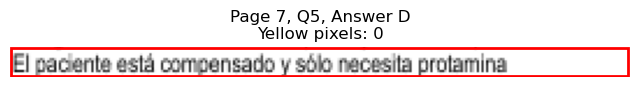

Page 7, Q5 - E: Detected box: x0=85.0, y0=530.9, x1=165.9, y1=543.0
Page 7, Q5, E: Yellow pixels: 1262
Page 7, Q5, E: Total non-white pixels: 1716
Page 7, Q5, E: Yellow percentage: 73.5%


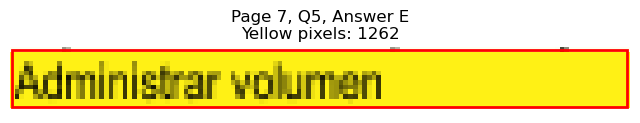


Page 7, Q5 - Selected Answer: E (based on yellow pixel count)




Page 7, Q6 - A: Detected box: x0=85.0, y0=579.1, x1=191.3, y1=591.2
Page 7, Q6, A: Yellow pixels: 0
Page 7, Q6, A: Total non-white pixels: 520
Page 7, Q6, A: Yellow percentage: 0.0%


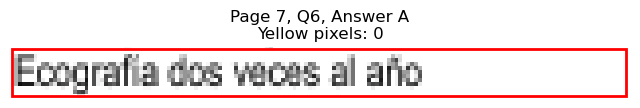

Page 7, Q6 - B: Detected box: x0=85.0, y0=591.2, x1=164.9, y1=603.3
Page 7, Q6, B: Yellow pixels: 1238
Page 7, Q6, B: Total non-white pixels: 1703
Page 7, Q6, B: Yellow percentage: 72.7%


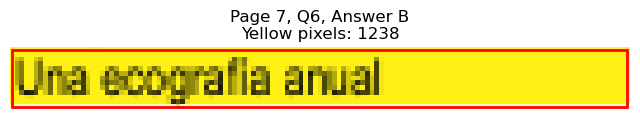

Page 7, Q6 - C: Detected box: x0=85.0, y0=603.2, x1=198.5, y1=615.3
Page 7, Q6, C: Yellow pixels: 0
Page 7, Q6, C: Total non-white pixels: 762
Page 7, Q6, C: Yellow percentage: 0.0%


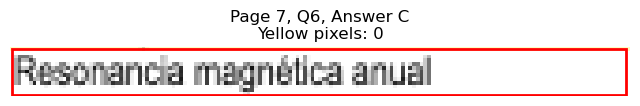

Page 7, Q6 - D: Detected box: x0=336.7, y0=579.1, x1=526.8, y1=591.2
Page 7, Q6, D: Yellow pixels: 0
Page 7, Q6, D: Total non-white pixels: 909
Page 7, Q6, D: Yellow percentage: 0.0%


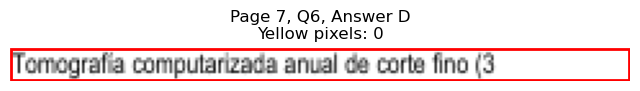

Page 7, Q6 - E: Detected box: x0=336.7, y0=603.2, x1=526.8, y1=615.3
Page 7, Q6, E: Yellow pixels: 0
Page 7, Q6, E: Total non-white pixels: 888
Page 7, Q6, E: Yellow percentage: 0.0%


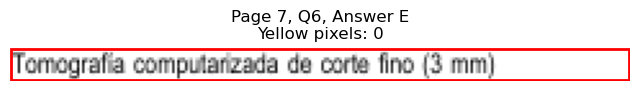


Page 7, Q6 - Selected Answer: B (based on yellow pixel count)




Page 7, Q7 - A: Detected box: x0=85.0, y0=651.4, x1=137.7, y1=663.5
Page 7, Q7, A: Yellow pixels: 104
Page 7, Q7, A: Total non-white pixels: 358
Page 7, Q7, A: Yellow percentage: 29.1%


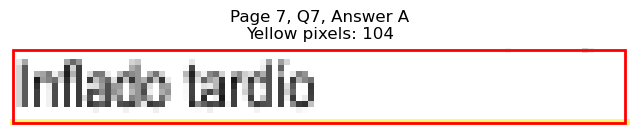

Page 7, Q7 - B: Detected box: x0=85.0, y0=663.4, x1=152.5, y1=675.5
Page 7, Q7, B: Yellow pixels: 1245
Page 7, Q7, B: Total non-white pixels: 1547
Page 7, Q7, B: Yellow percentage: 80.5%


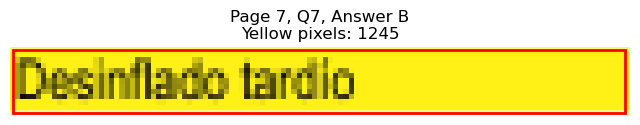

Page 7, Q7 - C: Detected box: x0=85.0, y0=675.4, x1=141.5, y1=687.5
Page 7, Q7, C: Yellow pixels: 108
Page 7, Q7, C: Total non-white pixels: 384
Page 7, Q7, C: Yellow percentage: 28.1%


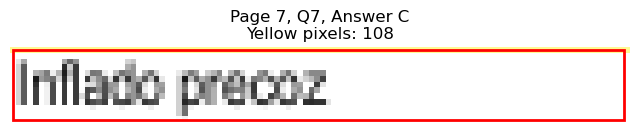

Page 7, Q7 - D: Detected box: x0=336.7, y0=651.4, x1=408.0, y1=663.5
Page 7, Q7, D: Yellow pixels: 0
Page 7, Q7, D: Total non-white pixels: 372
Page 7, Q7, D: Yellow percentage: 0.0%


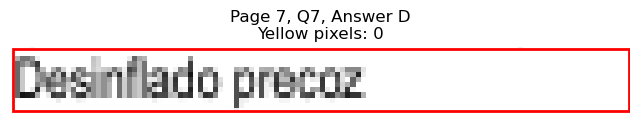

Page 7, Q7 - E: Detected box: x0=336.7, y0=663.4, x1=407.5, y1=675.5
Page 7, Q7, E: Yellow pixels: 0
Page 7, Q7, E: Total non-white pixels: 371
Page 7, Q7, E: Yellow percentage: 0.0%


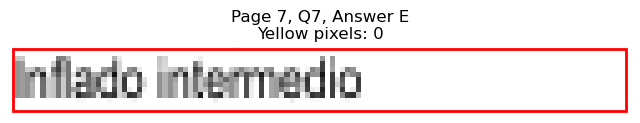


Page 7, Q7 - Selected Answer: B (based on yellow pixel count)




Page 7, Q8 - A: Detected box: x0=85.0, y0=711.7, x1=133.8, y1=723.8
Page 7, Q8, A: Yellow pixels: 0
Page 7, Q8, A: Total non-white pixels: 247
Page 7, Q8, A: Yellow percentage: 0.0%


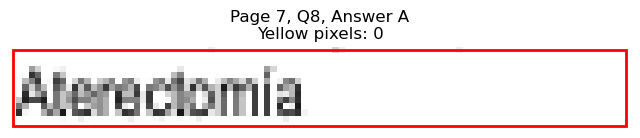

Page 7, Q8 - B: Detected box: x0=85.0, y0=723.7, x1=134.3, y1=735.8
Page 7, Q8, B: Yellow pixels: 0
Page 7, Q8, B: Total non-white pixels: 278
Page 7, Q8, B: Yellow percentage: 0.0%


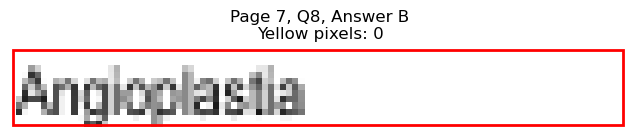

Page 7, Q8 - C: Detected box: x0=85.0, y0=735.8, x1=151.1, y1=747.9
Page 7, Q8, C: Yellow pixels: 1129
Page 7, Q8, C: Total non-white pixels: 1534
Page 7, Q8, C: Yellow percentage: 73.6%


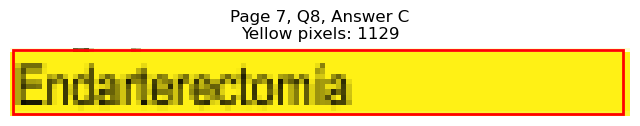

Page 7, Q8 - D: Detected box: x0=336.7, y0=711.7, x1=414.2, y1=723.8
Page 7, Q8, D: Yellow pixels: 0
Page 7, Q8, D: Total non-white pixels: 389
Page 7, Q8, D: Yellow percentage: 0.0%


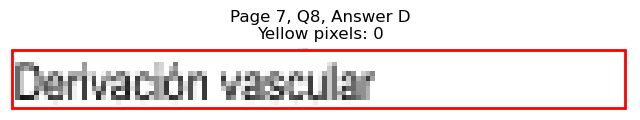

Page 7, Q8 - E: Detected box: x0=336.7, y0=723.7, x1=394.6, y1=735.8
Page 7, Q8, E: Yellow pixels: 0
Page 7, Q8, E: Total non-white pixels: 274
Page 7, Q8, E: Yellow percentage: 0.0%


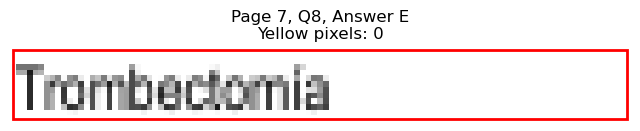


Page 7, Q8 - Selected Answer: C (based on yellow pixel count)





Page 8: Found 8 questions
Page 8, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=363.6, y1=109.2
Page 8, Q1, A: Yellow pixels: 0
Page 8, Q1, A: Total non-white pixels: 1373
Page 8, Q1, A: Yellow percentage: 0.0%


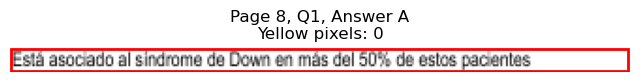

Page 8, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=367.9, y1=121.3
Page 8, Q1, B: Yellow pixels: 0
Page 8, Q1, B: Total non-white pixels: 1412
Page 8, Q1, B: Yellow percentage: 0.0%


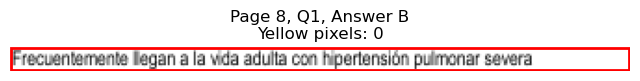

Page 8, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=274.0, y1=133.3
Page 8, Q1, C: Yellow pixels: 241
Page 8, Q1, C: Total non-white pixels: 1215
Page 8, Q1, C: Yellow percentage: 19.8%


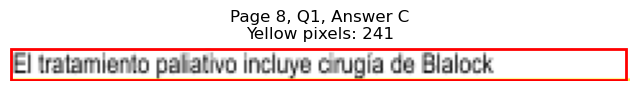

Page 8, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=526.5, y1=145.3
Page 8, Q1, D: Yellow pixels: 3634
Page 8, Q1, D: Total non-white pixels: 5746
Page 8, Q1, D: Yellow percentage: 63.2%


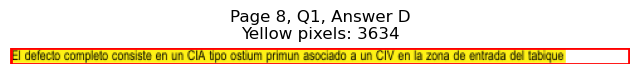

Page 8, Q1 - E: Detected box: x0=85.0, y0=157.3, x1=342.1, y1=169.4
Page 8, Q1, E: Yellow pixels: 1
Page 8, Q1, E: Total non-white pixels: 1568
Page 8, Q1, E: Yellow percentage: 0.1%


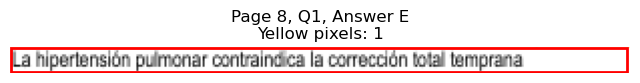


Page 8, Q1 - Selected Answer: D (based on yellow pixel count)




Page 8, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=149.7, y1=205.5
Page 8, Q2, A: Yellow pixels: 1243
Page 8, Q2, A: Total non-white pixels: 1508
Page 8, Q2, A: Yellow percentage: 82.4%


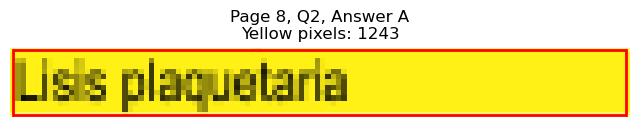

Page 8, Q2 - B: Detected box: x0=85.0, y0=205.5, x1=139.6, y1=217.7
Page 8, Q2, B: Yellow pixels: 106
Page 8, Q2, B: Total non-white pixels: 396
Page 8, Q2, B: Yellow percentage: 26.8%


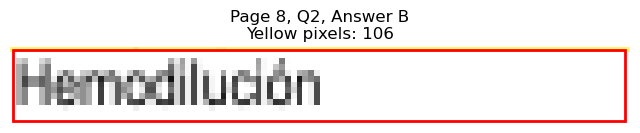

Page 8, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=129.0, y1=229.7
Page 8, Q2, C: Yellow pixels: 0
Page 8, Q2, C: Total non-white pixels: 247
Page 8, Q2, C: Yellow percentage: 0.0%


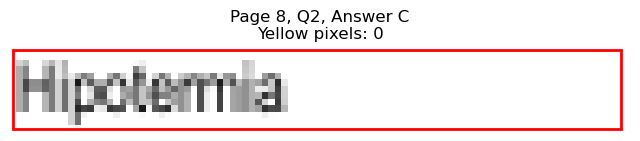

Page 8, Q2 - D: Detected box: x0=336.7, y0=193.4, x1=403.2, y1=205.5
Page 8, Q2, D: Yellow pixels: 0
Page 8, Q2, D: Total non-white pixels: 333
Page 8, Q2, D: Yellow percentage: 0.0%


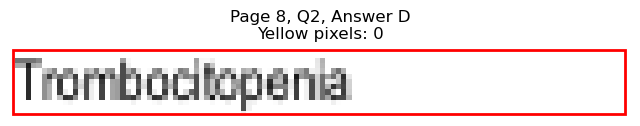

Page 8, Q2 - E: Detected box: x0=336.7, y0=205.5, x1=432.9, y1=217.7
Page 8, Q2, E: Yellow pixels: 0
Page 8, Q2, E: Total non-white pixels: 509
Page 8, Q2, E: Yellow percentage: 0.0%


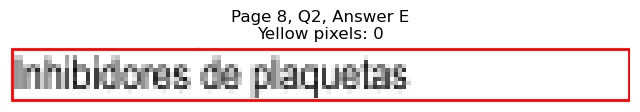


Page 8, Q2 - Selected Answer: A (based on yellow pixel count)




Page 8, Q3 - A: Detected box: x0=85.0, y0=301.9, x1=411.9, y1=314.0
Page 8, Q3, A: Yellow pixels: 3154
Page 8, Q3, A: Total non-white pixels: 4917
Page 8, Q3, A: Yellow percentage: 64.1%


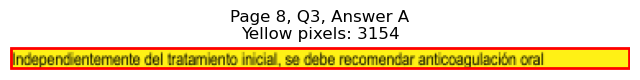

Page 8, Q3 - B: Detected box: x0=85.0, y0=313.9, x1=257.3, y1=326.0
Page 8, Q3, B: Yellow pixels: 223
Page 8, Q3, B: Total non-white pixels: 1086
Page 8, Q3, B: Yellow percentage: 20.5%


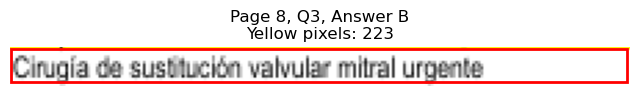

Page 8, Q3 - C: Detected box: x0=85.0, y0=326.1, x1=386.1, y1=338.2
Page 8, Q3, C: Yellow pixels: 0
Page 8, Q3, C: Total non-white pixels: 1517
Page 8, Q3, C: Yellow percentage: 0.0%


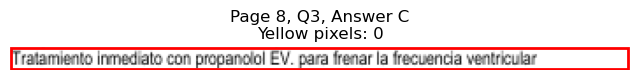

Page 8, Q3 - D: Detected box: x0=85.0, y0=338.1, x1=206.6, y1=350.2
Page 8, Q3, D: Yellow pixels: 0
Page 8, Q3, D: Total non-white pixels: 638
Page 8, Q3, D: Yellow percentage: 0.0%


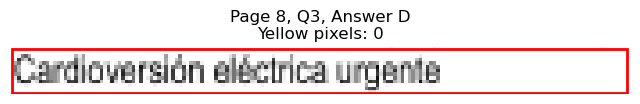

Page 8, Q3 - E: Detected box: x0=85.0, y0=350.2, x1=246.3, y1=362.3
Page 8, Q3, E: Yellow pixels: 0
Page 8, Q3, E: Total non-white pixels: 806
Page 8, Q3, E: Yellow percentage: 0.0%


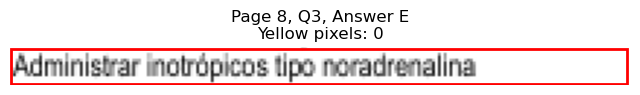


Page 8, Q3 - Selected Answer: A (based on yellow pixel count)




Page 8, Q4 - A: Detected box: x0=85.0, y0=398.3, x1=117.0, y1=410.4
Page 8, Q4, A: Yellow pixels: 949
Page 8, Q4, A: Total non-white pixels: 1092
Page 8, Q4, A: Yellow percentage: 86.9%


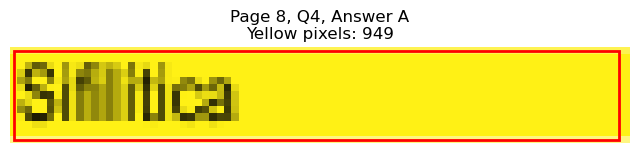

Page 8, Q4 - B: Detected box: x0=85.0, y0=410.4, x1=149.1, y1=422.5
Page 8, Q4, B: Yellow pixels: 116
Page 8, Q4, B: Total non-white pixels: 455
Page 8, Q4, B: Yellow percentage: 25.5%


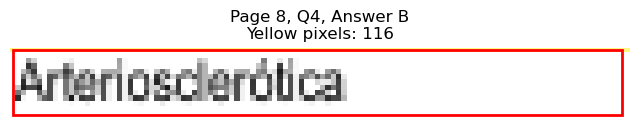

Page 8, Q4 - C: Detected box: x0=85.0, y0=422.4, x1=118.9, y1=434.5
Page 8, Q4, C: Yellow pixels: 0
Page 8, Q4, C: Total non-white pixels: 192
Page 8, Q4, C: Yellow percentage: 0.0%


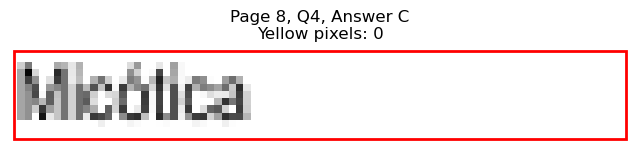

Page 8, Q4 - D: Detected box: x0=336.7, y0=398.3, x1=382.2, y1=410.4
Page 8, Q4, D: Yellow pixels: 0
Page 8, Q4, D: Total non-white pixels: 212
Page 8, Q4, D: Yellow percentage: 0.0%


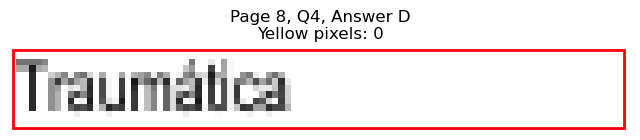

Page 8, Q4 - E: Detected box: x0=336.7, y0=410.4, x1=378.3, y1=422.5
Page 8, Q4, E: Yellow pixels: 0
Page 8, Q4, E: Total non-white pixels: 229
Page 8, Q4, E: Yellow percentage: 0.0%


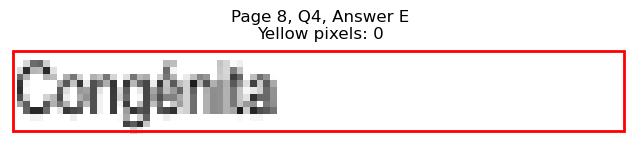


Page 8, Q4 - Selected Answer: A (based on yellow pixel count)




Page 8, Q5 - A: Detected box: x0=85.0, y0=458.6, x1=94.6, y1=470.7
Page 8, Q5, A: Yellow pixels: 754
Page 8, Q5, A: Total non-white pixels: 793
Page 8, Q5, A: Yellow percentage: 95.1%


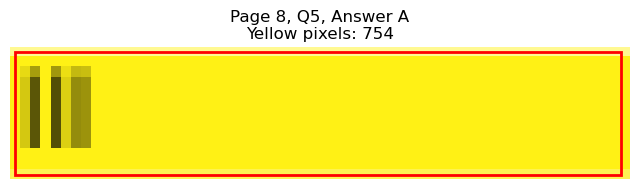

Page 8, Q5 - B: Detected box: x0=70.8, y0=470.7, x1=79.0, y1=482.8
Page 8, Q5, B: Yellow pixels: 59
Page 8, Q5, B: Total non-white pixels: 114
Page 8, Q5, B: Yellow percentage: 51.8%


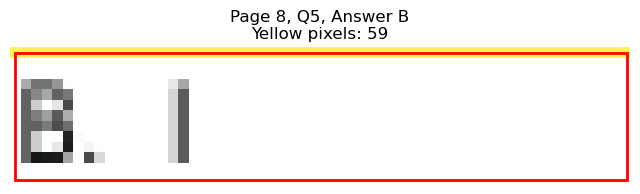

Page 8, Q5 - C: Detected box: x0=70.8, y0=482.7, x1=79.5, y1=494.8
Page 8, Q5, C: Yellow pixels: 0
Page 8, Q5, C: Total non-white pixels: 67
Page 8, Q5, C: Yellow percentage: 0.0%


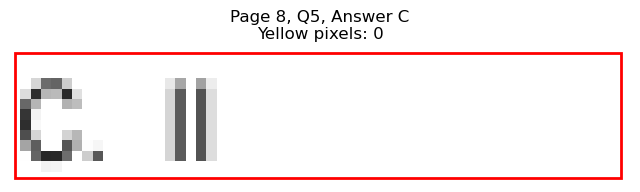

Page 8, Q5 - D: Detected box: x0=336.7, y0=458.6, x1=347.2, y1=470.7
Page 8, Q5, D: Yellow pixels: 0
Page 8, Q5, D: Total non-white pixels: 44
Page 8, Q5, D: Yellow percentage: 0.0%


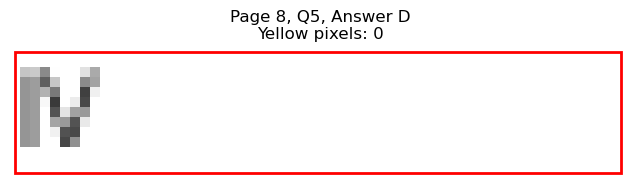

Page 8, Q5 - E: Detected box: x0=322.5, y0=470.7, x1=330.7, y1=482.8
Page 8, Q5, E: Yellow pixels: 0
Page 8, Q5, E: Total non-white pixels: 58
Page 8, Q5, E: Yellow percentage: 0.0%


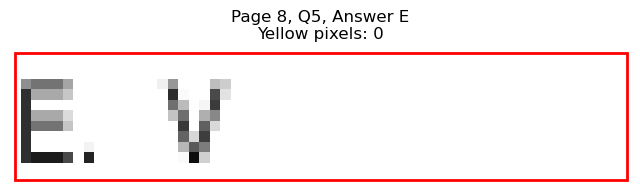


Page 8, Q5 - Selected Answer: A (based on yellow pixel count)




Page 8, Q6 - A: Detected box: x0=85.0, y0=518.8, x1=124.7, y1=530.9
Page 8, Q6, A: Yellow pixels: 0
Page 8, Q6, A: Total non-white pixels: 208
Page 8, Q6, A: Yellow percentage: 0.0%


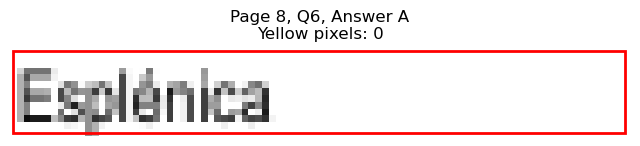

Page 8, Q6 - B: Detected box: x0=85.0, y0=530.9, x1=119.4, y1=543.0
Page 8, Q6, B: Yellow pixels: 0
Page 8, Q6, B: Total non-white pixels: 193
Page 8, Q6, B: Yellow percentage: 0.0%


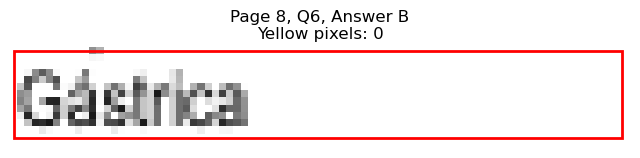

Page 8, Q6 - C: Detected box: x0=85.0, y0=542.9, x1=121.3, y1=555.0
Page 8, Q6, C: Yellow pixels: 0
Page 8, Q6, C: Total non-white pixels: 206
Page 8, Q6, C: Yellow percentage: 0.0%


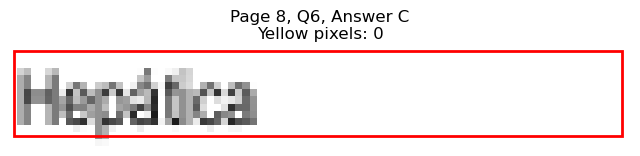

Page 8, Q6 - D: Detected box: x0=336.7, y0=518.8, x1=373.5, y1=530.9
Page 8, Q6, D: Yellow pixels: 892
Page 8, Q6, D: Total non-white pixels: 1144
Page 8, Q6, D: Yellow percentage: 78.0%


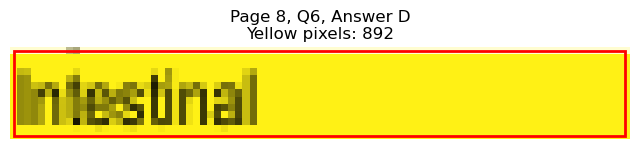

Page 8, Q6 - E: Detected box: x0=336.7, y0=530.9, x1=384.6, y1=543.0
Page 8, Q6, E: Yellow pixels: 99
Page 8, Q6, E: Total non-white pixels: 355
Page 8, Q6, E: Yellow percentage: 27.9%


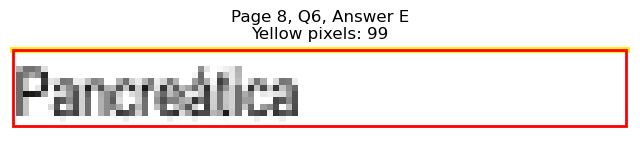


Page 8, Q6 - Selected Answer: D (based on yellow pixel count)




Page 8, Q7 - A: Detected box: x0=85.0, y0=627.3, x1=173.1, y1=639.4
Page 8, Q7, A: Yellow pixels: 1325
Page 8, Q7, A: Total non-white pixels: 1820
Page 8, Q7, A: Yellow percentage: 72.8%


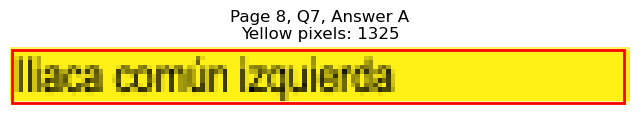

Page 8, Q7 - B: Detected box: x0=85.0, y0=639.3, x1=150.1, y1=651.4
Page 8, Q7, B: Yellow pixels: 0
Page 8, Q7, B: Total non-white pixels: 422
Page 8, Q7, B: Yellow percentage: 0.0%


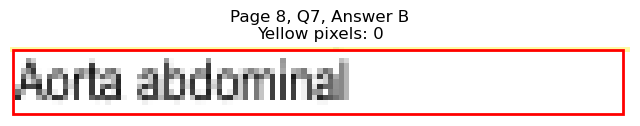

Page 8, Q7 - C: Detected box: x0=85.0, y0=651.4, x1=192.8, y1=663.5
Page 8, Q7, C: Yellow pixels: 0
Page 8, Q7, C: Total non-white pixels: 546
Page 8, Q7, C: Yellow percentage: 0.0%


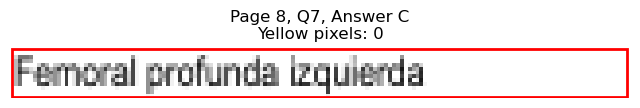

Page 8, Q7 - D: Detected box: x0=336.7, y0=627.3, x1=449.1, y1=639.4
Page 8, Q7, D: Yellow pixels: 0
Page 8, Q7, D: Total non-white pixels: 577
Page 8, Q7, D: Yellow percentage: 0.0%


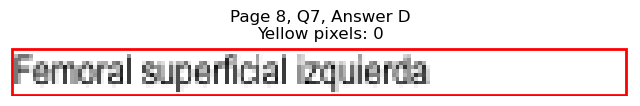

Page 8, Q7 - E: Detected box: x0=336.7, y0=639.3, x1=408.0, y1=651.4
Page 8, Q7, E: Yellow pixels: 0
Page 8, Q7, E: Total non-white pixels: 378
Page 8, Q7, E: Yellow percentage: 0.0%


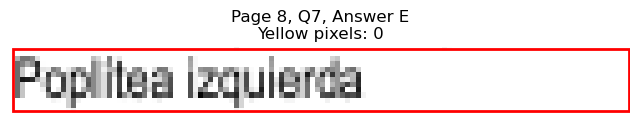


Page 8, Q7 - Selected Answer: A (based on yellow pixel count)




Page 8, Q8 - A: Detected box: x0=85.0, y0=699.5, x1=112.9, y1=711.7
Page 8, Q8, A: Yellow pixels: 0
Page 8, Q8, A: Total non-white pixels: 125
Page 8, Q8, A: Yellow percentage: 0.0%


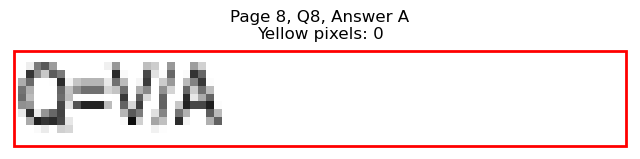

Page 8, Q8 - B: Detected box: x0=85.0, y0=711.7, x1=112.9, y1=723.8
Page 8, Q8, B: Yellow pixels: 0
Page 8, Q8, B: Total non-white pixels: 124
Page 8, Q8, B: Yellow percentage: 0.0%


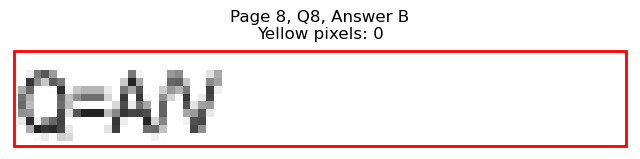

Page 8, Q8 - C: Detected box: x0=85.0, y0=723.7, x1=110.5, y1=735.8
Page 8, Q8, C: Yellow pixels: 0
Page 8, Q8, C: Total non-white pixels: 111
Page 8, Q8, C: Yellow percentage: 0.0%


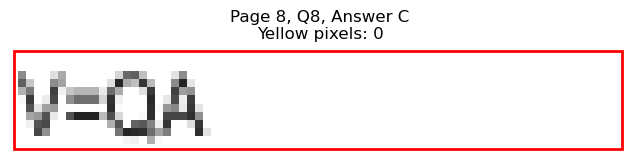

Page 8, Q8 - D: Detected box: x0=336.7, y0=699.5, x1=364.6, y1=711.7
Page 8, Q8, D: Yellow pixels: 0
Page 8, Q8, D: Total non-white pixels: 127
Page 8, Q8, D: Yellow percentage: 0.0%


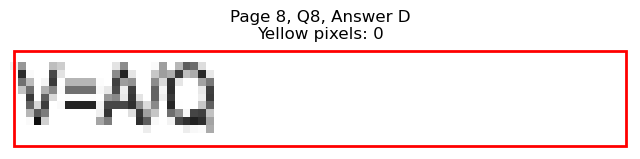

Page 8, Q8 - E: Detected box: x0=336.7, y0=711.7, x1=362.4, y1=723.8
Page 8, Q8, E: Yellow pixels: 829
Page 8, Q8, E: Total non-white pixels: 1001
Page 8, Q8, E: Yellow percentage: 82.8%


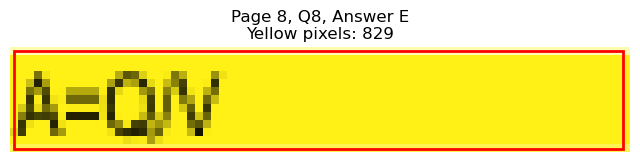


Page 8, Q8 - Selected Answer: E (based on yellow pixel count)





Page 9: Found 10 questions
Page 9, Q1 - A: Detected box: x0=85.0, y0=97.1, x1=243.4, y1=109.2
Page 9, Q1, A: Yellow pixels: 0
Page 9, Q1, A: Total non-white pixels: 800
Page 9, Q1, A: Yellow percentage: 0.0%


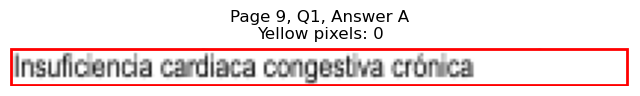

Page 9, Q1 - B: Detected box: x0=85.0, y0=109.2, x1=206.6, y1=121.3
Page 9, Q1, B: Yellow pixels: 1577
Page 9, Q1, B: Total non-white pixels: 2249
Page 9, Q1, B: Yellow percentage: 70.1%


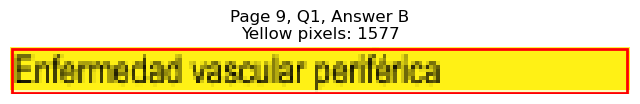

Page 9, Q1 - C: Detected box: x0=85.0, y0=121.2, x1=151.6, y1=133.3
Page 9, Q1, C: Yellow pixels: 0
Page 9, Q1, C: Total non-white pixels: 453
Page 9, Q1, C: Yellow percentage: 0.0%


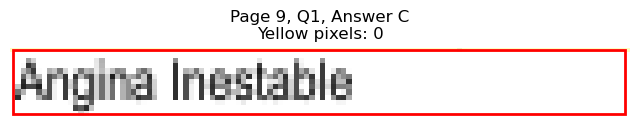

Page 9, Q1 - D: Detected box: x0=85.0, y0=133.2, x1=274.1, y1=145.3
Page 9, Q1, D: Yellow pixels: 0
Page 9, Q1, D: Total non-white pixels: 924
Page 9, Q1, D: Yellow percentage: 0.0%


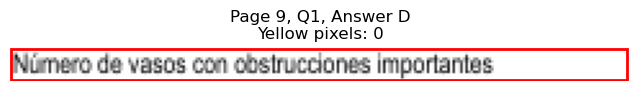

Page 9, Q1 - E: Detected box: x0=85.0, y0=145.3, x1=309.1, y1=157.4
Page 9, Q1, E: Yellow pixels: 0
Page 9, Q1, E: Total non-white pixels: 1126
Page 9, Q1, E: Yellow percentage: 0.0%


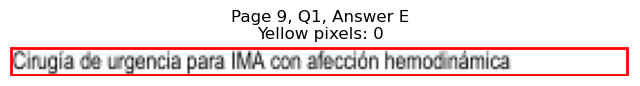


Page 9, Q1 - Selected Answer: B (based on yellow pixel count)




Page 9, Q2 - A: Detected box: x0=85.0, y0=181.4, x1=116.5, y1=193.5
Page 9, Q2, A: Yellow pixels: 0
Page 9, Q2, A: Total non-white pixels: 162
Page 9, Q2, A: Yellow percentage: 0.0%


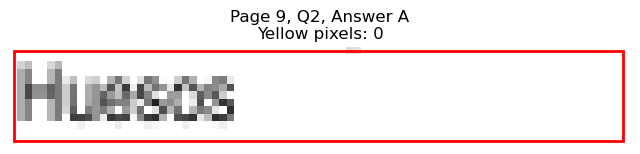

Page 9, Q2 - B: Detected box: x0=85.0, y0=193.4, x1=115.1, y1=205.5
Page 9, Q2, B: Yellow pixels: 0
Page 9, Q2, B: Total non-white pixels: 160
Page 9, Q2, B: Yellow percentage: 0.0%


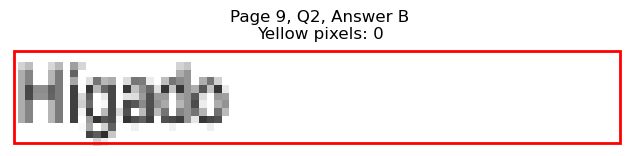

Page 9, Q2 - C: Detected box: x0=85.0, y0=205.5, x1=141.5, y1=217.7
Page 9, Q2, C: Yellow pixels: 0
Page 9, Q2, C: Total non-white pixels: 293
Page 9, Q2, C: Yellow percentage: 0.0%


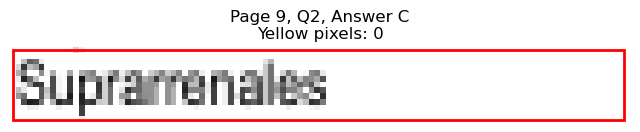

Page 9, Q2 - D: Detected box: x0=336.7, y0=181.4, x1=353.5, y1=193.5
Page 9, Q2, D: Yellow pixels: 811
Page 9, Q2, D: Total non-white pixels: 884
Page 9, Q2, D: Yellow percentage: 91.7%


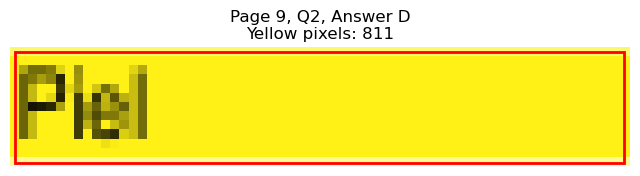

Page 9, Q2 - E: Detected box: x0=336.7, y0=193.4, x1=370.2, y1=205.5
Page 9, Q2, E: Yellow pixels: 85
Page 9, Q2, E: Total non-white pixels: 250
Page 9, Q2, E: Yellow percentage: 34.0%


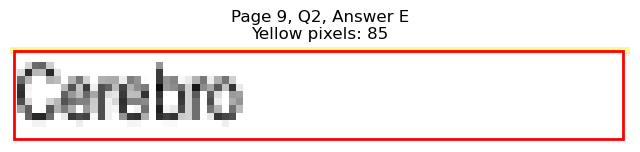


Page 9, Q2 - Selected Answer: D (based on yellow pixel count)




Page 9, Q3 - A: Detected box: x0=85.0, y0=253.7, x1=117.5, y1=265.8
Page 9, Q3, A: Yellow pixels: 0
Page 9, Q3, A: Total non-white pixels: 153
Page 9, Q3, A: Yellow percentage: 0.0%


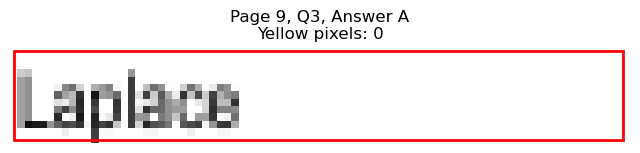

Page 9, Q3 - B: Detected box: x0=85.0, y0=265.8, x1=109.9, y1=277.9
Page 9, Q3, B: Yellow pixels: 0
Page 9, Q3, B: Total non-white pixels: 206
Page 9, Q3, B: Yellow percentage: 0.0%


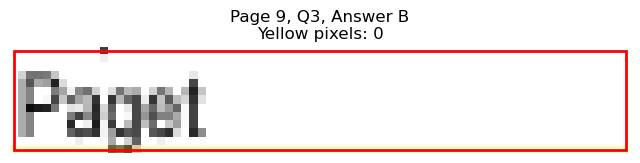

Page 9, Q3 - C: Detected box: x0=85.0, y0=277.8, x1=185.5, y1=289.9
Page 9, Q3, C: Yellow pixels: 1398
Page 9, Q3, C: Total non-white pixels: 1976
Page 9, Q3, C: Yellow percentage: 70.7%


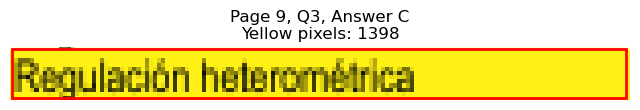

Page 9, Q3 - D: Detected box: x0=336.7, y0=253.7, x1=375.4, y1=265.8
Page 9, Q3, D: Yellow pixels: 0
Page 9, Q3, D: Total non-white pixels: 200
Page 9, Q3, D: Yellow percentage: 0.0%


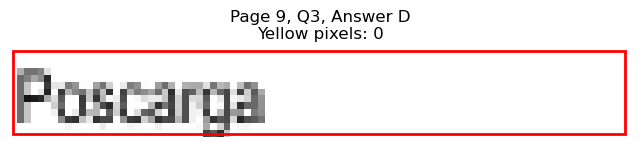

Page 9, Q3 - E: Detected box: x0=336.7, y0=265.8, x1=439.2, y1=277.9
Page 9, Q3, E: Yellow pixels: 0
Page 9, Q3, E: Total non-white pixels: 545
Page 9, Q3, E: Yellow percentage: 0.0%


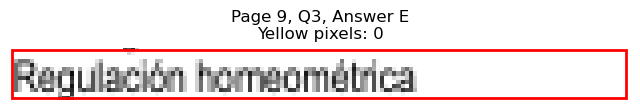


Page 9, Q3 - Selected Answer: C (based on yellow pixel count)




Page 9, Q4 - A: Detected box: x0=85.0, y0=313.9, x1=201.3, y1=326.0
Page 9, Q4, A: Yellow pixels: 0
Page 9, Q4, A: Total non-white pixels: 615
Page 9, Q4, A: Yellow percentage: 0.0%


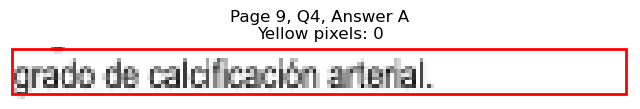

Page 9, Q4 - B: Detected box: x0=85.0, y0=326.1, x1=166.8, y1=338.2
Page 9, Q4, B: Yellow pixels: 0
Page 9, Q4, B: Total non-white pixels: 408
Page 9, Q4, B: Yellow percentage: 0.0%


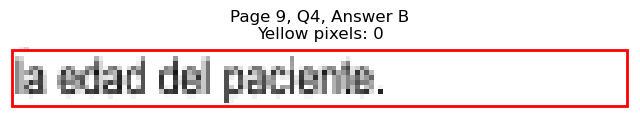

Page 9, Q4 - C: Detected box: x0=85.0, y0=338.1, x1=185.5, y1=350.2
Page 9, Q4, C: Yellow pixels: 0
Page 9, Q4, C: Total non-white pixels: 492
Page 9, Q4, C: Yellow percentage: 0.0%


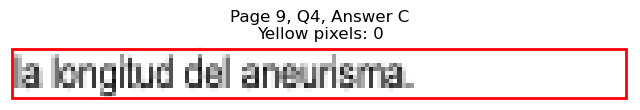

Page 9, Q4 - D: Detected box: x0=336.7, y0=313.9, x1=427.6, y1=326.0
Page 9, Q4, D: Yellow pixels: 0
Page 9, Q4, D: Total non-white pixels: 464
Page 9, Q4, D: Yellow percentage: 0.0%


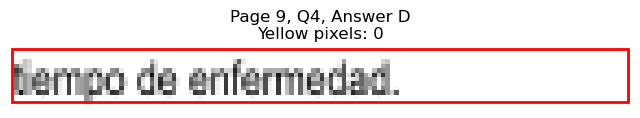

Page 9, Q4 - E: Detected box: x0=336.7, y0=326.1, x1=431.5, y1=338.2
Page 9, Q4, E: Yellow pixels: 1395
Page 9, Q4, E: Total non-white pixels: 1898
Page 9, Q4, E: Yellow percentage: 73.5%


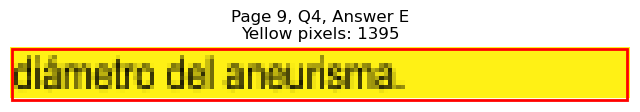


Page 9, Q4 - Selected Answer: E (based on yellow pixel count)




Page 9, Q5 - A: Detected box: x0=85.0, y0=374.2, x1=179.8, y1=386.3
Page 9, Q5, A: Yellow pixels: 0
Page 9, Q5, A: Total non-white pixels: 461
Page 9, Q5, A: Yellow percentage: 0.0%


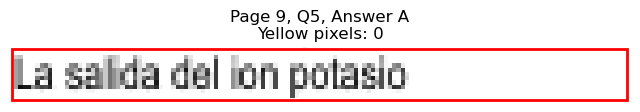

Page 9, Q5 - B: Detected box: x0=85.0, y0=386.3, x1=177.9, y1=398.4
Page 9, Q5, B: Yellow pixels: 0
Page 9, Q5, B: Total non-white pixels: 439
Page 9, Q5, B: Yellow percentage: 0.0%


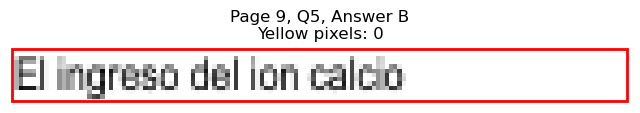

Page 9, Q5 - C: Detected box: x0=85.0, y0=398.3, x1=183.6, y1=410.4
Page 9, Q5, C: Yellow pixels: 0
Page 9, Q5, C: Total non-white pixels: 471
Page 9, Q5, C: Yellow percentage: 0.0%


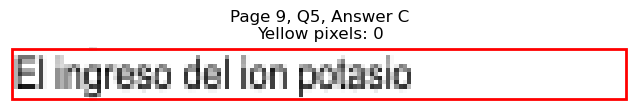

Page 9, Q5 - D: Detected box: x0=336.7, y0=374.2, x1=421.4, y1=386.3
Page 9, Q5, D: Yellow pixels: 0
Page 9, Q5, D: Total non-white pixels: 400
Page 9, Q5, D: Yellow percentage: 0.0%


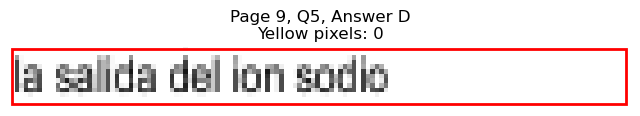

Page 9, Q5 - E: Detected box: x0=336.7, y0=386.3, x1=428.1, y1=398.4
Page 9, Q5, E: Yellow pixels: 1343
Page 9, Q5, E: Total non-white pixels: 1859
Page 9, Q5, E: Yellow percentage: 72.2%


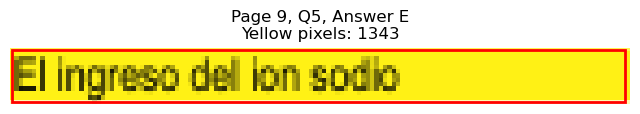


Page 9, Q5 - Selected Answer: E (based on yellow pixel count)




Page 9, Q6 - A: Detected box: x0=85.0, y0=446.6, x1=130.9, y1=458.7
Page 9, Q6, A: Yellow pixels: 0
Page 9, Q6, A: Total non-white pixels: 255
Page 9, Q6, A: Yellow percentage: 0.0%


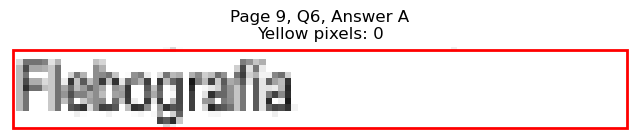

Page 9, Q6 - B: Detected box: x0=85.0, y0=458.6, x1=158.7, y1=470.7
Page 9, Q6, B: Yellow pixels: 0
Page 9, Q6, B: Total non-white pixels: 414
Page 9, Q6, B: Yellow percentage: 0.0%


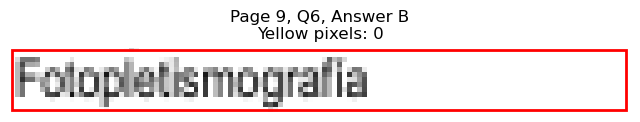

Page 9, Q6 - C: Detected box: x0=85.0, y0=470.7, x1=169.2, y1=482.8
Page 9, Q6, C: Yellow pixels: 0
Page 9, Q6, C: Total non-white pixels: 465
Page 9, Q6, C: Yellow percentage: 0.0%


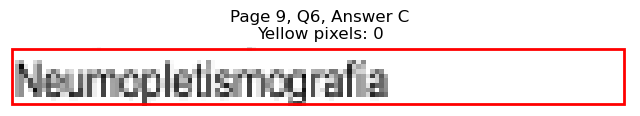

Page 9, Q6 - D: Detected box: x0=336.7, y0=446.6, x1=382.7, y1=458.7
Page 9, Q6, D: Yellow pixels: 1067
Page 9, Q6, D: Total non-white pixels: 1261
Page 9, Q6, D: Yellow percentage: 84.6%


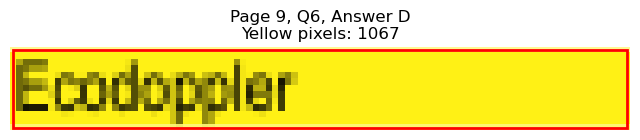

Page 9, Q6 - E: Detected box: x0=336.7, y0=458.6, x1=383.1, y1=470.7
Page 9, Q6, E: Yellow pixels: 98
Page 9, Q6, E: Total non-white pixels: 320
Page 9, Q6, E: Yellow percentage: 30.6%


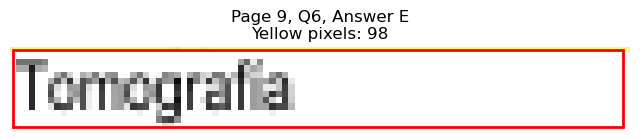


Page 9, Q6 - Selected Answer: D (based on yellow pixel count)




Page 9, Q7 - A: Detected box: x0=85.0, y0=506.8, x1=314.3, y1=518.9
Page 9, Q7, A: Yellow pixels: 0
Page 9, Q7, A: Total non-white pixels: 1140
Page 9, Q7, A: Yellow percentage: 0.0%


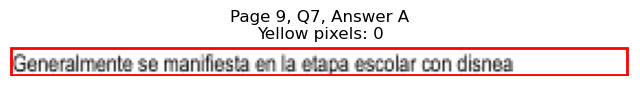

Page 9, Q7 - B: Detected box: x0=85.0, y0=518.8, x1=370.3, y1=530.9
Page 9, Q7, B: Yellow pixels: 0
Page 9, Q7, B: Total non-white pixels: 1371
Page 9, Q7, B: Yellow percentage: 0.0%


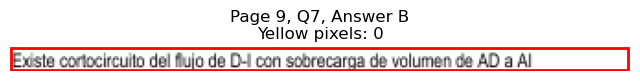

Page 9, Q7 - C: Detected box: x0=85.0, y0=530.9, x1=381.3, y1=543.0
Page 9, Q7, C: Yellow pixels: 348
Page 9, Q7, C: Total non-white pixels: 2144
Page 9, Q7, C: Yellow percentage: 16.2%


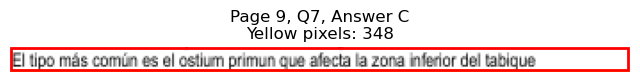

Page 9, Q7 - D: Detected box: x0=85.0, y0=542.9, x1=415.8, y1=555.0
Page 9, Q7, D: Yellow pixels: 3253
Page 9, Q7, D: Total non-white pixels: 4970
Page 9, Q7, D: Yellow percentage: 65.5%


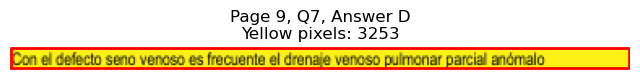

Page 9, Q7 - E: Detected box: x0=85.0, y0=554.9, x1=302.8, y1=567.0
Page 9, Q7, E: Yellow pixels: 266
Page 9, Q7, E: Total non-white pixels: 1401
Page 9, Q7, E: Yellow percentage: 19.0%


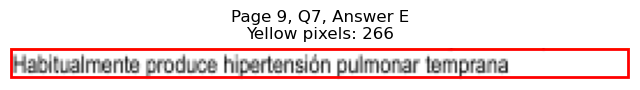


Page 9, Q7 - Selected Answer: D (based on yellow pixel count)




Page 9, Q8 - A: Detected box: x0=85.0, y0=591.2, x1=239.6, y1=603.3
Page 9, Q8, A: Yellow pixels: 0
Page 9, Q8, A: Total non-white pixels: 748
Page 9, Q8, A: Yellow percentage: 0.0%


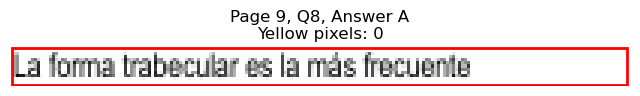

Page 9, Q8 - B: Detected box: x0=85.0, y0=603.2, x1=359.2, y1=615.3
Page 9, Q8, B: Yellow pixels: 326
Page 9, Q8, B: Total non-white pixels: 1679
Page 9, Q8, B: Yellow percentage: 19.4%


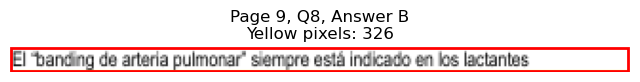

Page 9, Q8 - C: Detected box: x0=85.0, y0=615.2, x1=526.5, y1=627.3
Page 9, Q8, C: Yellow pixels: 3656
Page 9, Q8, C: Total non-white pixels: 5746
Page 9, Q8, C: Yellow percentage: 63.6%


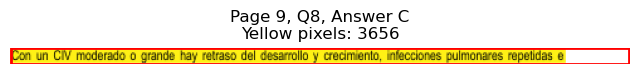

Page 9, Q8 - D: Detected box: x0=85.0, y0=639.3, x1=347.8, y1=651.4
Page 9, Q8, D: Yellow pixels: 1
Page 9, Q8, D: Total non-white pixels: 1622
Page 9, Q8, D: Yellow percentage: 0.1%


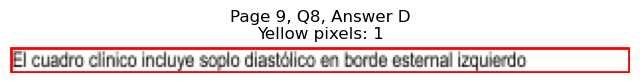

Page 9, Q8 - E: Detected box: x0=85.0, y0=651.4, x1=296.6, y1=663.5
Page 9, Q8, E: Yellow pixels: 0
Page 9, Q8, E: Total non-white pixels: 1089
Page 9, Q8, E: Yellow percentage: 0.0%


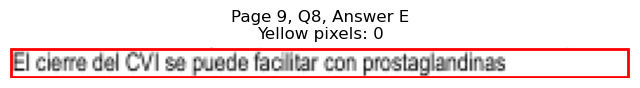


Page 9, Q8 - Selected Answer: C (based on yellow pixel count)




Page 9, Q9 - A: Detected box: x0=85.0, y0=687.5, x1=106.1, y1=699.7
Page 9, Q9, A: Yellow pixels: 73
Page 9, Q9, A: Total non-white pixels: 167
Page 9, Q9, A: Yellow percentage: 43.7%


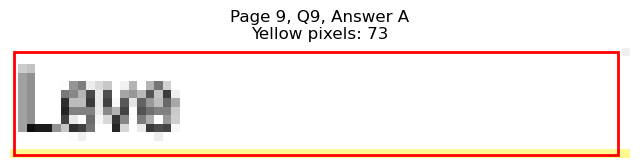

Page 9, Q9 - B: Detected box: x0=85.0, y0=699.5, x1=122.3, y1=711.7
Page 9, Q9, B: Yellow pixels: 1014
Page 9, Q9, B: Total non-white pixels: 1157
Page 9, Q9, B: Yellow percentage: 87.6%


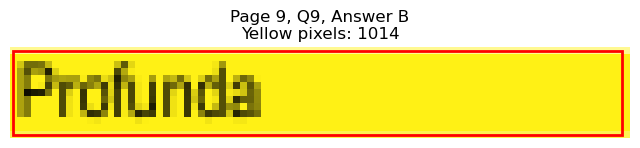

Page 9, Q9 - C: Detected box: x0=85.0, y0=711.7, x1=126.1, y1=723.8
Page 9, Q9, C: Yellow pixels: 93
Page 9, Q9, C: Total non-white pixels: 317
Page 9, Q9, C: Yellow percentage: 29.3%


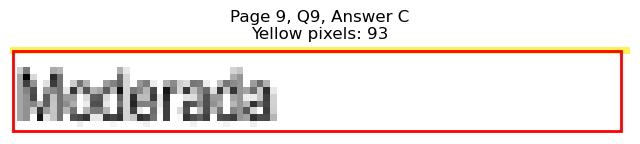

Page 9, Q9 - D: Detected box: x0=336.7, y0=687.5, x1=391.8, y1=699.7
Page 9, Q9, D: Yellow pixels: 0
Page 9, Q9, D: Total non-white pixels: 275
Page 9, Q9, D: Yellow percentage: 0.0%


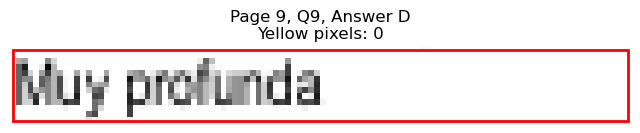

Page 9, Q9 - E: Detected box: x0=336.7, y0=699.5, x1=441.1, y1=711.7
Page 9, Q9, E: Yellow pixels: 0
Page 9, Q9, E: Total non-white pixels: 522
Page 9, Q9, E: Yellow percentage: 0.0%


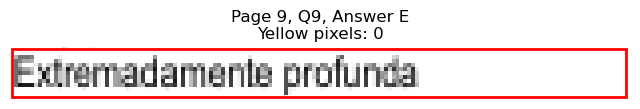


Page 9, Q9 - Selected Answer: B (based on yellow pixel count)




Page 9, Q10 - A: Detected box: x0=85.0, y0=747.8, x1=192.8, y1=759.9
Page 9, Q10, A: Yellow pixels: 0
Page 9, Q10, A: Total non-white pixels: 589
Page 9, Q10, A: Yellow percentage: 0.0%


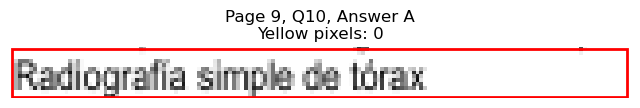

Page 9, Q10 - B: Detected box: x0=85.0, y0=759.8, x1=147.7, y1=771.9
Page 9, Q10, B: Yellow pixels: 0
Page 9, Q10, B: Total non-white pixels: 341
Page 9, Q10, B: Yellow percentage: 0.0%


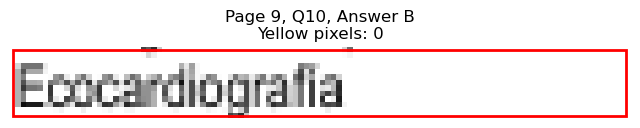

Page 9, Q10 - C: Detected box: x0=85.0, y0=771.9, x1=190.4, y1=784.0
Page 9, Q10, C: Yellow pixels: 1475
Page 9, Q10, C: Total non-white pixels: 2044
Page 9, Q10, C: Yellow percentage: 72.2%


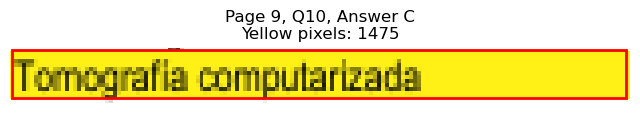

Page 9, Q10 - D: Detected box: x0=336.7, y0=747.8, x1=442.5, y1=759.9
Page 9, Q10, D: Yellow pixels: 0
Page 9, Q10, D: Total non-white pixels: 525
Page 9, Q10, D: Yellow percentage: 0.0%


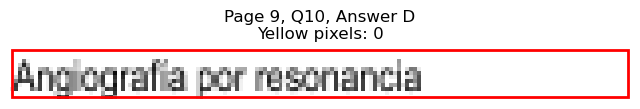

Page 9, Q10 - E: Detected box: x0=336.7, y0=759.8, x1=418.2, y1=771.9
Page 9, Q10, E: Yellow pixels: 0
Page 9, Q10, E: Total non-white pixels: 461
Page 9, Q10, E: Yellow percentage: 0.0%


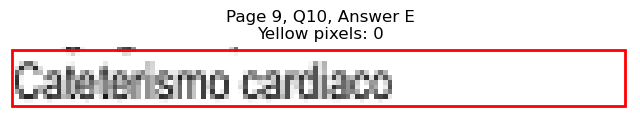


Page 9, Q10 - Selected Answer: C (based on yellow pixel count)





Page 10: Found 8 questions
Page 10, Q1 - A: Detected box: x0=85.0, y0=133.2, x1=153.5, y1=145.3
Page 10, Q1, A: Yellow pixels: 0
Page 10, Q1, A: Total non-white pixels: 367
Page 10, Q1, A: Yellow percentage: 0.0%


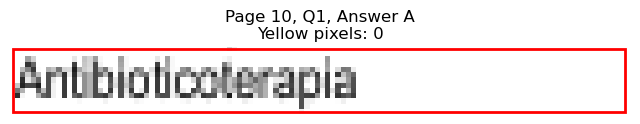

Page 10, Q1 - B: Detected box: x0=85.0, y0=145.3, x1=163.1, y1=157.4
Page 10, Q1, B: Yellow pixels: 130
Page 10, Q1, B: Total non-white pixels: 549
Page 10, Q1, B: Yellow percentage: 23.7%


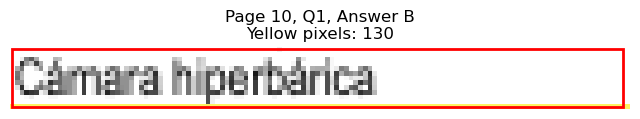

Page 10, Q1 - C: Detected box: x0=85.0, y0=157.3, x1=157.2, y1=169.4
Page 10, Q1, C: Yellow pixels: 1301
Page 10, Q1, C: Total non-white pixels: 1612
Page 10, Q1, C: Yellow percentage: 80.7%


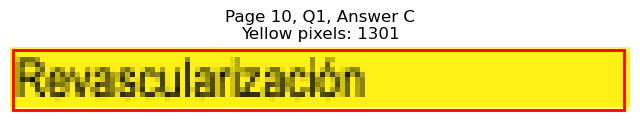

Page 10, Q1 - D: Detected box: x0=336.7, y0=133.2, x1=411.8, y1=145.3
Page 10, Q1, D: Yellow pixels: 0
Page 10, Q1, D: Total non-white pixels: 369
Page 10, Q1, D: Yellow percentage: 0.0%


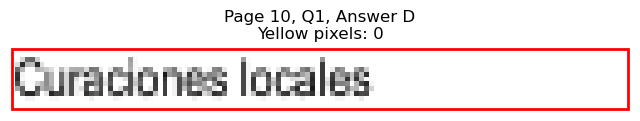

Page 10, Q1 - E: Detected box: x0=336.7, y0=145.3, x1=403.8, y1=157.4
Page 10, Q1, E: Yellow pixels: 0
Page 10, Q1, E: Total non-white pixels: 326
Page 10, Q1, E: Yellow percentage: 0.0%


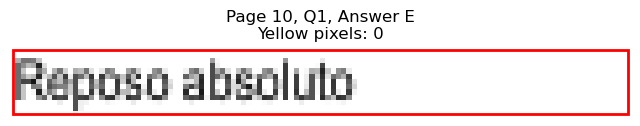


Page 10, Q1 - Selected Answer: C (based on yellow pixel count)




Page 10, Q2 - A: Detected box: x0=85.0, y0=205.5, x1=187.9, y1=217.7
Page 10, Q2, A: Yellow pixels: 0
Page 10, Q2, A: Total non-white pixels: 475
Page 10, Q2, A: Yellow percentage: 0.0%


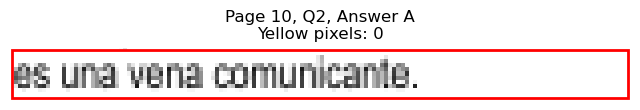

Page 10, Q2 - B: Detected box: x0=85.0, y0=217.5, x1=154.0, y1=229.7
Page 10, Q2, B: Yellow pixels: 0
Page 10, Q2, B: Total non-white pixels: 328
Page 10, Q2, B: Yellow percentage: 0.0%


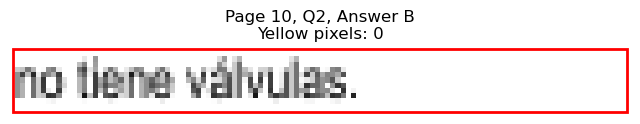

Page 10, Q2 - C: Detected box: x0=85.0, y0=229.7, x1=235.7, y1=241.8
Page 10, Q2, C: Yellow pixels: 0
Page 10, Q2, C: Total non-white pixels: 719
Page 10, Q2, C: Yellow percentage: 0.0%


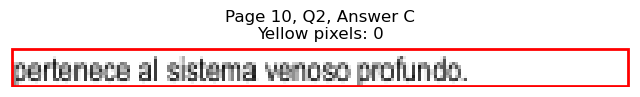

Page 10, Q2 - D: Detected box: x0=336.7, y0=205.5, x1=492.2, y1=217.7
Page 10, Q2, D: Yellow pixels: 1856
Page 10, Q2, D: Total non-white pixels: 2470
Page 10, Q2, D: Yellow percentage: 75.1%


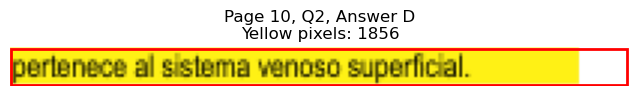

Page 10, Q2 - E: Detected box: x0=336.7, y0=217.5, x1=440.6, y1=229.7
Page 10, Q2, E: Yellow pixels: 155
Page 10, Q2, E: Total non-white pixels: 673
Page 10, Q2, E: Yellow percentage: 23.0%


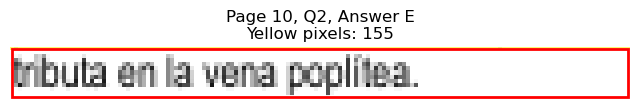


Page 10, Q2 - Selected Answer: D (based on yellow pixel count)




Page 10, Q3 - A: Detected box: x0=85.0, y0=277.8, x1=261.2, y1=289.9
Page 10, Q3, A: Yellow pixels: 0
Page 10, Q3, A: Total non-white pixels: 874
Page 10, Q3, A: Yellow percentage: 0.0%


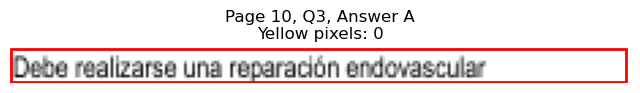

Page 10, Q3 - B: Detected box: x0=85.0, y0=289.9, x1=311.9, y1=302.0
Page 10, Q3, B: Yellow pixels: 0
Page 10, Q3, B: Total non-white pixels: 1123
Page 10, Q3, B: Yellow percentage: 0.0%


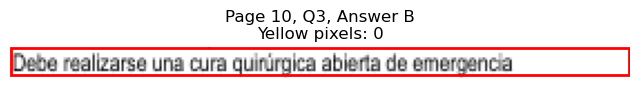

Page 10, Q3 - C: Detected box: x0=85.0, y0=301.9, x1=284.1, y1=314.0
Page 10, Q3, C: Yellow pixels: 251
Page 10, Q3, C: Total non-white pixels: 1481
Page 10, Q3, C: Yellow percentage: 16.9%


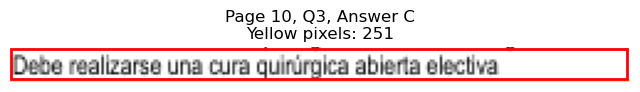

Page 10, Q3 - D: Detected box: x0=85.0, y0=313.9, x1=240.1, y1=326.0
Page 10, Q3, D: Yellow pixels: 1855
Page 10, Q3, D: Total non-white pixels: 2898
Page 10, Q3, D: Yellow percentage: 64.0%


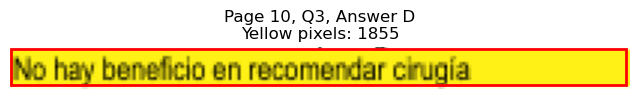

Page 10, Q3 - E: Detected box: x0=85.0, y0=326.1, x1=470.9, y1=338.2
Page 10, Q3, E: Yellow pixels: 0
Page 10, Q3, E: Total non-white pixels: 2387
Page 10, Q3, E: Yellow percentage: 0.0%


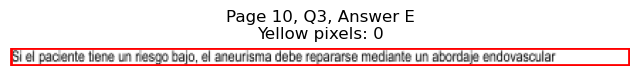


Page 10, Q3 - Selected Answer: D (based on yellow pixel count)




Page 10, Q4 - A: Detected box: x0=85.0, y0=374.2, x1=132.4, y1=386.3
Page 10, Q4, A: Yellow pixels: 0
Page 10, Q4, A: Total non-white pixels: 247
Page 10, Q4, A: Yellow percentage: 0.0%


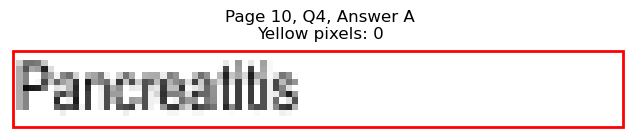

Page 10, Q4 - B: Detected box: x0=85.0, y0=386.3, x1=185.1, y1=398.4
Page 10, Q4, B: Yellow pixels: 0
Page 10, Q4, B: Total non-white pixels: 518
Page 10, Q4, B: Yellow percentage: 0.0%


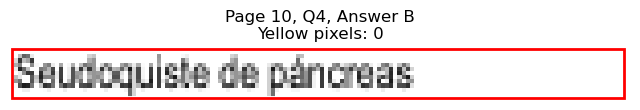

Page 10, Q4 - C: Detected box: x0=85.0, y0=398.3, x1=126.1, y1=410.4
Page 10, Q4, C: Yellow pixels: 0
Page 10, Q4, C: Total non-white pixels: 205
Page 10, Q4, C: Yellow percentage: 0.0%


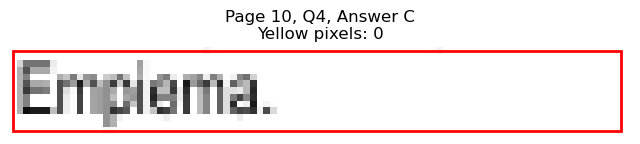

Page 10, Q4 - D: Detected box: x0=336.7, y0=374.2, x1=408.4, y1=386.3
Page 10, Q4, D: Yellow pixels: 0
Page 10, Q4, D: Total non-white pixels: 403
Page 10, Q4, D: Yellow percentage: 0.0%


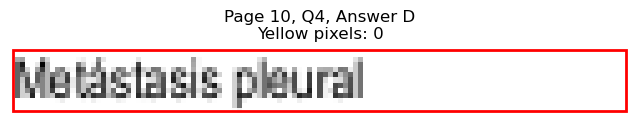

Page 10, Q4 - E: Detected box: x0=336.7, y0=386.3, x1=404.2, y1=398.4
Page 10, Q4, E: Yellow pixels: 1121
Page 10, Q4, E: Total non-white pixels: 1547
Page 10, Q4, E: Yellow percentage: 72.5%


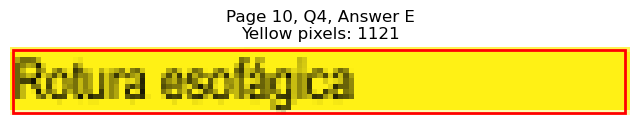


Page 10, Q4 - Selected Answer: E (based on yellow pixel count)




Page 10, Q5 - A: Detected box: x0=85.0, y0=458.6, x1=134.3, y1=470.7
Page 10, Q5, A: Yellow pixels: 0
Page 10, Q5, A: Total non-white pixels: 265
Page 10, Q5, A: Yellow percentage: 0.0%


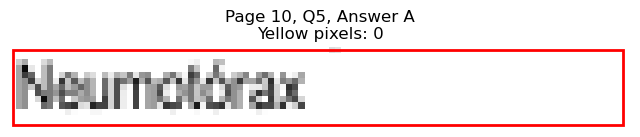

Page 10, Q5 - B: Detected box: x0=85.0, y0=470.7, x1=182.7, y1=482.8
Page 10, Q5, B: Yellow pixels: 1394
Page 10, Q5, B: Total non-white pixels: 1937
Page 10, Q5, B: Yellow percentage: 72.0%


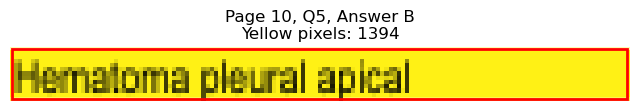

Page 10, Q5 - C: Detected box: x0=85.0, y0=482.7, x1=201.8, y1=494.8
Page 10, Q5, C: Yellow pixels: 166
Page 10, Q5, C: Total non-white pixels: 764
Page 10, Q5, C: Yellow percentage: 21.7%


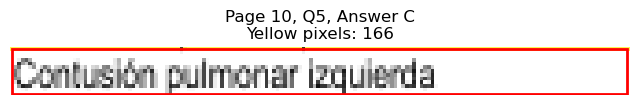

Page 10, Q5 - D: Detected box: x0=336.7, y0=458.6, x1=480.8, y1=470.7
Page 10, Q5, D: Yellow pixels: 0
Page 10, Q5, D: Total non-white pixels: 762
Page 10, Q5, D: Yellow percentage: 0.0%


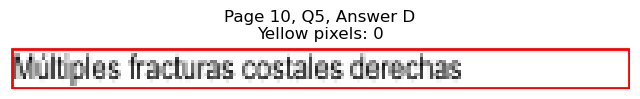

Page 10, Q5 - E: Detected box: x0=336.7, y0=470.7, x1=408.4, y1=482.8
Page 10, Q5, E: Yellow pixels: 0
Page 10, Q5, E: Total non-white pixels: 376
Page 10, Q5, E: Yellow percentage: 0.0%


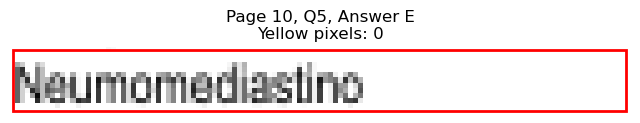


Page 10, Q5 - Selected Answer: B (based on yellow pixel count)




Page 10, Q6 - A: Detected box: x0=85.0, y0=530.9, x1=97.0, y1=543.0
Page 10, Q6, A: Yellow pixels: 713
Page 10, Q6, A: Total non-white pixels: 819
Page 10, Q6, A: Yellow percentage: 87.1%


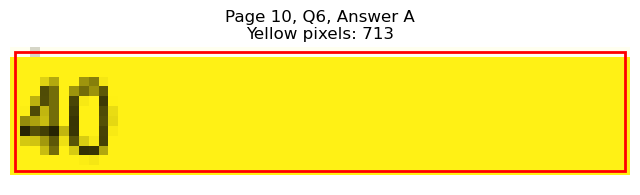

Page 10, Q6 - B: Detected box: x0=85.0, y0=542.9, x1=97.0, y1=555.0
Page 10, Q6, B: Yellow pixels: 63
Page 10, Q6, B: Total non-white pixels: 110
Page 10, Q6, B: Yellow percentage: 57.3%


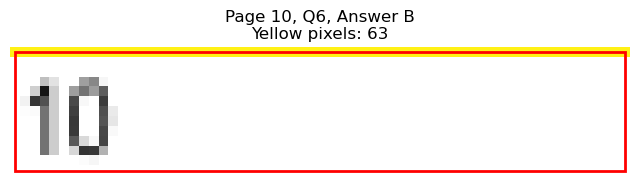

Page 10, Q6 - C: Detected box: x0=85.0, y0=554.9, x1=97.0, y1=567.0
Page 10, Q6, C: Yellow pixels: 0
Page 10, Q6, C: Total non-white pixels: 53
Page 10, Q6, C: Yellow percentage: 0.0%


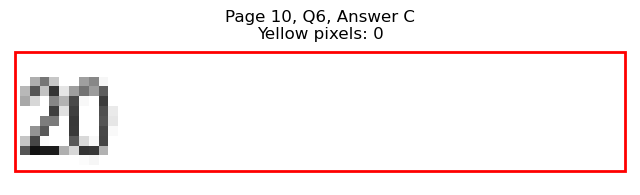

Page 10, Q6 - D: Detected box: x0=336.7, y0=530.9, x1=348.7, y1=543.0
Page 10, Q6, D: Yellow pixels: 0
Page 10, Q6, D: Total non-white pixels: 56
Page 10, Q6, D: Yellow percentage: 0.0%


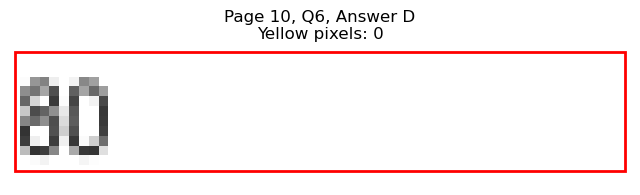

Page 10, Q6 - E: Detected box: x0=336.7, y0=542.9, x1=348.7, y1=555.0
Page 10, Q6, E: Yellow pixels: 0
Page 10, Q6, E: Total non-white pixels: 56
Page 10, Q6, E: Yellow percentage: 0.0%


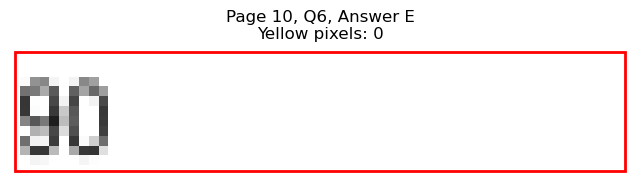


Page 10, Q6 - Selected Answer: A (based on yellow pixel count)




Page 10, Q7 - A: Detected box: x0=85.0, y0=615.2, x1=209.0, y1=627.3
Page 10, Q7, A: Yellow pixels: 0
Page 10, Q7, A: Total non-white pixels: 603
Page 10, Q7, A: Yellow percentage: 0.0%


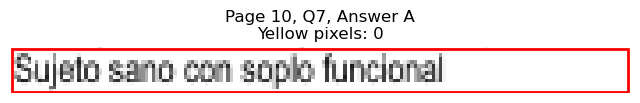

Page 10, Q7 - B: Detected box: x0=85.0, y0=627.3, x1=207.5, y1=639.4
Page 10, Q7, B: Yellow pixels: 0
Page 10, Q7, B: Total non-white pixels: 623
Page 10, Q7, B: Yellow percentage: 0.0%


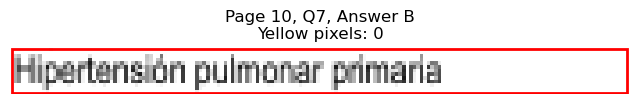

Page 10, Q7 - C: Detected box: x0=85.0, y0=639.3, x1=181.2, y1=651.4
Page 10, Q7, C: Yellow pixels: 0
Page 10, Q7, C: Total non-white pixels: 488
Page 10, Q7, C: Yellow percentage: 0.0%


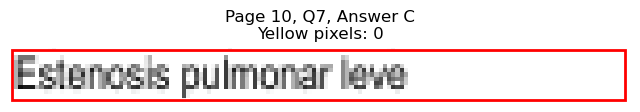

Page 10, Q7 - D: Detected box: x0=336.7, y0=615.2, x1=462.6, y1=627.3
Page 10, Q7, D: Yellow pixels: 0
Page 10, Q7, D: Total non-white pixels: 644
Page 10, Q7, D: Yellow percentage: 0.0%


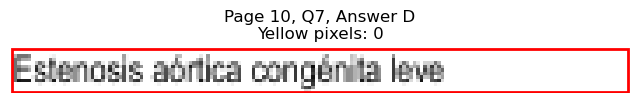

Page 10, Q7 - E: Detected box: x0=336.7, y0=627.3, x1=445.8, y1=639.4
Page 10, Q7, E: Yellow pixels: 1503
Page 10, Q7, E: Total non-white pixels: 2080
Page 10, Q7, E: Yellow percentage: 72.3%


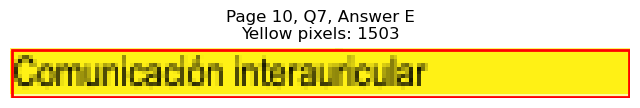


Page 10, Q7 - Selected Answer: E (based on yellow pixel count)




Page 10, Q8 - A: Detected box: x0=85.0, y0=687.5, x1=203.2, y1=699.7
Page 10, Q8, A: Yellow pixels: 0
Page 10, Q8, A: Total non-white pixels: 632
Page 10, Q8, A: Yellow percentage: 0.0%


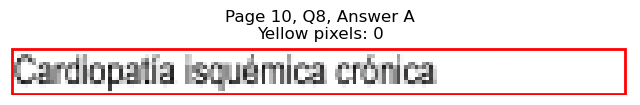

Page 10, Q8 - B: Detected box: x0=85.0, y0=699.5, x1=187.9, y1=711.7
Page 10, Q8, B: Yellow pixels: 0
Page 10, Q8, B: Total non-white pixels: 547
Page 10, Q8, B: Yellow percentage: 0.0%


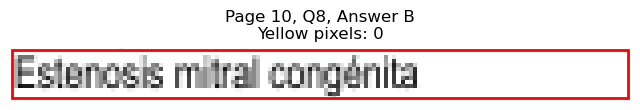

Page 10, Q8 - C: Detected box: x0=85.0, y0=711.7, x1=191.8, y1=723.8
Page 10, Q8, C: Yellow pixels: 1451
Page 10, Q8, C: Total non-white pixels: 2054
Page 10, Q8, C: Yellow percentage: 70.6%


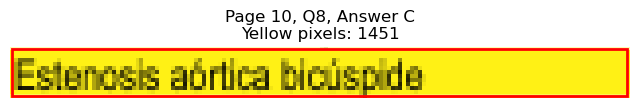

Page 10, Q8 - D: Detected box: x0=336.7, y0=687.5, x1=431.0, y1=699.7
Page 10, Q8, D: Yellow pixels: 0
Page 10, Q8, D: Total non-white pixels: 506
Page 10, Q8, D: Yellow percentage: 0.0%


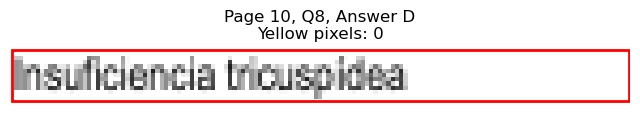

Page 10, Q8 - E: Detected box: x0=336.7, y0=699.5, x1=412.4, y1=711.7
Page 10, Q8, E: Yellow pixels: 0
Page 10, Q8, E: Total non-white pixels: 400
Page 10, Q8, E: Yellow percentage: 0.0%


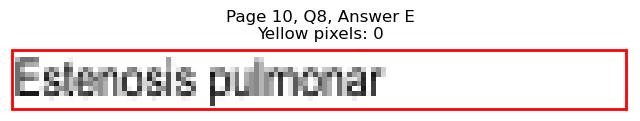


Page 10, Q8 - Selected Answer: C (based on yellow pixel count)





Page 11: Found 9 questions
Page 11, Q1 - A: Detected box: x0=70.8, y0=133.2, x1=79.0, y1=145.3
Page 11, Q1, A: Yellow pixels: 0
Page 11, Q1, A: Total non-white pixels: 58
Page 11, Q1, A: Yellow percentage: 0.0%


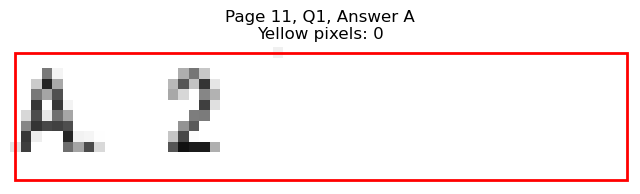

Page 11, Q1 - B: Detected box: x0=70.8, y0=145.3, x1=79.0, y1=157.4
Page 11, Q1, B: Yellow pixels: 0
Page 11, Q1, B: Total non-white pixels: 69
Page 11, Q1, B: Yellow percentage: 0.0%


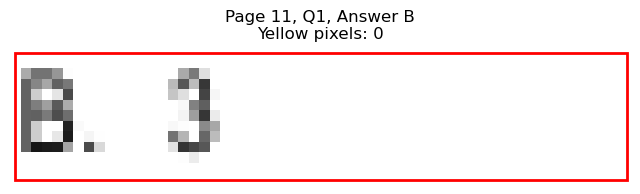

Page 11, Q1 - C: Detected box: x0=70.8, y0=157.3, x1=79.5, y1=169.4
Page 11, Q1, C: Yellow pixels: 0
Page 11, Q1, C: Total non-white pixels: 61
Page 11, Q1, C: Yellow percentage: 0.0%


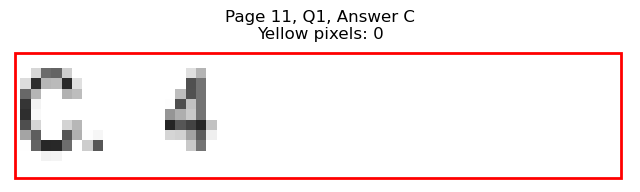

Page 11, Q1 - D: Detected box: x0=322.5, y0=133.2, x1=331.2, y1=145.3
Page 11, Q1, D: Yellow pixels: 681
Page 11, Q1, D: Total non-white pixels: 780
Page 11, Q1, D: Yellow percentage: 87.3%


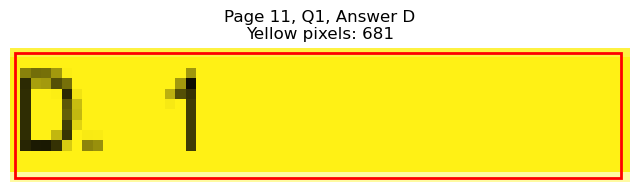

Page 11, Q1 - E: Detected box: x0=322.5, y0=145.3, x1=330.7, y1=157.4
Page 11, Q1, E: Yellow pixels: 0
Page 11, Q1, E: Total non-white pixels: 120
Page 11, Q1, E: Yellow percentage: 0.0%


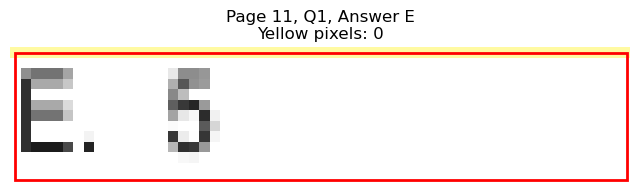


Page 11, Q1 - Selected Answer: D (based on yellow pixel count)




Page 11, Q2 - A: Detected box: x0=85.0, y0=193.4, x1=138.6, y1=205.5
Page 11, Q2, A: Yellow pixels: 1134
Page 11, Q2, A: Total non-white pixels: 1365
Page 11, Q2, A: Yellow percentage: 83.1%


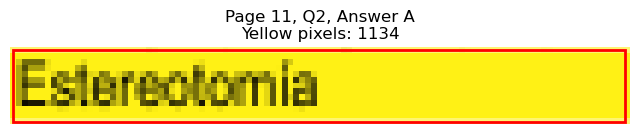

Page 11, Q2 - B: Detected box: x0=85.0, y0=205.5, x1=142.5, y1=217.7
Page 11, Q2, B: Yellow pixels: 109
Page 11, Q2, B: Total non-white pixels: 363
Page 11, Q2, B: Yellow percentage: 30.0%


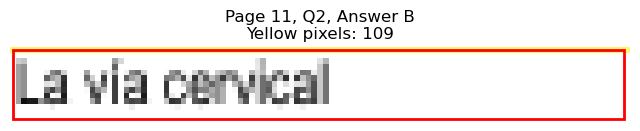

Page 11, Q2 - C: Detected box: x0=85.0, y0=217.5, x1=170.7, y1=229.7
Page 11, Q2, C: Yellow pixels: 0
Page 11, Q2, C: Total non-white pixels: 397
Page 11, Q2, C: Yellow percentage: 0.0%


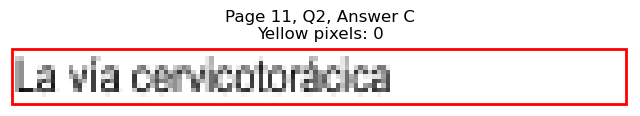

Page 11, Q2 - D: Detected box: x0=336.7, y0=193.4, x1=443.5, y1=205.5
Page 11, Q2, D: Yellow pixels: 0
Page 11, Q2, D: Total non-white pixels: 518
Page 11, Q2, D: Yellow percentage: 0.0%


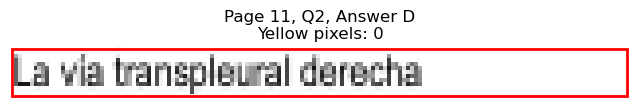

Page 11, Q2 - E: Detected box: x0=336.7, y0=205.5, x1=447.3, y1=217.7
Page 11, Q2, E: Yellow pixels: 0
Page 11, Q2, E: Total non-white pixels: 555
Page 11, Q2, E: Yellow percentage: 0.0%


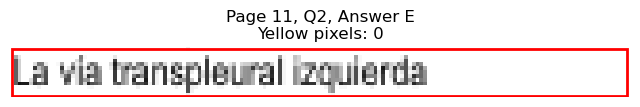


Page 11, Q2 - Selected Answer: A (based on yellow pixel count)




Page 11, Q3 - A: Detected box: x0=85.0, y0=265.8, x1=157.2, y1=277.9
Page 11, Q3, A: Yellow pixels: 0
Page 11, Q3, A: Total non-white pixels: 340
Page 11, Q3, A: Yellow percentage: 0.0%


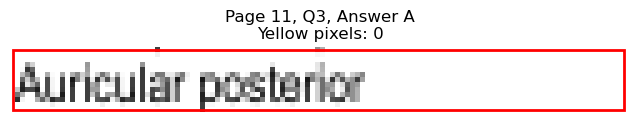

Page 11, Q3 - B: Detected box: x0=85.0, y0=277.8, x1=151.1, y1=289.9
Page 11, Q3, B: Yellow pixels: 0
Page 11, Q3, B: Total non-white pixels: 356
Page 11, Q3, B: Yellow percentage: 0.0%


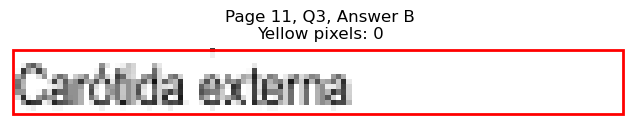

Page 11, Q3 - C: Detected box: x0=85.0, y0=289.9, x1=110.3, y1=302.0
Page 11, Q3, C: Yellow pixels: 0
Page 11, Q3, C: Total non-white pixels: 133
Page 11, Q3, C: Yellow percentage: 0.0%


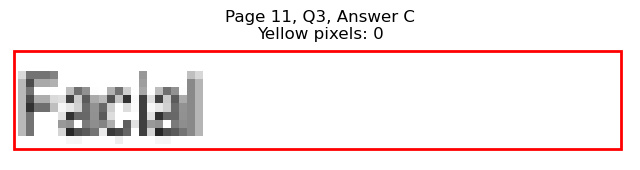

Page 11, Q3 - D: Detected box: x0=336.7, y0=265.8, x1=365.8, y1=277.9
Page 11, Q3, D: Yellow pixels: 822
Page 11, Q3, D: Total non-white pixels: 1040
Page 11, Q3, D: Yellow percentage: 79.0%


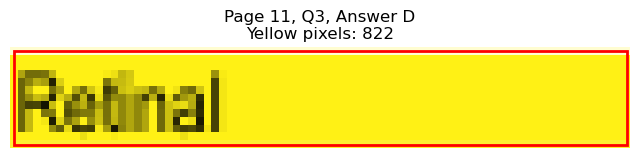

Page 11, Q3 - E: Detected box: x0=336.7, y0=277.8, x1=372.1, y1=289.9
Page 11, Q3, E: Yellow pixels: 87
Page 11, Q3, E: Total non-white pixels: 286
Page 11, Q3, E: Yellow percentage: 30.4%


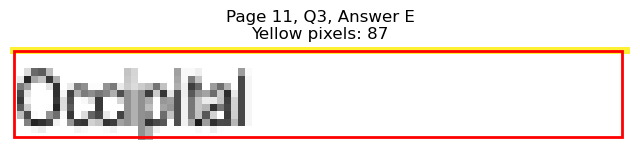


Page 11, Q3 - Selected Answer: D (based on yellow pixel count)




Page 11, Q4 - A: Detected box: x0=85.0, y0=326.1, x1=364.5, y1=338.2
Page 11, Q4, A: Yellow pixels: 0
Page 11, Q4, A: Total non-white pixels: 1383
Page 11, Q4, A: Yellow percentage: 0.0%


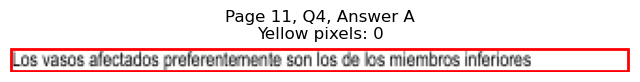

Page 11, Q4 - B: Detected box: x0=85.0, y0=338.1, x1=315.8, y1=350.2
Page 11, Q4, B: Yellow pixels: 0
Page 11, Q4, B: Total non-white pixels: 1164
Page 11, Q4, B: Yellow percentage: 0.0%


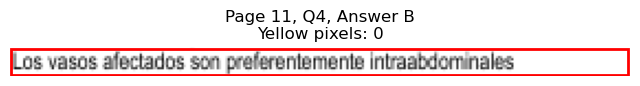

Page 11, Q4 - C: Detected box: x0=85.0, y0=350.2, x1=258.8, y1=362.3
Page 11, Q4, C: Yellow pixels: 0
Page 11, Q4, C: Total non-white pixels: 909
Page 11, Q4, C: Yellow percentage: 0.0%


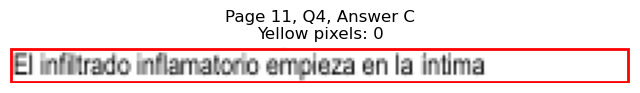

Page 11, Q4 - D: Detected box: x0=85.0, y0=362.2, x1=262.1, y1=374.3
Page 11, Q4, D: Yellow pixels: 229
Page 11, Q4, D: Total non-white pixels: 1138
Page 11, Q4, D: Yellow percentage: 20.1%


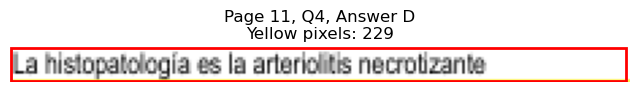

Page 11, Q4 - E: Detected box: x0=85.0, y0=374.2, x1=399.4, y1=386.3
Page 11, Q4, E: Yellow pixels: 3091
Page 11, Q4, E: Total non-white pixels: 4758
Page 11, Q4, E: Yellow percentage: 65.0%


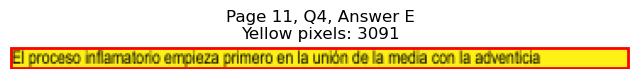


Page 11, Q4 - Selected Answer: E (based on yellow pixel count)




Page 11, Q5 - A: Detected box: x0=85.0, y0=422.4, x1=191.7, y1=434.5
Page 11, Q5, A: Yellow pixels: 0
Page 11, Q5, A: Total non-white pixels: 543
Page 11, Q5, A: Yellow percentage: 0.0%


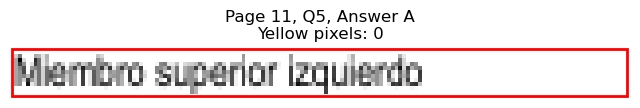

Page 11, Q5 - B: Detected box: x0=85.0, y0=434.4, x1=180.3, y1=446.5
Page 11, Q5, B: Yellow pixels: 0
Page 11, Q5, B: Total non-white pixels: 499
Page 11, Q5, B: Yellow percentage: 0.0%


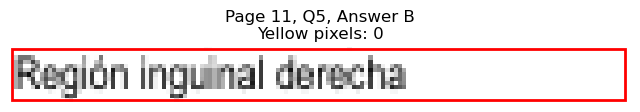

Page 11, Q5 - C: Detected box: x0=85.0, y0=446.6, x1=184.1, y1=458.7
Page 11, Q5, C: Yellow pixels: 0
Page 11, Q5, C: Total non-white pixels: 530
Page 11, Q5, C: Yellow percentage: 0.0%


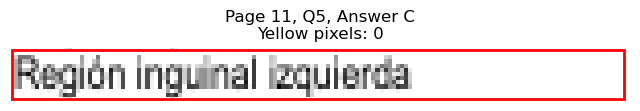

Page 11, Q5 - D: Detected box: x0=336.7, y0=422.4, x1=432.4, y1=434.5
Page 11, Q5, D: Yellow pixels: 147
Page 11, Q5, D: Total non-white pixels: 645
Page 11, Q5, D: Yellow percentage: 22.8%


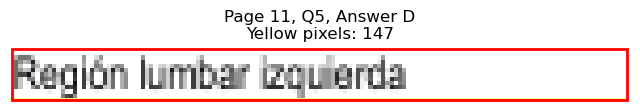

Page 11, Q5 - E: Detected box: x0=336.7, y0=434.4, x1=439.6, y1=446.5
Page 11, Q5, E: Yellow pixels: 1580
Page 11, Q5, E: Total non-white pixels: 2002
Page 11, Q5, E: Yellow percentage: 78.9%


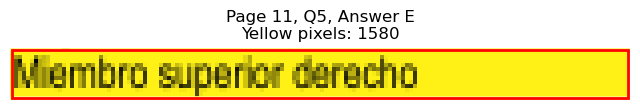


Page 11, Q5 - Selected Answer: E (based on yellow pixel count)




Page 11, Q6 - A: Detected box: x0=85.0, y0=506.8, x1=173.5, y1=518.9
Page 11, Q6, A: Yellow pixels: 1325
Page 11, Q6, A: Total non-white pixels: 1820
Page 11, Q6, A: Yellow percentage: 72.8%


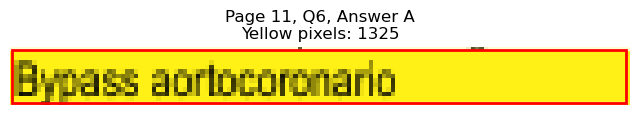

Page 11, Q6 - B: Detected box: x0=85.0, y0=518.8, x1=172.6, y1=530.9
Page 11, Q6, B: Yellow pixels: 135
Page 11, Q6, B: Total non-white pixels: 599
Page 11, Q6, B: Yellow percentage: 22.5%


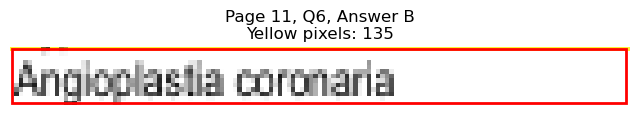

Page 11, Q6 - C: Detected box: x0=85.0, y0=530.9, x1=163.5, y1=543.0
Page 11, Q6, C: Yellow pixels: 0
Page 11, Q6, C: Total non-white pixels: 418
Page 11, Q6, C: Yellow percentage: 0.0%


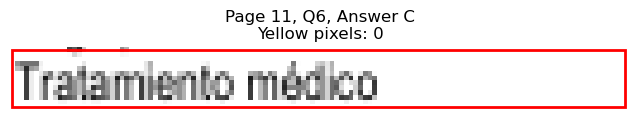

Page 11, Q6 - D: Detected box: x0=336.7, y0=506.8, x1=422.4, y1=518.9
Page 11, Q6, D: Yellow pixels: 0
Page 11, Q6, D: Total non-white pixels: 456
Page 11, Q6, D: Yellow percentage: 0.0%


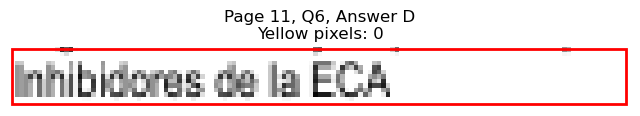

Page 11, Q6 - E: Detected box: x0=336.7, y0=518.8, x1=415.2, y1=530.9
Page 11, Q6, E: Yellow pixels: 0
Page 11, Q6, E: Total non-white pixels: 383
Page 11, Q6, E: Yellow percentage: 0.0%


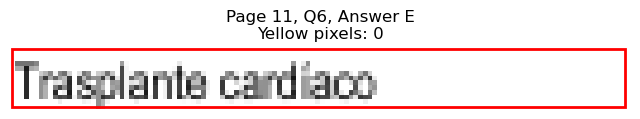


Page 11, Q6 - Selected Answer: A (based on yellow pixel count)




Page 11, Q7 - A: Detected box: x0=85.0, y0=579.1, x1=209.9, y1=591.2
Page 11, Q7, A: Yellow pixels: 0
Page 11, Q7, A: Total non-white pixels: 655
Page 11, Q7, A: Yellow percentage: 0.0%


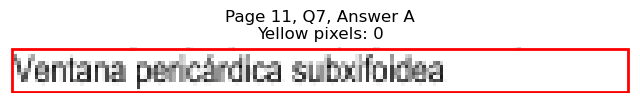

Page 11, Q7 - B: Detected box: x0=85.0, y0=591.2, x1=140.1, y1=603.3
Page 11, Q7, B: Yellow pixels: 0
Page 11, Q7, B: Total non-white pixels: 274
Page 11, Q7, B: Yellow percentage: 0.0%


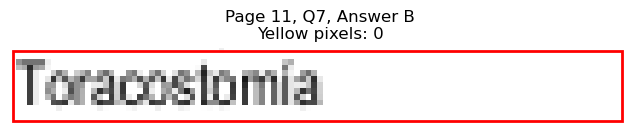

Page 11, Q7 - C: Detected box: x0=85.0, y0=603.2, x1=135.7, y1=615.3
Page 11, Q7, C: Yellow pixels: 0
Page 11, Q7, C: Total non-white pixels: 253
Page 11, Q7, C: Yellow percentage: 0.0%


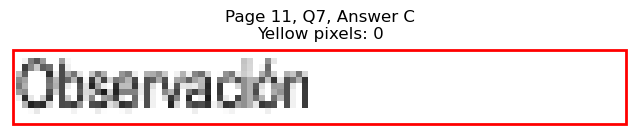

Page 11, Q7 - D: Detected box: x0=336.7, y0=579.1, x1=475.1, y1=591.2
Page 11, Q7, D: Yellow pixels: 1725
Page 11, Q7, D: Total non-white pixels: 2470
Page 11, Q7, D: Yellow percentage: 69.8%


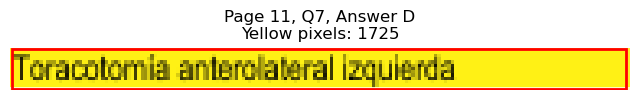

Page 11, Q7 - E: Detected box: x0=336.7, y0=591.2, x1=390.3, y1=603.3
Page 11, Q7, E: Yellow pixels: 0
Page 11, Q7, E: Total non-white pixels: 379
Page 11, Q7, E: Yellow percentage: 0.0%


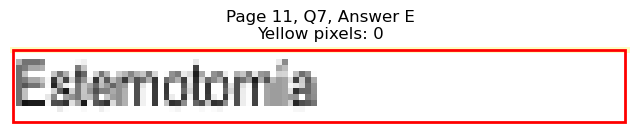


Page 11, Q7 - Selected Answer: D (based on yellow pixel count)




Page 11, Q8 - A: Detected box: x0=85.0, y0=639.3, x1=124.2, y1=651.4
Page 11, Q8, A: Yellow pixels: 1036
Page 11, Q8, A: Total non-white pixels: 1183
Page 11, Q8, A: Yellow percentage: 87.6%


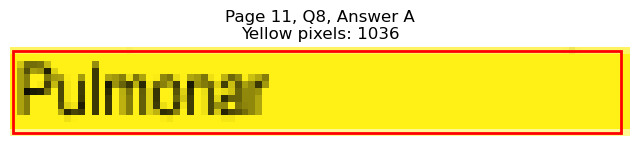

Page 11, Q8 - B: Detected box: x0=85.0, y0=651.4, x1=120.4, y1=663.5
Page 11, Q8, B: Yellow pixels: 87
Page 11, Q8, B: Total non-white pixels: 269
Page 11, Q8, B: Yellow percentage: 32.3%


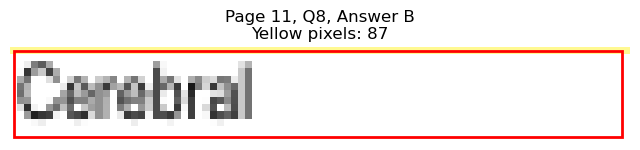

Page 11, Q8 - C: Detected box: x0=85.0, y0=663.4, x1=111.3, y1=675.5
Page 11, Q8, C: Yellow pixels: 0
Page 11, Q8, C: Total non-white pixels: 168
Page 11, Q8, C: Yellow percentage: 0.0%


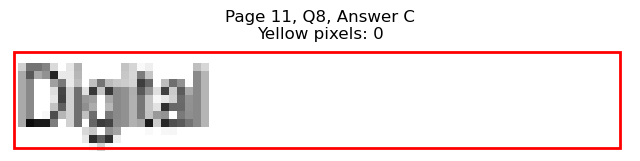

Page 11, Q8 - D: Detected box: x0=336.7, y0=639.3, x1=359.6, y1=651.4
Page 11, Q8, D: Yellow pixels: 0
Page 11, Q8, D: Total non-white pixels: 114
Page 11, Q8, D: Yellow percentage: 0.0%


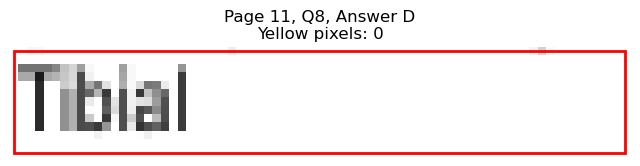

Page 11, Q8 - E: Detected box: x0=336.7, y0=651.4, x1=376.4, y1=663.5
Page 11, Q8, E: Yellow pixels: 0
Page 11, Q8, E: Total non-white pixels: 206
Page 11, Q8, E: Yellow percentage: 0.0%


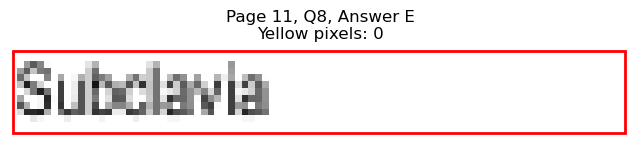


Page 11, Q8 - Selected Answer: A (based on yellow pixel count)




Page 11, Q9 - A: Detected box: x0=85.0, y0=699.5, x1=204.7, y1=711.7
Page 11, Q9, A: Yellow pixels: 0
Page 11, Q9, A: Total non-white pixels: 625
Page 11, Q9, A: Yellow percentage: 0.0%


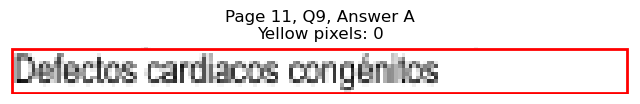

Page 11, Q9 - B: Detected box: x0=85.0, y0=711.7, x1=227.7, y1=723.8
Page 11, Q9, B: Yellow pixels: 0
Page 11, Q9, B: Total non-white pixels: 918
Page 11, Q9, B: Yellow percentage: 0.0%


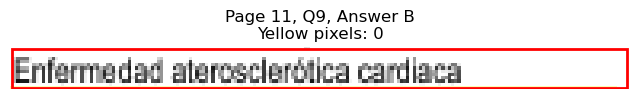

Page 11, Q9 - C: Detected box: x0=85.0, y0=723.7, x1=206.1, y1=735.8
Page 11, Q9, C: Yellow pixels: 1561
Page 11, Q9, C: Total non-white pixels: 2249
Page 11, Q9, C: Yellow percentage: 69.4%


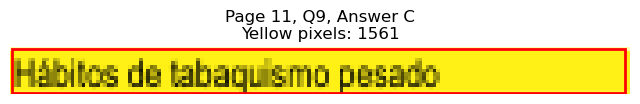

Page 11, Q9 - D: Detected box: x0=336.7, y0=699.5, x1=516.2, y1=711.7
Page 11, Q9, D: Yellow pixels: 0
Page 11, Q9, D: Total non-white pixels: 914
Page 11, Q9, D: Yellow percentage: 0.0%


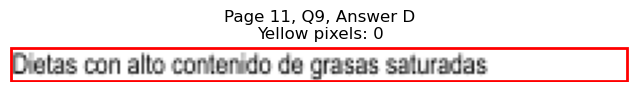

Page 11, Q9 - E: Detected box: x0=336.7, y0=711.7, x1=436.9, y1=723.8
Page 11, Q9, E: Yellow pixels: 0
Page 11, Q9, E: Total non-white pixels: 552
Page 11, Q9, E: Yellow percentage: 0.0%


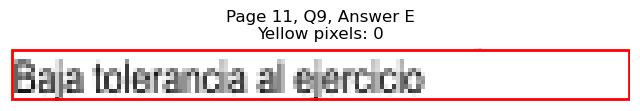


Page 11, Q9 - Selected Answer: C (based on yellow pixel count)





Page 12: Found 8 questions
Page 12, Q1 - A: Detected box: x0=85.0, y0=133.2, x1=210.9, y1=145.3
Page 12, Q1, A: Yellow pixels: 0
Page 12, Q1, A: Total non-white pixels: 641
Page 12, Q1, A: Yellow percentage: 0.0%


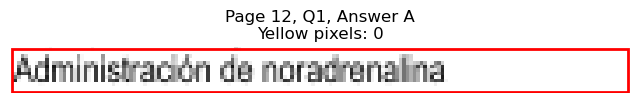

Page 12, Q1 - B: Detected box: x0=85.0, y0=145.3, x1=230.6, y1=157.4
Page 12, Q1, B: Yellow pixels: 1677
Page 12, Q1, B: Total non-white pixels: 2483
Page 12, Q1, B: Yellow percentage: 67.5%


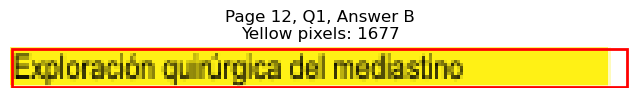

Page 12, Q1 - C: Detected box: x0=85.0, y0=157.3, x1=175.0, y1=169.4
Page 12, Q1, C: Yellow pixels: 1
Page 12, Q1, C: Total non-white pixels: 596
Page 12, Q1, C: Yellow percentage: 0.2%


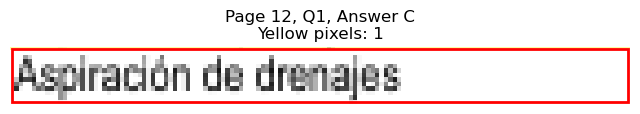

Page 12, Q1 - D: Detected box: x0=336.7, y0=133.2, x1=462.1, y1=145.3
Page 12, Q1, D: Yellow pixels: 0
Page 12, Q1, D: Total non-white pixels: 632
Page 12, Q1, D: Yellow percentage: 0.0%


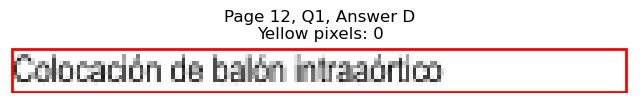

Page 12, Q1 - E: Detected box: x0=336.7, y0=145.3, x1=526.9, y1=157.4
Page 12, Q1, E: Yellow pixels: 0
Page 12, Q1, E: Total non-white pixels: 958
Page 12, Q1, E: Yellow percentage: 0.0%


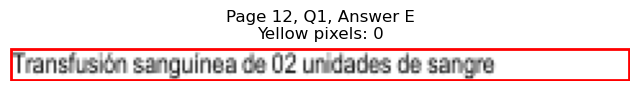


Page 12, Q1 - Selected Answer: B (based on yellow pixel count)




Page 12, Q2 - A: Detected box: x0=85.0, y0=217.5, x1=138.6, y1=229.7
Page 12, Q2, A: Yellow pixels: 0
Page 12, Q2, A: Total non-white pixels: 281
Page 12, Q2, A: Yellow percentage: 0.0%


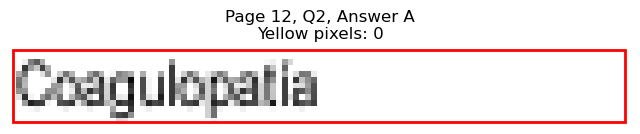

Page 12, Q2 - B: Detected box: x0=85.0, y0=229.7, x1=151.9, y1=241.8
Page 12, Q2, B: Yellow pixels: 1124
Page 12, Q2, B: Total non-white pixels: 1534
Page 12, Q2, B: Yellow percentage: 73.3%


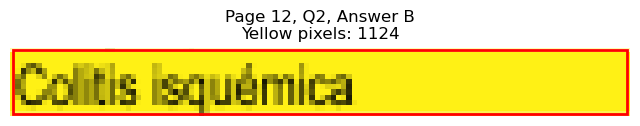

Page 12, Q2 - C: Detected box: x0=85.0, y0=241.7, x1=184.6, y1=253.8
Page 12, Q2, C: Yellow pixels: 150
Page 12, Q2, C: Total non-white pixels: 672
Page 12, Q2, C: Yellow percentage: 22.3%


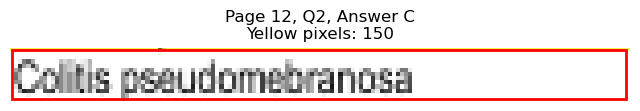

Page 12, Q2 - D: Detected box: x0=336.7, y0=217.5, x1=419.0, y1=229.7
Page 12, Q2, D: Yellow pixels: 0
Page 12, Q2, D: Total non-white pixels: 433
Page 12, Q2, D: Yellow percentage: 0.0%


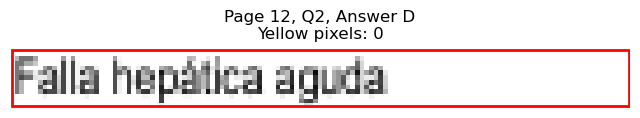

Page 12, Q2 - E: Detected box: x0=336.7, y0=229.7, x1=417.6, y1=241.8
Page 12, Q2, E: Yellow pixels: 0
Page 12, Q2, E: Total non-white pixels: 417
Page 12, Q2, E: Yellow percentage: 0.0%


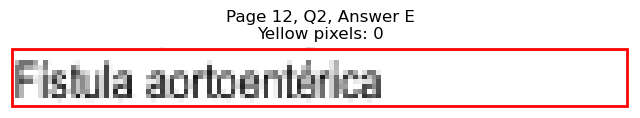


Page 12, Q2 - Selected Answer: B (based on yellow pixel count)




Page 12, Q3 - A: Detected box: x0=85.0, y0=289.9, x1=308.1, y1=302.0
Page 12, Q3, A: Yellow pixels: 0
Page 12, Q3, A: Total non-white pixels: 1118
Page 12, Q3, A: Yellow percentage: 0.0%


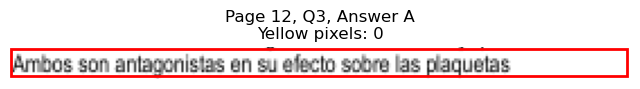

Page 12, Q3 - B: Detected box: x0=85.0, y0=301.9, x1=207.1, y1=314.0
Page 12, Q3, B: Yellow pixels: 0
Page 12, Q3, B: Total non-white pixels: 597
Page 12, Q3, B: Yellow percentage: 0.0%


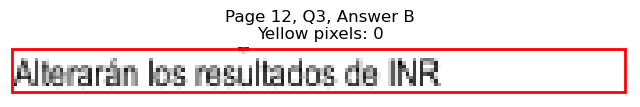

Page 12, Q3 - C: Detected box: x0=85.0, y0=313.9, x1=326.7, y1=326.0
Page 12, Q3, C: Yellow pixels: 0
Page 12, Q3, C: Total non-white pixels: 1160
Page 12, Q3, C: Yellow percentage: 0.0%


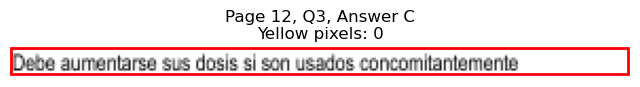

Page 12, Q3 - D: Detected box: x0=85.0, y0=326.1, x1=252.5, y1=338.2
Page 12, Q3, D: Yellow pixels: 219
Page 12, Q3, D: Total non-white pixels: 1072
Page 12, Q3, D: Yellow percentage: 20.4%


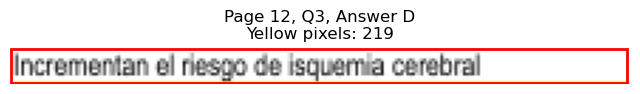

Page 12, Q3 - E: Detected box: x0=85.0, y0=338.1, x1=298.0, y1=350.2
Page 12, Q3, E: Yellow pixels: 2310
Page 12, Q3, E: Total non-white pixels: 3445
Page 12, Q3, E: Yellow percentage: 67.1%


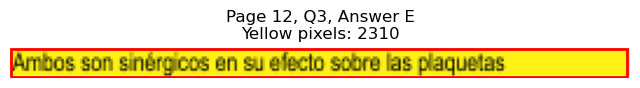


Page 12, Q3 - Selected Answer: E (based on yellow pixel count)




Page 12, Q4 - A: Detected box: x0=85.0, y0=386.3, x1=169.2, y1=398.4
Page 12, Q4, A: Yellow pixels: 1277
Page 12, Q4, A: Total non-white pixels: 1768
Page 12, Q4, A: Yellow percentage: 72.2%


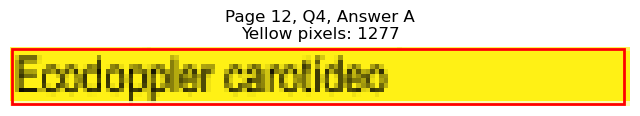

Page 12, Q4 - B: Detected box: x0=85.0, y0=398.3, x1=241.5, y1=410.4
Page 12, Q4, B: Yellow pixels: 0
Page 12, Q4, B: Total non-white pixels: 985
Page 12, Q4, B: Yellow percentage: 0.0%


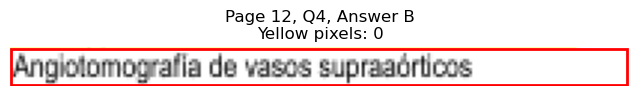

Page 12, Q4 - C: Detected box: x0=85.0, y0=410.4, x1=222.4, y1=422.5
Page 12, Q4, C: Yellow pixels: 0
Page 12, Q4, C: Total non-white pixels: 719
Page 12, Q4, C: Yellow percentage: 0.0%


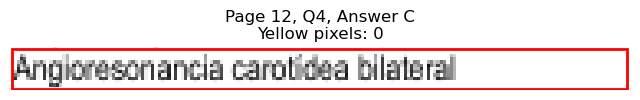

Page 12, Q4 - D: Detected box: x0=336.7, y0=386.3, x1=502.8, y1=398.4
Page 12, Q4, D: Yellow pixels: 0
Page 12, Q4, D: Total non-white pixels: 877
Page 12, Q4, D: Yellow percentage: 0.0%


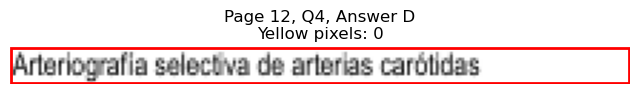

Page 12, Q4 - E: Detected box: x0=336.7, y0=398.3, x1=399.4, y1=410.4
Page 12, Q4, E: Yellow pixels: 0
Page 12, Q4, E: Total non-white pixels: 351
Page 12, Q4, E: Yellow percentage: 0.0%


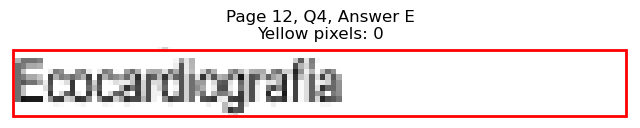


Page 12, Q4 - Selected Answer: A (based on yellow pixel count)




Page 12, Q5 - A: Detected box: x0=85.0, y0=446.6, x1=119.9, y1=458.7
Page 12, Q5, A: Yellow pixels: 975
Page 12, Q5, A: Total non-white pixels: 1118
Page 12, Q5, A: Yellow percentage: 87.2%


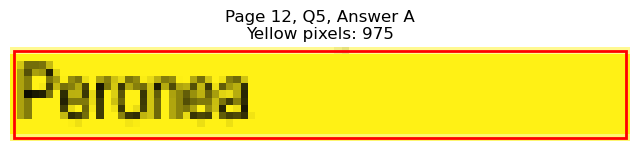

Page 12, Q5 - B: Detected box: x0=85.0, y0=458.6, x1=147.3, y1=470.7
Page 12, Q5, B: Yellow pixels: 114
Page 12, Q5, B: Total non-white pixels: 413
Page 12, Q5, B: Yellow percentage: 27.6%


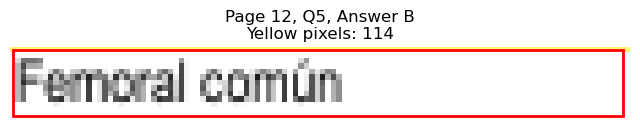

Page 12, Q5 - C: Detected box: x0=85.0, y0=470.7, x1=135.3, y1=482.8
Page 12, Q5, C: Yellow pixels: 0
Page 12, Q5, C: Total non-white pixels: 264
Page 12, Q5, C: Yellow percentage: 0.0%


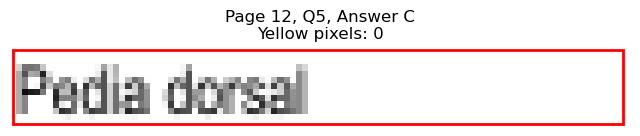

Page 12, Q5 - D: Detected box: x0=336.7, y0=446.6, x1=370.6, y1=458.7
Page 12, Q5, D: Yellow pixels: 0
Page 12, Q5, D: Total non-white pixels: 184
Page 12, Q5, D: Yellow percentage: 0.0%


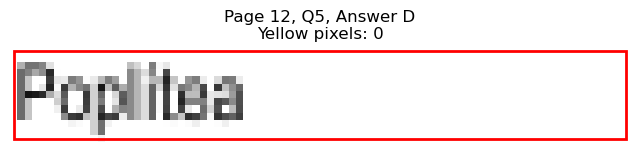

Page 12, Q5 - E: Detected box: x0=336.7, y0=458.6, x1=395.6, y1=470.7
Page 12, Q5, E: Yellow pixels: 0
Page 12, Q5, E: Total non-white pixels: 282
Page 12, Q5, E: Yellow percentage: 0.0%


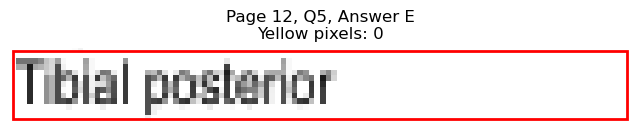


Page 12, Q5 - Selected Answer: A (based on yellow pixel count)




Page 12, Q6 - A: Detected box: x0=85.0, y0=530.9, x1=174.0, y1=543.0
Page 12, Q6, A: Yellow pixels: 1303
Page 12, Q6, A: Total non-white pixels: 1837
Page 12, Q6, A: Yellow percentage: 70.9%


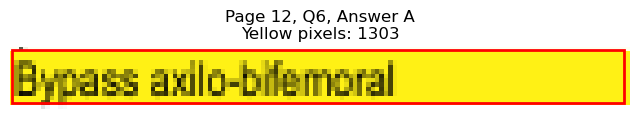

Page 12, Q6 - B: Detected box: x0=85.0, y0=542.9, x1=251.1, y1=555.0
Page 12, Q6, B: Yellow pixels: 186
Page 12, Q6, B: Total non-white pixels: 1035
Page 12, Q6, B: Yellow percentage: 18.0%


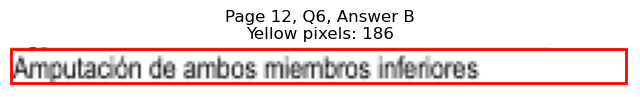

Page 12, Q6 - C: Detected box: x0=85.0, y0=554.9, x1=252.1, y1=567.0
Page 12, Q6, C: Yellow pixels: 0
Page 12, Q6, C: Total non-white pixels: 883
Page 12, Q6, C: Yellow percentage: 0.0%


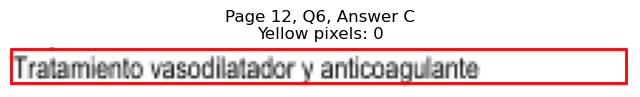

Page 12, Q6 - D: Detected box: x0=336.7, y0=530.9, x1=427.6, y1=543.0
Page 12, Q6, D: Yellow pixels: 0
Page 12, Q6, D: Total non-white pixels: 477
Page 12, Q6, D: Yellow percentage: 0.0%


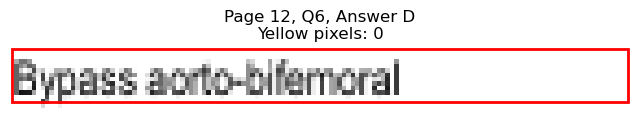

Page 12, Q6 - E: Detected box: x0=336.7, y0=542.9, x1=472.7, y1=555.0
Page 12, Q6, E: Yellow pixels: 0
Page 12, Q6, E: Total non-white pixels: 704
Page 12, Q6, E: Yellow percentage: 0.0%


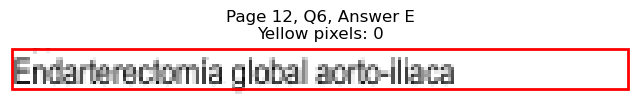


Page 12, Q6 - Selected Answer: A (based on yellow pixel count)




Page 12, Q7 - A: Detected box: x0=85.0, y0=639.3, x1=119.9, y1=651.4
Page 12, Q7, A: Yellow pixels: 0
Page 12, Q7, A: Total non-white pixels: 181
Page 12, Q7, A: Yellow percentage: 0.0%


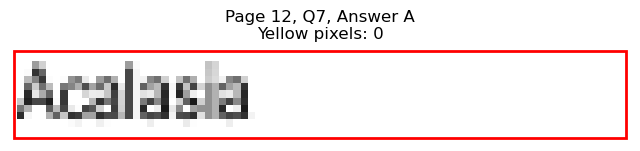

Page 12, Q7 - B: Detected box: x0=85.0, y0=651.4, x1=153.5, y1=663.5
Page 12, Q7, B: Yellow pixels: 0
Page 12, Q7, B: Total non-white pixels: 319
Page 12, Q7, B: Yellow percentage: 0.0%


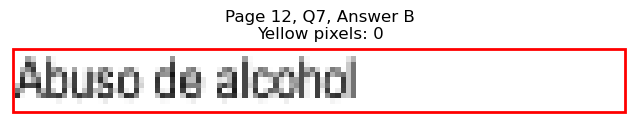

Page 12, Q7 - C: Detected box: x0=85.0, y0=663.4, x1=134.8, y1=675.5
Page 12, Q7, C: Yellow pixels: 0
Page 12, Q7, C: Total non-white pixels: 248
Page 12, Q7, C: Yellow percentage: 0.0%


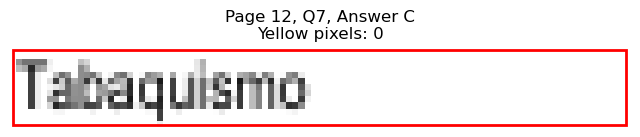

Page 12, Q7 - D: Detected box: x0=336.7, y0=639.3, x1=408.4, y1=651.4
Page 12, Q7, D: Yellow pixels: 1296
Page 12, Q7, D: Total non-white pixels: 1599
Page 12, Q7, D: Yellow percentage: 81.1%


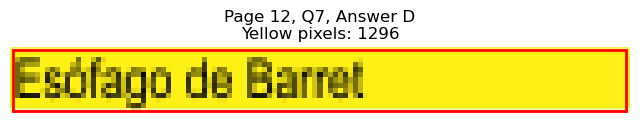

Page 12, Q7 - E: Detected box: x0=336.7, y0=651.4, x1=404.2, y1=663.5
Page 12, Q7, E: Yellow pixels: 119
Page 12, Q7, E: Total non-white pixels: 503
Page 12, Q7, E: Yellow percentage: 23.7%


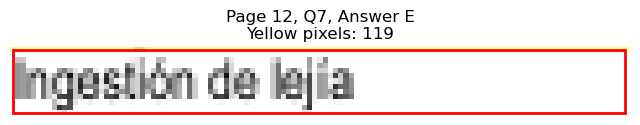


Page 12, Q7 - Selected Answer: D (based on yellow pixel count)




Page 12, Q8 - A: Detected box: x0=85.0, y0=699.5, x1=358.3, y1=711.7
Page 12, Q8, A: Yellow pixels: 3146
Page 12, Q8, A: Total non-white pixels: 4225
Page 12, Q8, A: Yellow percentage: 74.5%


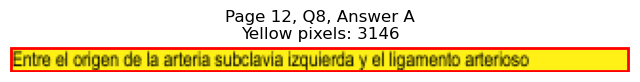

Page 12, Q8 - B: Detected box: x0=85.0, y0=711.7, x1=245.8, y1=723.8
Page 12, Q8, B: Yellow pixels: 212
Page 12, Q8, B: Total non-white pixels: 958
Page 12, Q8, B: Yellow percentage: 22.1%


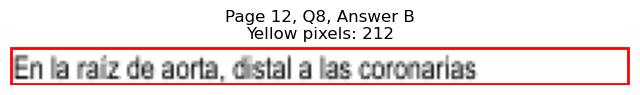

Page 12, Q8 - C: Detected box: x0=85.0, y0=723.7, x1=180.7, y1=735.8
Page 12, Q8, C: Yellow pixels: 0
Page 12, Q8, C: Total non-white pixels: 477
Page 12, Q8, C: Yellow percentage: 0.0%


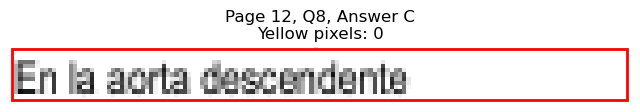

Page 12, Q8 - D: Detected box: x0=85.0, y0=735.8, x1=265.5, y1=747.9
Page 12, Q8, D: Yellow pixels: 0
Page 12, Q8, D: Total non-white pixels: 871
Page 12, Q8, D: Yellow percentage: 0.0%


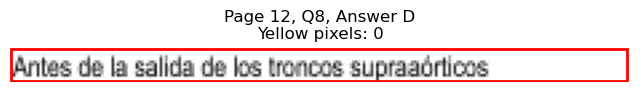

Page 12, Q8 - E: Detected box: x0=85.0, y0=747.8, x1=347.8, y1=759.9
Page 12, Q8, E: Yellow pixels: 0
Page 12, Q8, E: Total non-white pixels: 1328
Page 12, Q8, E: Yellow percentage: 0.0%


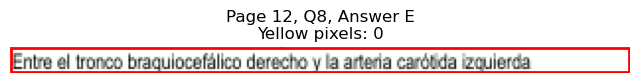


Page 12, Q8 - Selected Answer: A (based on yellow pixel count)






In [6]:
questions_df = extract_questions(pdf_path = pdf_file)
answers_df = extract_answers(pdf_path = pdf_file)
correct_answers_df = extract_correct_answers(pdf_path = pdf_file)

In [7]:
questions_df

,question
0,"Paciente de 45 años, con talla de 170 cm y 70 ..."
1,¿Cuál es la estructura que se lesiona con mayo...
2,"Mujer de 72 años, referida por tos hace 6 sema..."
3,Paciente de 65 años con antecedente de tres in...
4,El principal aminoácido neurotransmisor implic...
...,...
95,"Durante la auscultación, como parte del examen..."
96,¿Cuál de las siguientes arterias NO se puede p...
97,"Paciente de 85 años, con alto riesgo quirúrgic..."
98,Paciente de 68 años sometido a triple bypass a...


In [8]:
answers_df

,option_A,option_B,option_C,option_D,option_E
0,Conducta expectante por una hora,Realización de estudios de perfil de coagulación,Transfusión de componentes sanguíneos como con...,Administrar protamina y ácido tranexámico,Retorno a sala de operaciones para reesternoto...
1,Ventrículo izquierdo,Aurícula derecha,Ventrículo derecho,Aurícula izquierda,Aorta
2,Quimioterapia.,Biopsia pleural cerrada.,Resección quirúrgica de la masa,Toracocentesis y citología,Toracoscopia
3,Aneurismorrafía + revascularización + cambio m...,Cirugía de Door + revascularización de miocard...,Trasplante cardiaco,Cirugía de Door + revascularización de miocardio,Cirugía de Door + plastia mitral + revasculari...
4,Metionina,Glutamato,Prolina,Histidina,Glicina
...,...,...,...,...,...
95,Ecodoppler carotídeo,Angiotomografía de vasos supraaórticos,Angioresonancia carotídea bilateral,Arteriografía selectiva de arterias carótidas,Ecocardiografía
96,Peronea,Femoral común,Pedia dorsal,Poplítea,Tibial posterior
97,Bypass axilo-bifemoral,Amputación de ambos miembros inferiores,Tratamiento vasodilatador y anticoagulante,Bypass aorto-bifemoral,Endarterectomía global aorto-iliaca
98,Acalasia,Abuso de alcohol,Tabaquismo,Esófago de Barret,Ingestión de lejía


In [9]:
correct_answers_df

,correct_answer
0,E
1,C
2,D
3,E
4,B
...,...
95,A
96,A
97,A
98,D


In [10]:
total_df = pd.concat([questions_df, answers_df, correct_answers_df], ignore_index = True, axis = 1)
total_df.columns = ["questions", "option_A", "option_B", "option_C", "option_D", "option_E", "correct_answer"]
total_df

,questions,option_A,option_B,option_C,option_D,option_E,correct_answer
0,"Paciente de 45 años, con talla de 170 cm y 70 ...",Conducta expectante por una hora,Realización de estudios de perfil de coagulación,Transfusión de componentes sanguíneos como con...,Administrar protamina y ácido tranexámico,Retorno a sala de operaciones para reesternoto...,E
1,¿Cuál es la estructura que se lesiona con mayo...,Ventrículo izquierdo,Aurícula derecha,Ventrículo derecho,Aurícula izquierda,Aorta,C
2,"Mujer de 72 años, referida por tos hace 6 sema...",Quimioterapia.,Biopsia pleural cerrada.,Resección quirúrgica de la masa,Toracocentesis y citología,Toracoscopia,D
3,Paciente de 65 años con antecedente de tres in...,Aneurismorrafía + revascularización + cambio m...,Cirugía de Door + revascularización de miocard...,Trasplante cardiaco,Cirugía de Door + revascularización de miocardio,Cirugía de Door + plastia mitral + revasculari...,E
4,El principal aminoácido neurotransmisor implic...,Metionina,Glutamato,Prolina,Histidina,Glicina,B
...,...,...,...,...,...,...,...
95,"Durante la auscultación, como parte del examen...",Ecodoppler carotídeo,Angiotomografía de vasos supraaórticos,Angioresonancia carotídea bilateral,Arteriografía selectiva de arterias carótidas,Ecocardiografía,A
96,¿Cuál de las siguientes arterias NO se puede p...,Peronea,Femoral común,Pedia dorsal,Poplítea,Tibial posterior,A
97,"Paciente de 85 años, con alto riesgo quirúrgic...",Bypass axilo-bifemoral,Amputación de ambos miembros inferiores,Tratamiento vasodilatador y anticoagulante,Bypass aorto-bifemoral,Endarterectomía global aorto-iliaca,A
98,Paciente de 68 años sometido a triple bypass a...,Acalasia,Abuso de alcohol,Tabaquismo,Esófago de Barret,Ingestión de lejía,D


In [11]:
# Extract folder path
folder_path = os.path.dirname(pdf_file)  # Gets the directory path

# Extract filename without extension
file_name = os.path.splitext(os.path.basename(pdf_file))[0]  # Removes the .pdf extension

# Create CSV file path
csv_file = os.path.join(folder_path, f"{file_name}.csv")

# Save a sample DataFrame
total_df.to_csv(csv_file, index=False, encoding="utf-8-sig")
print(f"CSV saved at: {csv_file}")


CSV saved at: /Users/rodrigocarrillo/Library/CloudStorage/OneDrive-EmoryUniversity/Natural Language Processing Projects/Examen Residentado Peru/CONAREME/Year2019/CIRUGÍA CARDIOVASCULAR.csv
